In [1]:
# import the most important libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import os


In [2]:
dt_name = "diamond_1_hot"
dt_name = 'dry_bean'
dt_name = "adult_TargEncoded"
exp_path = os.path.join("Experiments",dt_name)

feat_names_f = dt_name+"_names.txt"
# inside the file there are the names of the features separated by a comma
feat_names_f = os.path.join(exp_path,feat_names_f)
with open(feat_names_f,"r") as f:
    feat_names = f.read().split(",")
print(feat_names)
# using the map function to trim the names
feat_names = list(map(lambda x: x.strip(),feat_names))
print(feat_names)


['age', ' capital-gain', ' capital-loss', ' hours-per-week', ' workclass', ' education', ' marital-status', ' occupation', ' relationship', ' race', ' sex', ' native-country']
['age', 'capital-gain', 'capital-loss', 'hours-per-week', 'workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


In [3]:

exps = sorted(os.listdir(exp_path))
# load the name of the features
# include in exps only the names of the folders that have 3 digits in the beginning
exps = [exp for exp in exps if exp[:3].isdigit()]
exps

['012_iid',
 '012_imb_0.99',
 '012_imb_5.0',
 '016_iid',
 '016_imb_0.99',
 '016_imb_5.0']

In [4]:
import importlib
import iflash as flx
from iflash import *
#
importlib.reload(flx)


In [5]:
# the following function is used to load the model, and measure the f1 score on the test set. It returns the f1 score 
# the model is a pytorch model, namely a ModularNet from src.NeuralNetworks.
# the 
import torch
from src.utils import load_partition,load_test_partitions, load_train_partitions
from sklearn.metrics import f1_score

def load_model(path_folder):
    ''' function to load the model
    '''
    models = sorted(os.listdir(path_folder))
    models = [model for model in models if model.endswith("model.pth")]
    print("models found:",models)
    model = models[-1]
    print("choosing:",model)
    return torch.load(os.path.join(path_folder,model))

def get_dt_name_nc_d(hp_search):
    '''This function is used to extract the 
    dataset name, the number of clients
    and the distribution from the sweep name'''
    # last element is iid or a number
    # if it is a number and such number i > 110 distr is iid
    last = hp_search.split("_")[-1]
    hp_search = hp_search.split("_")
    # we use the bitwise or to avoid the exception if last is not a number
    if last == "iid":
        distr = "iid"
        nc = hp_search[-2]
        dt_name = "_".join(hp_search[1:-2])
    elif float(last) > 110:
        distr = "iid"
        nc = hp_search[-3]
        dt_name = "_".join(hp_search[1:-3])
    elif float(last) < 110:
        distr = "imb_"+hp_search[-1]
        if hp_search[-1]=="_5":
            distr+=".0"
        nc = hp_search[-3]
        dt_name = "_".join(hp_search[1:-3])
    
    return dt_name,int(nc),distr

def get_f1(dt_name,model,client_id,num_clients,distribution,macro=False):
    tr_set,te_set = load_partition(dt_name, client_id, num_clients,distribution)
    #te_loader = create_dataloader(te_set, batch_size=64, shuffle=False)
    return f1_score(
                tr_set.tensors[1].argmax(dim=1),
                model(tr_set.tensors[0]).argmax(dim=1), average=('macro' if macro else 'weighted'))

def get_f1_whole(dt_name,model,client_id,num_clients,distribution,macro=False):
    ''' load the whole test set and get the f1 score'''
    te_set = load_test_partitions(dt_name, num_clients,distribution)
    #te_loader = create_dataloader(te_set, batch_size=64, shuffle=False)
    return f1_score(
                te_set.tensors[1].argmax(dim=1),
                model(te_set.tensors[0]).argmax(dim=1), average=('macro' if macro else 'weighted'))





CUDA available: Yes
using: cuda


In [6]:
#test the get_f1 function

#E_fait_weighted_in50_percentile

model = load_model(os.path.join("Experiments",dt_name,"012_imb_5.0","models"))
s_o = 0
for i in range(1,12):
    s=get_f1(dt_name,model,i,12,"imb_5.0")
    print(i,s)
    
print(get_f1_whole(dt_name,model,0,12,"imb_5.0")),s_o/12
for i in range(1,12):
    s=get_f1(dt_name,model,i,12,"imb_5.0")
    print(i,s)
print(get_f1_whole(dt_name,model,0,12,"imb_5.0")),s_o//12

for i in range(1,12):
    s=get_f1(dt_name,model,i,16,"imb_5.0")
    print(i,s)
print(get_f1_whole(dt_name,model,0,16,"imb_5.0")),s_o/16

models found: ['twilight-night-375_model.pth']
choosing: twilight-night-375_model.pth
1 0.8316272315310871
2 0.856202883053197
3 0.8342600807931883
4 0.797278089385328
5 0.8248820703289671
6 0.8156676005091685
7 0.8805512264406491
8 0.838266728755433
9 0.8550318207927502
10 0.8532670203844156
11 0.8429735883855849
0.8394659668428726
1 0.8316272315310871
2 0.856202883053197
3 0.8342600807931883
4 0.797278089385328
5 0.8248820703289671
6 0.8156676005091685
7 0.8805512264406491
8 0.838266728755433
9 0.8550318207927502
10 0.8532670203844156
11 0.8429735883855849
0.8394659668428726
1 0.7798828169598502
2 0.8382714634093448
3 0.850350543991841
4 0.7905561446522257
5 0.8869049506016777
6 0.8039779277138426
7 0.9201993695011802
8 0.8081804891015418
9 0.8556279204900371
10 0.853096901725947
11 0.8093967955947041
0.8447707042267004


(None, 0.0)

In [7]:

def order_names(experiment_names):
    # order the names of the experiments
    # order according to the distribution, iid is the first,
    # then the others follow based on the last float number, INCREASING
    # then order according to the number of clients
    # group the names according to the # of clients
    # then order the names inside each group

    # substitute the iid with 100
    experiment_names = [exp.replace("iid","imb_100.0") for exp in experiment_names]
     # order according to the distribution, iid is the first,
    # then the others follow based on the last float number, INCREASING
    # but keep the order of the number of clients, Increasing
    experiment_names = sorted(experiment_names, key=lambda x: (-int(x.split("_")[0]),float(x.split("_")[-1])),reverse=True)
    # substitute the imb_100.0 with iid
    experiment_names = [exp.replace("imb_100.0","iid") for exp in experiment_names]
    return experiment_names

    
    
exps = order_names(exps)

In [8]:
exps 
exps = [exp for exp in exps if "0.5" not in exp]

In [9]:
feat_names

['age',
 'capital-gain',
 'capital-loss',
 'hours-per-week',
 'workclass',
 'education',
 'marital-status',
 'occupation',
 'relationship',
 'race',
 'sex',
 'native-country']

In [11]:
# check the content of the folder "shap" within each folder of exps
all_shap_values_dict = {}
all_weights_dict = {}
success_exps = []
explainer_folder_name = "sampled_shap"
explainer_folder_name = "shap"

explainer_values_name = "shap_values"
for exp in exps:
    print(exp)
    shap_path = os.path.join(exp_path,exp,explainer_folder_name)
    model_path = os.path.join(exp_path,exp,"models")
    
    dt,nc,distr = get_dt_name_nc_d(exp)
    neural_model = load_model(model_path)
    expl = os.listdir(shap_path)

    print(len(expl))
    # there are the npz files and the txt files
    # the npz files contain the shap values
    # the txt files contain the times

    shap_values_dict = {k:[] for k in ["Server","Clients"]}
    f1_scores_dict = {k:[] for k in ["Server","Clients"]}
    f1_MACRO_scores_dict = {k:[] for k in ["Server","Clients"]}
    if len(expl)>0:
        # get only the npz files
        expl = [f for f in expl if f[-3:]=="npz" and f[:4].lower()!="comp"]
        print(len(expl))
        print(expl)
        # load the shap values
        expl = sorted(expl)

        for i,f in enumerate(expl):
            if i == 0:
                key="Server"
            else:
                key="Clients"
            #shap_values_dict[key] = []
            shap_values = np.load(os.path.join(shap_path,f))
            #print(shap_values.files)
            shap_values = shap_values[explainer_values_name]

            

            # insert the shap values in the dictionary
            # if is the client append them to the previous ones and save them in the dictionary
            if key=="Server":
                shap_values_dict[key] = shap_values
                f1_scores_dict[key] = get_f1_whole(dt_name=dt_name,
                                                   model=neural_model,
                                                   client_id=0,
                                                   num_clients=nc,
                                                   distribution=distr)
                f1_MACRO_scores_dict[key] = get_f1_whole(dt_name=dt_name, model=neural_model, client_id=0,
                                                         num_clients=nc,distribution=distr,macro=True)
                                                         
            else:
                shap_values_dict[key] = shap_values_dict[key] + [shap_values]
                f1_scores_dict[key] = f1_scores_dict[key]+ [get_f1(dt_name=dt_name,
                                                                   model=neural_model,
                                                                   client_id=i,
                                                                     num_clients=nc,
                                                                     distribution=distr)]
                #f1_scores_dict[key] = f1_scores_dict[key]+ [get_f1(dt_name=dt_name,
                #                             model=neural_model,
                #                             client_id=,
                #                             num_)
                f1_MACRO_scores_dict[key] = f1_MACRO_scores_dict[key]+ [get_f1(dt_name=dt_name,
                                                                     model=neural_model,
                                                                     client_id=i,
                                                                    num_clients=nc,
                                                                    distribution=distr,
                                                                      macro=True)]




        # convert the list of shap values of the clients in a numpy array
        #print(shap_values_dict["Clients"])
        shap_values_dict["Clients"] = np.array(shap_values_dict["Clients"])
        # compute E_hat as the mean of the shap values of the clients retaining the same shape
        shap_values_dict["E_hat"] = np.mean(shap_values_dict["Clients"],axis=0)
        # compute the weighted mean of the shap values of the clients, based on the f1 scores
        f1_weights = np.array(f1_scores_dict["Clients"])
        f1_MACRO_weights = np.array(f1_MACRO_scores_dict["Clients"])
        
        shap_values_dict["E_weighted"] = np.average(shap_values_dict["Clients"],axis=0,weights=f1_weights)

        shap_values_dict["E_f1_macro"] = np.average(shap_values_dict["Clients"],axis=0,weights=f1_MACRO_weights)



        #shap_values_dict["E_weighted"] = np.average(shap_values_dict["Clients"],axis=0,weights=weights)
        # compute the difference between the server and the mean of the clients
        #print((shap_values_dict["E_weighted"] - shap_values_dict["E_hat"]).mean())
        shap_values_dict["Delta"] = shap_values_dict["Server"] - shap_values_dict["E_hat"]
        shap_values_dict["Delta_weighted"] = shap_values_dict["Server"] - shap_values_dict["E_weighted"]
        
        shap_values_dict["Delta_macro_weighted"] = shap_values_dict["Server"] - shap_values_dict["E_f1_macro"]
    # save the dictionary
        all_weights_dict[exp] = f1_weights
        all_weights_dict[exp+"_macro"] = f1_MACRO_weights
        all_shap_values_dict[exp] = shap_values_dict

        success_exps.append(exp)

delta_means = []

for exp in success_exps:
    shap_values_dict = all_shap_values_dict[exp]
    #title = dt_name+"\n"+" ".join(exp.split("_"))
    # get the mean of the delta columns and save them in a list
    delta_abs = np.abs(shap_values_dict["Delta"])
    delta_col = np.mean(delta_abs,axis=0)
    # take the absolute value of the mean of the delta columns and do the mean
    delta_means.append(np.mean(np.abs(delta_col)))


    #delta_means.append(np.mean(shap_values_dict["Delta"]))

#plt.figure(figsize=(10,5))
#plt.barh(np.arange(len(delta_means)),np.abs(delta_means))
#plt.yticks(np.arange(len(delta_means)),success_exps)

delta_means = np.abs(delta_means)


012_iid
models found: ['rich-pyramid-373_model.pth']
choosing: rich-pyramid-373_model.pth
30
13
['shap_C_012.npz', 'shap_C_009.npz', 'shap_C_002.npz', 'shap_C_003.npz', 'shap_C_004.npz', 'shap_C_000.npz', 'shap_C_001.npz', 'shap_C_007.npz', 'shap_C_005.npz', 'shap_C_008.npz', 'shap_C_010.npz', 'shap_C_006.npz', 'shap_C_011.npz']
012_imb_5.0
models found: ['twilight-night-375_model.pth']
choosing: twilight-night-375_model.pth
30
13
['shap_C_012.npz', 'shap_C_009.npz', 'shap_C_002.npz', 'shap_C_003.npz', 'shap_C_004.npz', 'shap_C_000.npz', 'shap_C_001.npz', 'shap_C_007.npz', 'shap_C_005.npz', 'shap_C_008.npz', 'shap_C_010.npz', 'shap_C_006.npz', 'shap_C_011.npz']
012_imb_0.99
models found: ['fallen-durian-374_model.pth']
choosing: fallen-durian-374_model.pth
30
13
['shap_C_012.npz', 'shap_C_009.npz', 'shap_C_002.npz', 'shap_C_003.npz', 'shap_C_004.npz', 'shap_C_000.npz', 'shap_C_001.npz', 'shap_C_007.npz', 'shap_C_005.npz', 'shap_C_008.npz', 'shap_C_010.npz', 'shap_C_006.npz', 'shap_C_01

### A plot about the differences 

In [12]:
'''    
closer_to_wighted = 0
cases = []
for j,exp in enumerate(success_exps):
    shap_values_dict = all_shap_values_dict[exp]
    title = dt_name+"\n"+" ".join(exp.split("_"))
    print(all_weights_dict[exp])
    diff_hat = compare_heatmaps(shap_values_dict["Server"],shap_values_dict["E_hat"])
    diff_weighted = compare_heatmaps(shap_values_dict["Server"],shap_values_dict["E_weighted"])
    print("E_S is closer to", ("E_hat" if diff_hat<diff_weighted else "E_weighted"),"diff_hat",np.round(diff_hat,2),"diff_weighted",np.round(diff_weighted,2))
    if diff_hat<diff_weighted:
        closer_to_wighted+=1
        cases.append(exp)
    diff_hat_w = compare_heatmaps(shap_values_dict["E_hat"],shap_values_dict["E_weighted"])
    diff_hat_w_macro = compare_heatmaps(shap_values_dict["E_hat"],shap_values_dict["E_f1_macro"])
    diff_w_w_macro = compare_heatmaps(shap_values_dict["E_weighted"],shap_values_dict["E_f1_macro"])
    print(("difference between the mean of the clients and the weighted mean").upper(),diff_hat_w)
    print(("difference between the mean of the clients and the weighted mean (macro)").upper(),diff_hat_w_macro)
    print(("difference between the weighted mean and the weighted mean (macro)").upper(),diff_w_w_macro)

    plot_heatmap_and_focus(shap_values_dict["Delta"],feat_names=feat_names,
                            shap_val_dict=shap_values_dict,
                           title=title,vmin=-0.035,vmax=0.035,
                           all_means=delta_means,idx=j,names_exp=success_exps)
    # check if E_S is closer to E_hat or E_weighted
    
    plt.tight_layout()
    plt.show()

    plt.close()
print("E_S is closer to E_weighted",closer_to_wighted,"times", "out of",len(success_exps),"times")
print("cases:",cases)
    '''

'    \ncloser_to_wighted = 0\ncases = []\nfor j,exp in enumerate(success_exps):\n    shap_values_dict = all_shap_values_dict[exp]\n    title = dt_name+"\n"+" ".join(exp.split("_"))\n    print(all_weights_dict[exp])\n    diff_hat = compare_heatmaps(shap_values_dict["Server"],shap_values_dict["E_hat"])\n    diff_weighted = compare_heatmaps(shap_values_dict["Server"],shap_values_dict["E_weighted"])\n    print("E_S is closer to", ("E_hat" if diff_hat<diff_weighted else "E_weighted"),"diff_hat",np.round(diff_hat,2),"diff_weighted",np.round(diff_weighted,2))\n    if diff_hat<diff_weighted:\n        closer_to_wighted+=1\n        cases.append(exp)\n    diff_hat_w = compare_heatmaps(shap_values_dict["E_hat"],shap_values_dict["E_weighted"])\n    diff_hat_w_macro = compare_heatmaps(shap_values_dict["E_hat"],shap_values_dict["E_f1_macro"])\n    diff_w_w_macro = compare_heatmaps(shap_values_dict["E_weighted"],shap_values_dict["E_f1_macro"])\n    print(("difference between the mean of the clients an

In [13]:
exp_path

'Experiments/adult_TargEncoded'

In [14]:
from src.wandb_analysis import get_dt_name_nc_d

In [15]:
focus = ["016_imb_0.99","016_imb_5.0","016_iid",
         "012_imb_0.99","012_imb_5.0","012_iid"]
['008_imb_0.99',
         "008_imb_5.0",
         '008_iid']
         #'004_imb_0.99',
         #"004_imb_5.0",
         #'004_iid',
         #]

focus

['016_imb_0.99',
 '016_imb_5.0',
 '016_iid',
 '012_imb_0.99',
 '012_imb_5.0',
 '012_iid']

In [16]:
import os
import time
import numpy as np

from src.utils import load_test_partitions,create_dataloader
from src.dataset_utils import ordinal_encoding,cap_dataset
def compute_faithfulness(exp, all_shap_values_dict, base_value):
    model_path = os.path.join(exp_path, exp, "models")
    neural_model = load_model(model_path)

    shap_values_dict = all_shap_values_dict[exp]
    model = aix_model(neural_model)
    _, num_clients, distribution = get_dt_name_nc_d(exp)
    partitions_te_set = load_test_partitions(dt_name, num_clients, distribution)
    loader_explain, _ = create_dataloader(ordinal_encoding(
                                            cap_dataset((partitions_te_set.tensors[0],
                                                        partitions_te_set.tensors[1]),
                                                        2000)
                                            ),batch_size=32, shuffle=False)
    
    explanation_set = np.load(os.path.join("Experiments",dt_name,"explanation_set.npz"))
    # create the dataloader transforming the dataset in a tensor dataset
    explan_dataset = torch.utils.data.TensorDataset(torch.Tensor(explanation_set['features']),
                                                    torch.Tensor(explanation_set['labels']))
    loader_explain, _ = create_dataloader(ordinal_encoding(explan_dataset),batch_size=32, shuffle=False)
    
    # now re-get the test set as tensor
    te_set = loader_explain.dataset
    # for every class get the indices of the samples so that we can return the indexes of the samples of that class
    class_idxs = []
    num_classes = partitions_te_set.tensors[1].shape[1]
    for i in range(num_classes):
        class_idxs.append(np.where(te_set.tensors[1] == i)[0])
    x = te_set.tensors[0].numpy()
    
    faith_dict = {"Server": [], "Clients": []}

    activations = model.predict_proba(x)
    print(activations.shape)
    for client_id in range(num_clients + 1):
        if client_id == 0:
            key = "Server"
            coefs = shap_values_dict[key]
        else:
            key = "Clients"
            coefs = shap_values_dict[key][client_id - 1]

        
        faits = []
        num_samples = 2000

        for sample, fi in zip(x[:num_samples], coefs[:num_samples]):
            faith_m = faithfulness_metric(model=model,
                                          x=sample,
                                          coefs=fi,
                                          base=base_value * np.ones(shape=fi.shape[0]),
                                          )
            
            faits.append(faith_m)

        faith_dict[key].append(np.array(faits))

    return class_idxs,faith_dict,activations
# test it
#idxs,fais,activas = compute_faithfulness(exp,all_shap_values_dict,base_value)


In [17]:

exp = "012_imb_0.99"

#idxs,fais,activas = recalculate_faiths(exp,all_shap_values_dict,base_value,["E_hat","E_weighted"])


In [18]:
for k,v in all_shap_values_dict.items():
    for k2,v2 in v.items():
        #print(k,k2,v2.shape[0])
        if k2 == "Clients":
            if v2.shape[0] != int(k[:3]):
                print(k,v2.shape)

In [19]:

def get_exps_faiths(exp,base_values):
    results_dict = {}
    activas = {}
    for b_v in base_values:
        indexes,results_dict[b_v],activas[b_v] = compute_faithfulness(exp,all_shap_values_dict,b_v)

        print("Base value:",b_v)
        gt0 = (np.array(results_dict[b_v]["Server"])>0).sum()/len(results_dict[b_v]["Server"][0])
        gt7 = (np.array(results_dict[b_v]["Server"])>0.7).sum()/len(results_dict[b_v]["Server"][0])
        gt0Clients = []
        gt7Clients = []
        for i in range(len(results_dict[b_v]["Clients"])):
            gt0Clients.append((np.array(results_dict[b_v]["Clients"][i])>0).sum()/len(results_dict[b_v]["Clients"][i]))
            gt7Clients.append((np.array(results_dict[b_v]["Clients"][i])>0.7).sum()/len(results_dict[b_v]["Clients"][i]))
        print("Server:")
        print("\t>0:",gt0," \t\t>0.7:",gt7)
        print("Clients:")
        for i in range(len(gt0Clients)):
            print("\t>0:",gt0Clients[i]," \t\t>0.7:",gt7Clients[i])
    return indexes,results_dict,activas



In [20]:

def plot_faithfulness_histograms_and_thresholds(results_dict,base_value,show=True):
    '''this function is used to plot the histograms of the faithfulness values, on the left side.
    On the right side, we plot 1 graph with bars. Each bar represents the percentage of feaitfulness values
    above a certain threshold. The threshold is the same for all the clients and the server.
    '''
    # the faithfulness values are in the results_dict
    # the results_dict is a dictionary with the following structure
    # results_dict = {"Server":[],"Clients":[]}
    # the values of the dictionary are lists, each element of the list is a numpy array
    # the numpy array contains the faithfulness values of the server or of a client
    # the faithfulness values are computed on the test set
    # to plot the histograms we use seaborn
    fig, axes  = plt.subplots(1,2,figsize=(15,5))
    # plot the histograms of the faithfulness values
    ax = axes[0]
    # plot the histogram of the faithfulness of the server using seaborn setting the xlimits in -1,1
    sns.histplot(results_dict["Server"][0],ax=ax,kde=True,stat="density",label="Server",linewidth=3)
    ax.set_xlim(-1,1)
    # plot the histogram of the faithfulness of the clients using seaborn
    for i in range(len(results_dict["Clients"])):
        sns.histplot(results_dict["Clients"][i],ax=ax,kde=True,stat="density")
    # set the title
    ax.set_title(exp+"\n"+"Faithf.  base value:"+str(base_value))       
    # show the legend
    ax.legend()
    # now plot the bars
    ax = axes[1]
    # set the xticks as "Server", "C1", "C2", etc
    ax.set_xticks(np.arange(len(results_dict["Clients"])+1))
    ax.set_xticklabels(["Server"]+["C"+str(i+1) for i in range(len(results_dict["Clients"]))])
    # plot the bars
    # the bars are the percentage of faithfulness values above 0
    ax.bar(np.arange(len(results_dict["Clients"])+1),
           [np.sum(np.array(results_dict["Server"])>0)/len(results_dict["Server"][0])]+[np.sum(np.array(results_dict["Clients"][i])>0)/len(results_dict["Clients"][i]) for i in range(len(results_dict["Clients"]))],
           alpha=0.9)
    

    ax.bar(np.arange(len(results_dict["Clients"])+1),
           [np.sum(np.array(results_dict["Server"])>0.7)/len(results_dict["Server"][0])]+[np.sum(np.array(results_dict["Clients"][i])>0.7)/len(results_dict["Clients"][i]) for i in range(len(results_dict["Clients"]))],
           alpha=0.7,label=">0.7")
       # set the legend
    ax.legend()
    # show the grid
    ax.grid(axis='y', linestyle='--')
    # set the title
    ax.set_title("Percentage of faithfulness values above 0 and 0.7")
    # super title is the name of the experiment
    fig.suptitle(exp+"\n"+"Faithf.  base value:"+str(base_value),y=1.02,fontsize=18)


    # show the plot
    if show:
        plt.show()




In [21]:
focus

['016_imb_0.99',
 '016_imb_5.0',
 '016_iid',
 '012_imb_0.99',
 '012_imb_5.0',
 '012_iid']

In [22]:
base_values = sorted([-0.5,0.5,0.001,0.2,-0.2,])
print("folder_name is ", explainer_folder_name,)

folder_name is  shap


### uncomment the follow to create the actual files

In [23]:

base_values = sorted([0.5,0.001,0.2,-0.2,-0.5])
print("folder_name is ", explainer_folder_name,)
all_faith_dict = {}
indexes_per_calss = {}
activations_of_models = {}
# first check if they are already computed
for exp in focus:
    if exp in all_faith_dict.keys():
        print(exp,"already computed")
    else:
        print(exp,"not computed")
        continue

for exp in focus:
    conditions = exp in all_faith_dict.keys(),exp in indexes_per_calss.keys(),exp in activations_of_models.keys()
    if not any(conditions):
        print("Experiment:",exp)
        indexes, results_dict,activas = get_exps_faiths(exp,base_values)
        all_faith_dict[exp] = results_dict
        indexes_per_calss[exp] = indexes
        activations_of_models[exp] = activas

folder_name is  shap
016_imb_0.99 not computed
016_imb_5.0 not computed
016_iid not computed
012_imb_0.99 not computed
012_imb_5.0 not computed
012_iid not computed
Experiment: 016_imb_0.99
models found: ['misty-dust-378_model.pth']
choosing: misty-dust-378_model.pth
(2000, 2)
Base value: -0.5
Server:
	>0: 0.042  		>0.7: 0.0
Clients:
	>0: 0.0295  		>0.7: 0.0
	>0: 0.0345  		>0.7: 0.0
	>0: 0.0435  		>0.7: 0.0
	>0: 0.061  		>0.7: 0.0
	>0: 0.0335  		>0.7: 0.0
	>0: 0.043  		>0.7: 0.0
	>0: 0.033  		>0.7: 0.0
	>0: 0.041  		>0.7: 0.0
	>0: 0.0505  		>0.7: 0.0
	>0: 0.0275  		>0.7: 0.0
	>0: 0.043  		>0.7: 0.0
	>0: 0.08  		>0.7: 0.0
	>0: 0.0335  		>0.7: 0.0
	>0: 0.047  		>0.7: 0.0
	>0: 0.029  		>0.7: 0.0
	>0: 0.418  		>0.7: 0.0295
models found: ['misty-dust-378_model.pth']
choosing: misty-dust-378_model.pth
(2000, 2)
Base value: -0.2
Server:
	>0: 0.3365  		>0.7: 0.0
Clients:
	>0: 0.3225  		>0.7: 0.0
	>0: 0.324  		>0.7: 0.0
	>0: 0.3485  		>0.7: 0.0
	>0: 0.388  		>0.7: 0.0
	>0: 0.314  		>0.7: 0.0
	>

In [24]:
explainer_folder_name,dt_name



('shap', 'adult_TargEncoded')

In [25]:

import json
with open(dt_name+"_all_faith_dict_"+explainer_folder_name+".json","w") as f:
    # convert the numpy arrays to lists
    all_faith_dict_list = {k:
                            {base_value:
                                {k2:list([list(values) for values in v2])
                                for k2,v2 in serverclient.items()}
                            for base_value,serverclient in v.items()}
                        for k,v in all_faith_dict.items()}
    json.dump(all_faith_dict_list,f)
with open(dt_name+"_indexes_per_calss_"+explainer_folder_name+".json","w") as f:
    indexes_per_calss_list = {k:[(v1.tolist() if not isinstance(v1,list) else v1) for v1 in v] for k,v in indexes_per_calss.items()}
    json.dump(indexes_per_calss_list,f)

with open(dt_name+"_activations_of_models_"+explainer_folder_name+".json","w") as f:
    activations_of_models_list = {k:{k1:(v1.tolist() if not isinstance(v1,list) else v1) for k1,v1 in v.items()} for k,v in activations_of_models.items()}
    json.dump(activations_of_models_list,f)


In [26]:
explainer_folder_name


'shap'

In [27]:
import json



with open(dt_name+"_indexes_per_calss.json", "r") as f:
    indexes_per_calss_list = json.load(f)

indexes_per_calss = {k: np.array([np.array(v1) for v1 in v]) for k, v in indexes_per_calss_list.items()}
with open(dt_name+"_activations_of_models.json", "r") as f:
    activations_of_models_list = json.load(f)


print("explainer_folder_name is now:",explainer_folder_name)

activations_of_models = {k: {float(k1): np.array(v1) for k1, v1 in v.items()} for k, v in activations_of_models_list.items()}

# Now you have loaded dictionaries: all_faith_dict, indexes_per_calss, activations_of_models



/tmp/ipykernel_3914672/611439641.py:8: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  indexes_per_calss = {k: np.array([np.array(v1) for v1 in v]) for k, v in indexes_per_calss_list.items()}


explainer_folder_name is now: shap


In [28]:
dt_name+"_all_faith_dict_"+explainer_folder_name

'adult_TargEncoded_all_faith_dict_shap'

## Here is the crucial part
if the dictionaries have the keys 100 and 1000 they have the content relative to the faithfull. However they don't have the faith relative to the aggregations/baselines but only ``Server`` and ``Client`` keys.

So in the next cells we will create a new dictionary that will contain only the faithfull results for easier plotting.

In [29]:
# check the content of all_faith_dict dictionaries:
for al_dt_f in [
                dt_name+"_all_faith_dict.json",
                dt_name+"_all_faith_dict_recomputed.json",
                dt_name+"_all_faith_dict_sampled_shap.json",
                dt_name+"_all_faith_dict_sampled_shap_recomputed.json",
                dt_name+"_all_faith_dict_shap.json",
                dt_name+"_all_faith_dict_shap_recomputed.json"
                ]:
    print("Loading:",al_dt_f)
    if not os.path.exists(al_dt_f):
        print("File not found:",al_dt_f)
        print()
        continue


    with open(al_dt_f,"r") as f:
        _all_fait_dict_list = json.load(f)
    _all_faith_dict = {k:
                        {float(base_value):
                            {k2:np.array([np.array(values) for values in v2])
                            for k2,v2 in serverclient.items()}
                        for base_value,serverclient in v.items()}
                    for k,v in _all_fait_dict_list.items()}
    print("Loaded:",al_dt_f)
    print("Keys:",_all_faith_dict.keys())
    print("\t","subkeys:",list(_all_faith_dict[list(_all_faith_dict.keys())[0]].keys()))
    print("\t\t","subkeys:",list(_all_faith_dict[list(_all_faith_dict.keys())[0]][1000].keys()))
    print()
    
    

Loading: adult_TargEncoded_all_faith_dict.json
Loaded: adult_TargEncoded_all_faith_dict.json
Keys: dict_keys(['016_imb_0.99', '016_imb_5.0', '016_iid', '012_imb_0.99', '012_imb_5.0', '012_iid'])
	 subkeys: [1000.0]
		 subkeys: ['E_hat', 'E_weighted', 'E_f1_macro', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1', 'COMP', 'SHAP_FL', 'Server', 'Clients']

Loading: adult_TargEncoded_all_faith_dict_recomputed.json
Loaded: adult_TargEncoded_all_faith_dict_recomputed.json
Keys: dict_keys(['016_imb_0.99', '016_imb_5.0', '016_iid', '012_imb_0.99', '012_imb_5.0', '012_iid'])
	 subkeys: [1000.0]
		 subkeys: ['E_hat', 'E_weighted', 'E_f1_macro', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1', 'COMP', 'SHAP_FL', 'Server', 'Clients']

Loading: adult_TargEncoded_all_faith_dict_sampled_shap.json
Loaded: adult_TargEncoded_all_faith_dict_sampled_shap.json
Keys: dict_keys(['016_imb_0.99', '016_imb_5.0', '016_iid', '012_imb_0.99', '012_imb_5.0', '012_iid'])
	 subkeys: [-0.5, -

KeyError: 1000

In [29]:
# Convert the lists back to NumPy arrays

    
with open(dt_name+"_all_faith_dict_"+explainer_folder_name+".json", "r") as f:
    all_faith_dict_list = json.load(f)
all_faith_dict = {k:
                    {float(base_value):
                        {k2:np.array([np.array(values) for values in v2])
                        for k2,v2 in serverclient.items()}
                    for base_value,serverclient in v.items()}
                for k,v in all_faith_dict_list.items()}


print("explainer_folder_name is now:",explainer_folder_name)

print(all_faith_dict.keys())
print(all_faith_dict['012_imb_0.99'].keys())
print(all_faith_dict['012_imb_0.99'][0.2].keys())
print(all_faith_dict['012_imb_0.99'][0.5]['Server'][0].shape)

explainer_folder_name is now: sampled_shap
dict_keys(['016_imb_0.99', '016_imb_5.0', '016_iid', '012_imb_0.99', '012_imb_5.0', '012_iid'])
dict_keys([-0.5, -0.2, 0.001, 0.2, 0.5])
dict_keys(['Server', 'Clients'])
(2000,)


In [30]:
for k in all_faith_dict_list.keys():
    print(k, all_faith_dict[k].keys())

016_imb_0.99 dict_keys([-0.5, -0.2, 0.001, 0.2, 0.5])
016_imb_5.0 dict_keys([-0.5, -0.2, 0.001, 0.2, 0.5])
016_iid dict_keys([-0.5, -0.2, 0.001, 0.2, 0.5])
012_imb_0.99 dict_keys([-0.5, -0.2, 0.001, 0.2, 0.5])
012_imb_5.0 dict_keys([-0.5, -0.2, 0.001, 0.2, 0.5])
012_iid dict_keys([-0.5, -0.2, 0.001, 0.2, 0.5])


In [31]:
base_values = sorted([-0.5,0.5,0.001,0.2,-0.2,100,1000])
print("folder_name is", explainer_folder_name,"dataset is",dt_name)
# first check if they are already computed
for exp in focus:
    if exp in all_faith_dict.keys():
        print(exp,"already computed")
        missings = [e for e in base_values if e not in  all_faith_dict[exp].keys() ]
        for m in missings:
            print("missing",m)
            print("you should recompute the faithfulness for:")
            print(exp,m,"with the command:")
            #print("computing...")
            #print(f'idxs,results_dict,activas = get_exps_faiths({exp},{m})')
            #indexes,results_dict,activas = compute_faithfulness(exp,all_shap_values_dict,m)
            #all_faith_dict[exp][m] = results_dict
            #activations_of_models[exp][m] = activas
            

    else:
        print(exp,"not computed")
        continue


folder_name is shap dataset is adult_TargEncoded
016_imb_0.99 already computed
missing 100
you should recompute the faithfulness for:
016_imb_0.99 100 with the command:
missing 1000
you should recompute the faithfulness for:
016_imb_0.99 1000 with the command:
016_imb_5.0 already computed
missing 100
you should recompute the faithfulness for:
016_imb_5.0 100 with the command:
missing 1000
you should recompute the faithfulness for:
016_imb_5.0 1000 with the command:
016_iid already computed
missing 100
you should recompute the faithfulness for:
016_iid 100 with the command:
missing 1000
you should recompute the faithfulness for:
016_iid 1000 with the command:
012_imb_0.99 already computed
missing 100
you should recompute the faithfulness for:
012_imb_0.99 100 with the command:
missing 1000
you should recompute the faithfulness for:
012_imb_0.99 1000 with the command:
012_imb_5.0 already computed
missing 100
you should recompute the faithfulness for:
012_imb_5.0 100 with the command:
mis

In [32]:
print(all_faith_dict[exp].keys())

dict_keys([-0.5, -0.2, 0.001, 0.2, 0.5])


### Uncomment the next cells to create the files 
for all the base values

In [33]:
base_values_fn = dt_name+"_all_base_values_sampled_shap.json"
# reload all_base_values from the json file
with open(base_values_fn,"r") as f:
    all_base_values_list = json.load(f)
all_base_values = {k:
                    {float(base_value):np.array(v)
                    for base_value,v in serverclient.items()}
                for k,serverclient in all_base_values_list.items()} 

016_imb_0.99
models found: ['misty-dust-378_model.pth']
choosing: misty-dust-378_model.pth
(2000, 2)
Server


Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
016_imb_0.99


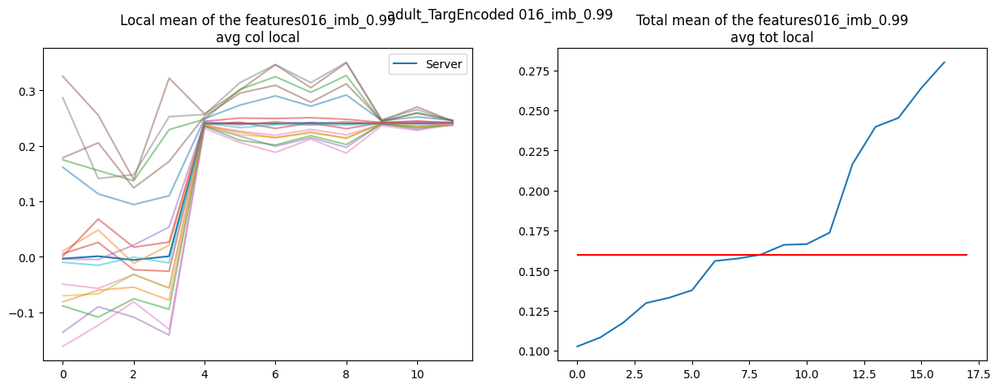

models found: ['misty-dust-378_model.pth']
choosing: misty-dust-378_model.pth
(2000, 2)
Server
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
016_imb_0.99
Elapsed time: 110.38419651985168
Done with 016_imb_0.99
----------------------------------------------------
016_imb_5.0
models found: ['earnest-snow-377_model.pth']
choosing: earnest-snow-377_model.pth
(2000, 2)
Server
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
016_imb_5.0


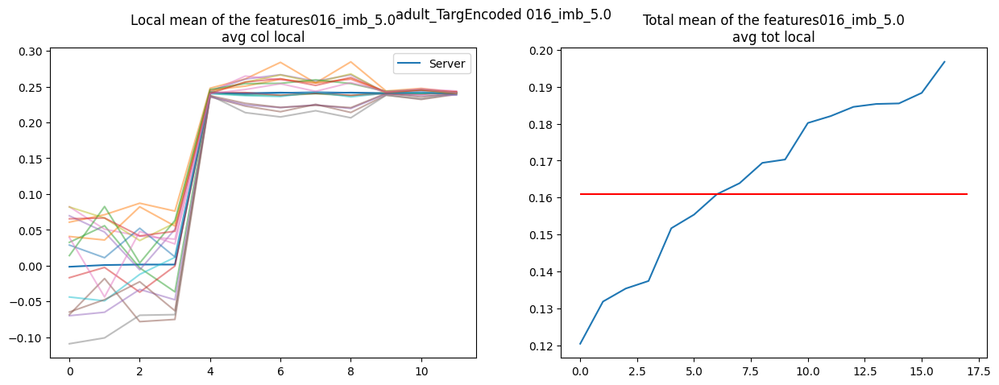

models found: ['earnest-snow-377_model.pth']
choosing: earnest-snow-377_model.pth
(2000, 2)
Server
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
016_imb_5.0
Elapsed time: 219.4441740512848
Done with 016_imb_5.0
----------------------------------------------------
016_iid
models found: ['dry-dawn-376_model.pth']
choosing: dry-dawn-376_model.pth
(2000, 2)
Server
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
016_iid


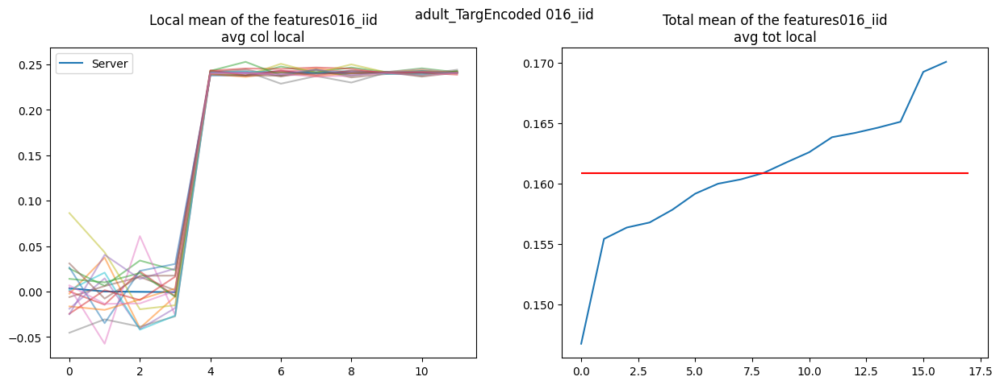

models found: ['dry-dawn-376_model.pth']
choosing: dry-dawn-376_model.pth
(2000, 2)
Server
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
016_iid
Elapsed time: 328.56088519096375
Done with 016_iid
----------------------------------------------------
012_imb_0.99
models found: ['fallen-durian-374_model.pth']
choosing: fallen-durian-374_model.pth
(2000, 2)
Server
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
012_imb_0.99


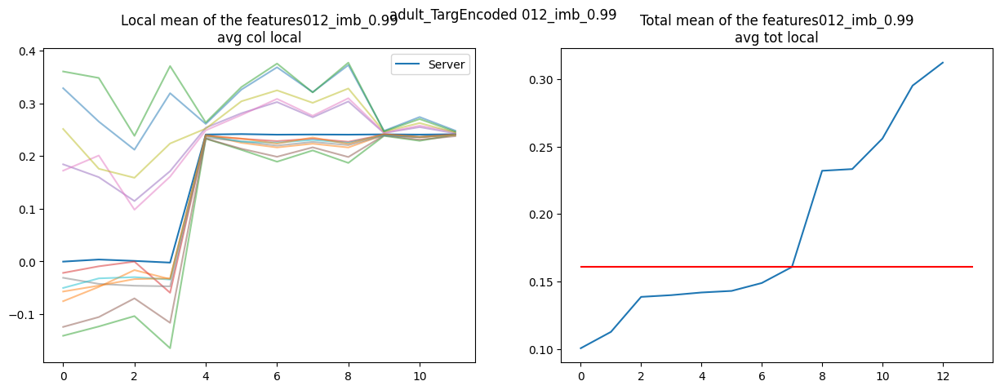

models found: ['fallen-durian-374_model.pth']
choosing: fallen-durian-374_model.pth
(2000, 2)
Server
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
012_imb_0.99
Elapsed time: 412.71680521965027
Done with 012_imb_0.99
----------------------------------------------------
012_imb_5.0
models found: ['twilight-night-375_model.pth']
choosing: twilight-night-375_model.pth
(2000, 2)
Server
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
012_imb_5.0


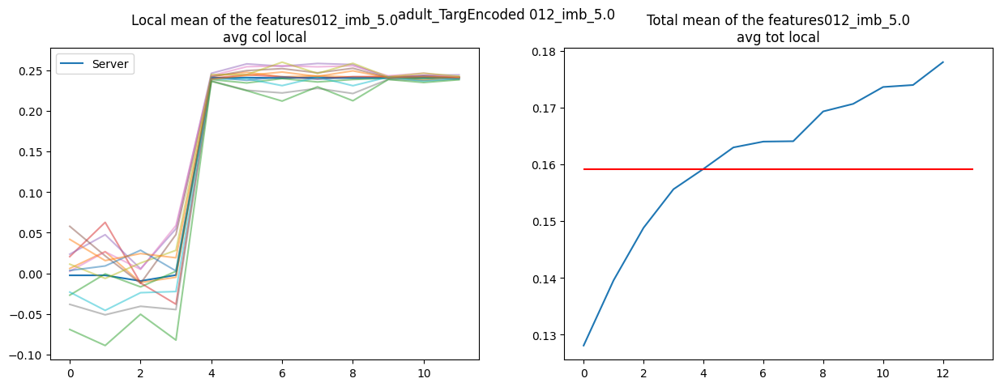

models found: ['twilight-night-375_model.pth']
choosing: twilight-night-375_model.pth
(2000, 2)
Server
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
012_imb_5.0
Elapsed time: 497.5120861530304
Done with 012_imb_5.0
----------------------------------------------------
012_iid
models found: ['rich-pyramid-373_model.pth']
choosing: rich-pyramid-373_model.pth
(2000, 2)
Server
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
012_iid


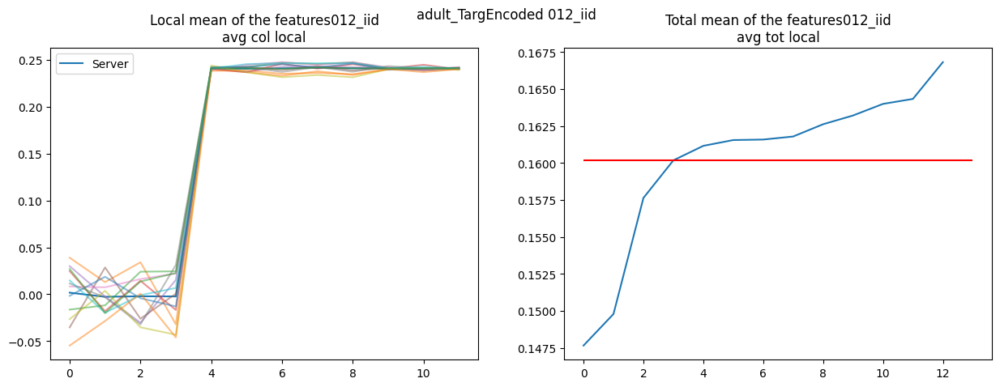

models found: ['rich-pyramid-373_model.pth']
choosing: rich-pyramid-373_model.pth
(2000, 2)
Server
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
012_iid
Elapsed time: 582.7529399394989
Done with 012_iid
----------------------------------------------------
Total Elapsed time: 582.7531747817993
dict_keys([100, 1000])


In [34]:
all_base_values = {exp:{} for exp in focus}
def check_compute_faithfulness(exp, all_shap_values_dict, base_value,local_mean=False,store_base_values={},show=False,compute=True):
    model_path = os.path.join(exp_path, exp, "models")
    neural_model = load_model(model_path)

    shap_values_dict = all_shap_values_dict[exp]
    model = aix_model(neural_model)
    _, num_clients, distribution = get_dt_name_nc_d(exp)
    partitions_te_set = load_test_partitions(dt_name, num_clients, distribution)
    explanation_set = np.load(os.path.join("Experiments",dt_name,"explanation_set.npz"))
    # create the dataloader transforming the dataset in a tensor dataset
    explan_dataset = torch.utils.data.TensorDataset(torch.Tensor(explanation_set['features']),
                                                    torch.Tensor(explanation_set['labels']))
    loader_explain, _ = create_dataloader(ordinal_encoding(explan_dataset),batch_size=32, shuffle=False)
    
    # now re-get the test set as tensor
    te_set = loader_explain.dataset
    # for every class get the indices of the samples so that we can return the indexes of the samples of that class
    class_idxs = []
    num_classes = partitions_te_set.tensors[1].shape[1]
    for i in range(num_classes):
        class_idxs.append(np.where(te_set.tensors[1] == i)[0])
    x = te_set.tensors[0].numpy()
    
    faith_dict = {"Server": [], "Clients": []}

    activations = model.predict_proba(x)
    print(activations.shape)
    all_base_values = []
    faits = []
    
    if show:
    # create 2 subplots
        fig, axes = plt.subplots(1,2,figsize=(15,5))
        axes = axes.flatten()

    for client_id in range(num_clients + 1):
        if client_id == 0:
            key = "Server"
            coefs = shap_values_dict[key]
        else:
            key = "Clients"
            coefs = shap_values_dict[key][client_id - 1]

        if client_id > 0:
            tr_set,_ = load_partition(dt_name, client_id,
                                        num_clients,"_".join(exp.split("_")[1:]))
            
            num_classes = tr_set.tensors[1].shape[1]
            data = tr_set.tensors
            data
        else: # this is the server
            data = load_train_partitions(dt_name, num_clients, dataset_distribution=distribution).tensors

        # compute the mean of the train data

        # print(data[0].shape)
        mean = data[0].mean(axis=0)
        # compute the mean of the means
        base_value = data[0].mean()
        all_base_values.append(base_value)
        if local_mean:
            store_base_values[exp][1000] = mean
        else:
            store_base_values[exp][100] = base_value * np.ones(shape=x.shape[1])
        
        #print("mean",mean)
        #print("base value",base_value)
        print(key)
        faits = []
        num_samples = 2000
        if show:
            if key != "Server":

                axes[0].plot(mean,alpha=0.5)
            else:
                axes[0].plot(mean,label=key)
        if compute:
            for sample, fi in zip(x[:num_samples], coefs[:num_samples]):
                faith_m = faithfulness_metric(model=model,
                                            x=sample,
                                            coefs=fi,
                                            base=(mean if local_mean else base_value * np.ones(shape=fi.shape[0])),
                                            )
                
                faits.append(faith_m)
            
        faith_dict[key].append(np.array(faits))
    print(exp)
    if local_mean==False:
        if show:
            axes[0].set_title("Local mean of the features"+str(exp)+"\navg col local")
            axes[0].legend()
            
            axes[1].plot(sorted(all_base_values))
            
            axes[1].set_title("Total mean of the features"+str(exp)+"\navg tot local")
            axes[1].hlines(all_base_values[0],0,len(all_base_values),color="red")
            plt.suptitle(dt_name+" "+exp)
            plt.show()

    return class_idxs,faith_dict,activations
start = time.time()
for exp in focus:
    
    print(exp)
    if 100 not in all_base_values[exp].keys():
        compute = 100 not in all_faith_dict[exp].keys()
        _,new_f_local_mean,_ = check_compute_faithfulness(exp,all_shap_values_dict,0,local_mean=False,store_base_values=all_base_values,show=True,
        compute= compute)
        if compute:
            all_faith_dict[exp][100]= new_f_local_mean
            all_faith_dict[exp][100]["Clients"] = np.array(all_faith_dict[exp][100]["Clients"])
            all_faith_dict[exp][100]["Server"] = np.array(all_faith_dict[exp][100]["Server"][0]).reshape(1,-1)
    if 1000 not in all_base_values[exp].keys():
        compute = 1000 not in all_faith_dict[exp].keys()
        _, new_f_mean_mean,_ = check_compute_faithfulness(exp,all_shap_values_dict,0,local_mean=True,store_base_values=all_base_values,
            compute= compute)
        if compute:
            all_faith_dict[exp][1000]=new_f_mean_mean
            all_faith_dict[exp][1000]["Clients"] = np.array(all_faith_dict[exp][1000]["Clients"])
            all_faith_dict[exp][1000]["Server"] = np.array(all_faith_dict[exp][1000]["Server"][0]).reshape(1,-1)
    print("Elapsed time:",time.time()-start)
    print("Done with",exp)
    print("----------------------------------------------------")
print("Total Elapsed time:",time.time()-start)

print(all_base_values[exp].keys())

In [35]:
# save all_base_values to a json file
with open(dt_name+"_all_base_values_sampled_shap.json","w") as f:
    # convert the numpy arrays to lists
    all_base_values_list = {k:
                            {base_value:v.tolist()
                            for base_value,v in serverclient.items()}
                        for k,serverclient in all_base_values.items()}
    json.dump(all_base_values_list,f)

In [36]:
# reload all_base_values from the json file
with open(dt_name+"_all_base_values_sampled_shap.json","r") as f:
    all_base_values_list = json.load(f)
all_base_values = {k:
                    {float(base_value):np.array(v)
                    for base_value,v in serverclient.items()}
                for k,serverclient in all_base_values_list.items()} 

In [37]:
list(all_base_values.items())[0]

('016_imb_0.99',
 {100.0: array([0.10263236, 0.10263236, 0.10263236, 0.10263236, 0.10263236,
         0.10263236, 0.10263236, 0.10263236, 0.10263236, 0.10263236,
         0.10263236, 0.10263236]),
  1000.0: array([-0.16141249, -0.1232815 , -0.08090246, -0.13064186,  0.23176223,
          0.20592032,  0.18824235,  0.21229033,  0.18682069,  0.23639211,
          0.22783606,  0.23856246])})

In [38]:
list(all_base_values.items())[0]

('016_imb_0.99',
 {100.0: array([0.10263236, 0.10263236, 0.10263236, 0.10263236, 0.10263236,
         0.10263236, 0.10263236, 0.10263236, 0.10263236, 0.10263236,
         0.10263236, 0.10263236]),
  1000.0: array([-0.16141249, -0.1232815 , -0.08090246, -0.13064186,  0.23176223,
          0.20592032,  0.18824235,  0.21229033,  0.18682069,  0.23639211,
          0.22783606,  0.23856246])})

In [39]:
dt_name+"_all_faith_dict_"+explainer_folder_name+".json"

'adult_TargEncoded_all_faith_dict_shap.json'

### write all_faith_dict to a json file if the keys 100 and 1000 were not present


In [40]:
with open(dt_name+"_all_faith_dict_"+explainer_folder_name+".json","w") as f:
    # convert the numpy arrays to lists
    all_faith_dict_list = {k:
                            {base_value:
                                {k2:list([list(values) for values in v2])
                                for k2,v2 in serverclient.items()}
                            for base_value,serverclient in v.items()}
                        for k,v in all_faith_dict.items()}
    json.dump(all_faith_dict_list,f)

In [41]:
import joypy

In [42]:
for k in all_faith_dict.keys():
    print(k, all_faith_dict[k].keys())
for exp in focus:
    for base_value in all_faith_dict[exp].keys():
        print("Experiment:",exp,"Base value:",base_value)
        print(all_faith_dict[exp][base_value].keys())
        bv = base_value
        if bv == 100:
            bv = 'avg col local'
        if bv == 1000:
            bv = 'avg tot local'
        fig,ax = joypy.joyplot(
            pd.DataFrame({
                'Server': all_faith_dict[exp][base_value]['Server'][0],
                **{'Client '+str(i+1): all_faith_dict[exp][base_value]['Clients'][i] for i in range(len(all_faith_dict[exp][base_value]['Clients']))}
            }),
            figsize=(7,5),
            # title=f'{dt_name}\nFaithfulness Distributions for {exp} (Base Value: {bv})',
            color=['k']+[plt.cm.viridis(i / len(all_faith_dict[exp][base_value]['Clients'])) for i in range(len(all_faith_dict[exp][base_value]['Clients']))],
        )
        for axe in ax:
            axe.set_xlim(-1, 1)
            #axe.set_xlabel('Faithfulness Score')
        plt.savefig(os.path.join("joyplots",
                              "Faithfulness_basevalues_"+explainer_folder_name+"_"+dt_name+"_"+exp+"_basevalue_"+str(base_value)+".png"))
        
        plt.close()


# once the plots have been created, create as many gifs as the number of experiments in focus (so one for each experiment)
for exp in focus:
    # create a list of the filenames of the plots
    filenames = []
    for base_value in all_faith_dict[exp].keys():
        filename = os.path.join("joyplots",
                              "Faithfulness_basevalues_"+explainer_folder_name+"_"+dt_name+"_"+exp+"_basevalue_"+str(base_value)+".png")
        filenames.append(filename)
    # create the gif
    import imageio
    images = [] 
    for filename in filenames:
        images.append(imageio.imread(filename))
    gif_filename = os.path.join("joyplots",
                              "all_fb_"+explainer_folder_name+"_"+dt_name+"_"+exp+".gif")
    # use loop=0 to loop forever
    imageio.mimsave(gif_filename, images, duration=1000, loop=0)
    print("Created gif:",gif_filename)
    # remove the png files
    #for filename in filenames:
    #    os.remove(filename)


016_imb_0.99 dict_keys([-0.5, -0.2, 0.001, 0.2, 0.5, 100, 1000])
016_imb_5.0 dict_keys([-0.5, -0.2, 0.001, 0.2, 0.5, 100, 1000])
016_iid dict_keys([-0.5, -0.2, 0.001, 0.2, 0.5, 100, 1000])
012_imb_0.99 dict_keys([-0.5, -0.2, 0.001, 0.2, 0.5, 100, 1000])
012_imb_5.0 dict_keys([-0.5, -0.2, 0.001, 0.2, 0.5, 100, 1000])
012_iid dict_keys([-0.5, -0.2, 0.001, 0.2, 0.5, 100, 1000])
Experiment: 016_imb_0.99 Base value: -0.5
dict_keys(['Server', 'Clients'])
Experiment: 016_imb_0.99 Base value: -0.2
dict_keys(['Server', 'Clients'])
Experiment: 016_imb_0.99 Base value: 0.001
dict_keys(['Server', 'Clients'])
Experiment: 016_imb_0.99 Base value: 0.2
dict_keys(['Server', 'Clients'])
Experiment: 016_imb_0.99 Base value: 0.5
dict_keys(['Server', 'Clients'])
Experiment: 016_imb_0.99 Base value: 100
dict_keys(['Server', 'Clients'])
Experiment: 016_imb_0.99 Base value: 1000
dict_keys(['Server', 'Clients'])
Experiment: 016_imb_5.0 Base value: -0.5
dict_keys(['Server', 'Clients'])
Experiment: 016_imb_5.0 B

/tmp/ipykernel_3914672/205110279.py:42: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  images.append(imageio.imread(filename))


Created gif: joyplots/all_fb_shap_adult_TargEncoded_016_imb_0.99.gif
Created gif: joyplots/all_fb_shap_adult_TargEncoded_016_imb_5.0.gif
Created gif: joyplots/all_fb_shap_adult_TargEncoded_016_iid.gif
Created gif: joyplots/all_fb_shap_adult_TargEncoded_012_imb_0.99.gif
Created gif: joyplots/all_fb_shap_adult_TargEncoded_012_imb_5.0.gif
Created gif: joyplots/all_fb_shap_adult_TargEncoded_012_iid.gif


In [43]:

# create the compact version of all of them
# create a 2x3 grid of subplots for each base value, every row is for the client number, each column is for the distribution
# in each subplot thtere are the alreaady created joyplots (that should be loaded from the png files) and each 2x3 grid is for a specific base value
import matplotlib.image as mpimg
import imageio

base_values =  sorted(all_faith_dict[exp].keys())

for bv in base_values:
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    axes = axes.flatten()
    for i, exp in enumerate(focus):
        ax = axes[i]
        filename = os.path.join("joyplots",
                              "Faithfulness_basevalues_"+explainer_folder_name+"_"+dt_name+"_"+exp+"_basevalue_"+str(bv)+".png")
        img = mpimg.imread(filename)
        ax.imshow(img)
        ax.axis('off')
        ax.set_title(exp)
        if i == 0 or i == 3:
            ax.set_xlabel('Distributions')
        if i >= 3:
            ax.set_ylabel('Clients')
    plt.suptitle(f'Faithfulness Distributions for Base Value: {bv}', fontsize=16)
    plt.tight_layout()
    compact_filename = os.path.join("joyplots",
                              "compact_faithfulness_basevalue_"+explainer_folder_name+"_"+dt_name+"_basevalue_"+str(bv)+".png")
    plt.savefig(compact_filename)
    plt.close()

# now, as before create a gif with all the compact versions
filenames = []
for bv in base_values:
    filename = os.path.join("joyplots",
                              "compact_faithfulness_basevalue_"+explainer_folder_name+"_"+dt_name+"_basevalue_"+str(bv)+".png")
    filenames.append(filename)
# create the gif

images = [] 
for filename in filenames:
    images.append(imageio.imread(filename))
gif_filename = os.path.join("joyplots",
                              "0_all_fb_"+explainer_folder_name+"_"+dt_name+".gif")
imageio.mimsave(gif_filename, images, duration=800,loop=0)

print("Done, the file is saved as",gif_filename)

/tmp/ipykernel_3914672/1998526781.py:41: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  images.append(imageio.imread(filename))


Done, the file is saved as joyplots/0_all_fb_shap_adult_TargEncoded.gif


In [44]:
os.listdir("plots")

['diamond_1_hot_1000_sampled_shap_012_iid_faithfulness_vs_L2.pdf',
 'dry_bean_1000_shap_016_iid_faithfulness_vs_L2.pdf',
 'faithfulness_all_experiments_diamond_1_hot_sampled_shap_Final.pdf',
 'faithfulness_all_experiments_diamond_1_hot_shap_filled.pdf',
 'faithfulness_all_experiments_diamond_1_hot_sampled_shap_filled.pdf',
 'dry_bean_1000_shap_012_iid_faithfulness_vs_L2.pdf',
 'faithfulness_all_experiments_adult_TargEncoded_sampled_shap_filled.pdf',
 'dry_bean_1000_sampled_shap_012_imb_0.99_faithfulness_vs_L2.pdf',
 'zipall.sh',
 'diamond_1_hot_1000_sampled_shap_016_iid_faithfulness_vs_L2.pdf',
 'faithfulness_all_experiments_dry_bean_shap_filled.pdf',
 'dry_bean_1000_sampled_shap_016_imb_5.0_faithfulness_vs_L2.pdf',
 'faithfulness_all_experiments_adult_TargEncoded_sampled_shap_Final.pdf',
 'dry_bean_1000_sampled_shap_012_imb_5.0_faithfulness_vs_L2.pdf',
 'faithfulness_all_experiments_dry_bean_sampled_shap_filled.pdf',
 'adult_TargEncoded_1000_sampled_shap_012_imb_0.99_faithfulness_vs_L

012 imb_0.99
Faithfulnesses for base value -0.5
<class 'list'> 12 (2000,)
				 0 0
Faithfulnesses for base value -0.2
<class 'list'> 12 (2000,)
				 0 0
Faithfulnesses for base value 0.001
<class 'list'> 12 (2000,)
				 0 0
Faithfulnesses for base value 0.2
<class 'list'> 12 (2000,)
				 0 0
Faithfulnesses for base value 0.5
<class 'list'> 12 (2000,)
				 0 0
Faithfulnesses for base value 100
<class 'numpy.ndarray'> 12 (2000,)
				 0 0
Faithfulnesses for base value 1000
<class 'numpy.ndarray'> 12 (2000,)
				 0 0
012 imb_5.0
Faithfulnesses for base value -0.5
<class 'list'> 12 (2000,)
				 0 0
Faithfulnesses for base value -0.2
<class 'list'> 12 (2000,)
				 0 0
Faithfulnesses for base value 0.001
<class 'list'> 12 (2000,)
				 0 0
Faithfulnesses for base value 0.2
<class 'list'> 12 (2000,)
				 0 0
Faithfulnesses for base value 0.5
<class 'list'> 12 (2000,)
				 0 0
Faithfulnesses for base value 100
<class 'numpy.ndarray'> 12 (2000,)
				 0 0
Faithfulnesses for base value 1000
<class 

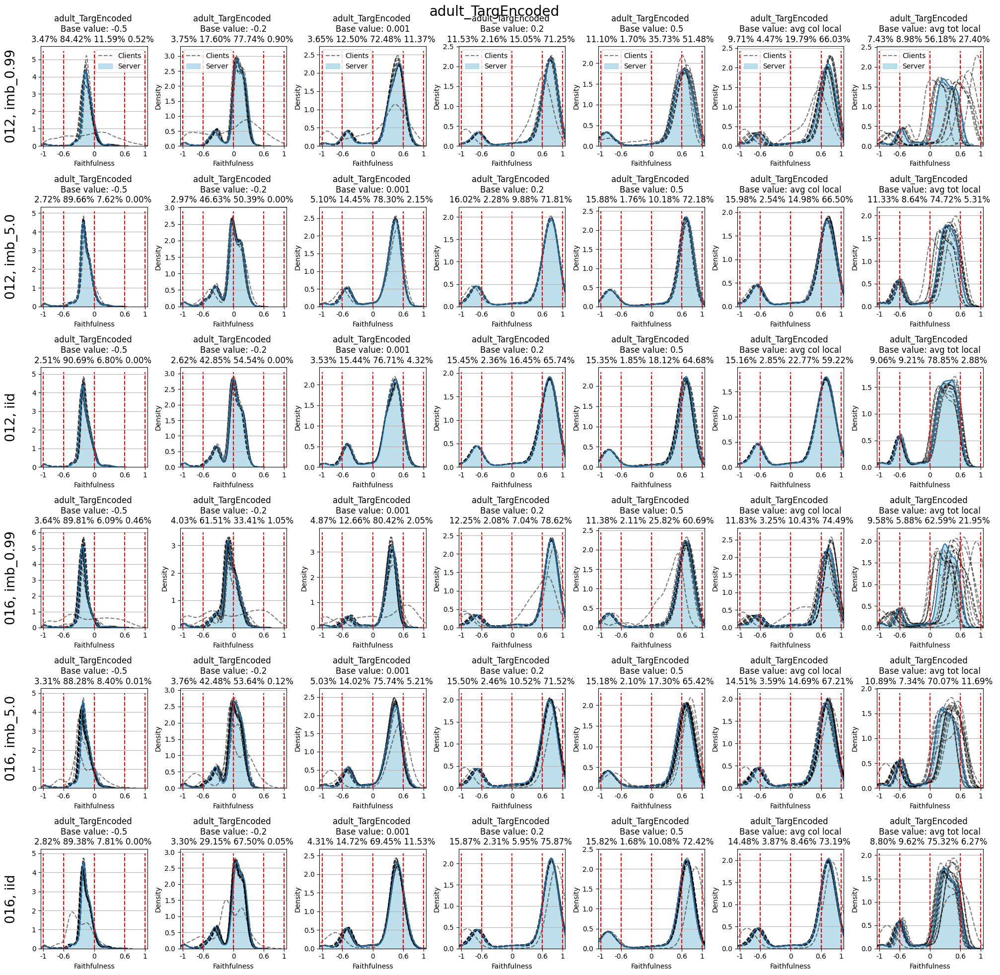

Figure saved at: plots/faithfulness_all_experiments_adult_TargEncoded_shap_filled.pdf


In [45]:
partitions = ["012","016"]
distribs = ["iid","imb_5.0","imb_0.99"]

# the fill color is based soley on the dataset, orange for dry bean, blue for dutch, red for adult, light blue for diamonds
fill_color = ("darkorange" if dt_name == "dry_bean" else "lightblue" if dt_name == "adult_TargEncoded" else "lightgreen")
fill_color = 'lightblue'

n_bvs = len(sorted(all_faith_dict[exps[0]].keys()))
fig,ax = plt.subplots(len(partitions)*len(distribs),n_bvs,figsize=(20,20))
ax = ax.reshape(-1)
o_i = 0
for p in partitions:
    for d in distribs[::-1]:
        # now we plot the faithfulnesses:
        exp = p+"_"+d
        print(p,d)
        # create the figure with as many subplots as the number of base values
        # then plot the distribution of the faithfulnesses of all the nodes with a low opacity
        # then plot the faithfulness of the server with a higher opacity
        base_values = sorted(all_faith_dict[exp].keys())
        for j,bv in enumerate(base_values):
                j+=n_bvs*o_i
                # if there is not the data for the base value, skip it
                if bv not in all_faith_dict[exp].keys():
                    print("Base value",bv,"not found for experiment",exp)
                    continue
                # get the faithfulnesses
                ff = all_faith_dict[exp][bv]
                # get the indexes of the classes
                indexes = indexes_per_calss[exp]
                # get the activations of the model
                activas = activations_of_models
                # plot the faithfulnesses
                print("Faithfulnesses for base value",bv)
                print(type(ff["Clients"]),len(ff["Clients"]),ff["Clients"][0].shape)
                if isinstance(ff["Server"],list):
                    ff["Server"] = ff["Server"][0]
                if isinstance(ff["Clients"],list):
                    ff["Clients"] = np.array(ff["Clients"])
                
                print("\t"*4,np.isnan(ff["Server"]).sum(),np.isnan(ff["Clients"]).sum())
                for i in range(len(ff["Clients"])):
                    # plot the faithfulness of the nodes
                    if i == 0:
                        sns.kdeplot(ff["Clients"][i],ax=ax[j],fill=False,alpha=0.5,ls="--",color="black",cumulative=False,label="Clients")
                    else:
                        sns.kdeplot(ff["Clients"][i],ax=ax[j],fill=False,alpha=0.5,ls="--",color="black",cumulative=False)
                # plot the faithfulness of the server
                sns.kdeplot(ff["Server"].reshape(-1),ax=ax[j],label="Server",fill=True,alpha=0.8,cumulative=False,color=fill_color)
                sns.kdeplot(ff["Server"].reshape(-1),ax=ax[j],fill=False,alpha=1,cumulative=False)

                if "COMP" in ff.keys():
                    print("COMP",ff["COMP"].mean(),ff["COMP"].std(),ff["COMP"].shape)
                    sns.kdeplot(ff["COMP"].reshape(-1),ax=ax[j],label=res_d["COMP"],fill=True,alpha=0.5,cumulative=False,color="green")
                    sns.kdeplot(ff["COMP"].reshape(-1),ax=ax[j],fill=False,alpha=1,cumulative=False)
                if "SHAP_FL" in ff.keys():
                    print("SHAP_FL",ff["SHAP_FL"].mean(),ff["SHAP_FL"].std(),ff["SHAP_FL"].shape)
                    sns.kdeplot(ff["SHAP_FL"].reshape(-1),ax=ax[j],label=res_d["SHAP_FL"],fill=True,alpha=0.5,cumulative=False,color='purple')
                    sns.kdeplot(ff["SHAP_FL"].reshape(-1),ax=ax[j],fill=False,alpha=1,cumulative=False)
                trs = [-0.6,0,0.6]
                trs = [-1]+trs+[1]
                percs = []
                title_addition = ''
                for i in range(len(trs) - 1):
                    lower = trs[i]
                    upper = trs[i+1]
                    pperc = ((ff["Clients"][:] > lower) & (ff["Clients"][:] <= upper)).mean()
                    perc = np.round(pperc * 100, 2)
                    percs.append(perc)
                    title_addition += f"{perc:.2f}% "

                ylim = ax[j].get_ylim()

                ax[j].vlines(trs,0,ylim[1],colors="red",linestyles="--")

                # set the xticks at -1,-0.6,0,0.6,1
                ax[j].set_xticks(trs)

                # set the xticks labels
                ax[j].set_xticklabels([str(t) for t in trs])
                # add to the title the average percentage of client's explanations that are less than -0.6

                if bv == 100:
                    bv = 'avg col local'
                if bv == 1000:
                    bv = 'avg tot local'
                ax[j].set_title(f"{dt_name} \nBase value: {bv}\n{title_addition}")
                ax[j].set_xlabel("Faithfulness")
                ax[j].set_ylabel("Density") 
                # fix the x limits
                ax[j].set_xlim(-1.05,1.05)
                # set the y grid
                ax[j].grid(axis="y")

                # plot vertical lines at -0.6, 0 and 0.6
                # if the subplot is the first of the row, set the ylabel as the p and d
                if j%len(base_values) == 0:
                    ax[j].set_ylabel(p+", "+d,rotation=90,labelpad=20,fontsize=19)
                # if the subplot is the first raw set the legend
                if j < len(base_values):
                    ax[j].legend()
        o_i+=1 
plt.suptitle(dt_name,fontsize=20)
plt.tight_layout()
plt.savefig(os.path.join("plots",f"faithfulness_all_experiments_{dt_name}_{explainer_folder_name}_filled.pdf"),dpi=300,bbox_inches='tight')
plt.show()
print("Figure saved at:",os.path.join("plots",f"faithfulness_all_experiments_{dt_name}_{explainer_folder_name}_filled.pdf"))

In [46]:
b_v = 1000

In [47]:
all_faith_dict[exp][b_v].keys()

dict_keys(['Server', 'Clients'])

## Checking for nans

In [48]:
print(f'b_v is {b_v}')
for exp in focus:
    for jj, f_c in enumerate(all_faith_dict[exp][b_v]["Clients"]):
        
        arenans = np.isnan(f_c)
        if arenans.sum()>0:# or arenansFaith>0:
            print(exp,f_c.shape)
            # check for nans
            print("nans:",arenans.sum())
            #print("nans faith:",arenansFaith)
            '''if arenans.sum()<20:
                for i in range(1,arenans.sum()):
                    rnd_idx = jj
                    while rnd_idx == jj:
                        rnd_idx = np.random.randint(0,len(all_faith_dict[exp][b_v]["Clients"]))
                    print("activations:",activations_of_models[exp][0.001][arenans][i])
                    print("faithfulness:",f_c[arenans][i],all_faith_dict[exp][b_v]["Clients"][rnd_idx][arenans][i])
                    print("explanations:",all_shap_values_dict[exp]["Clients"][jj][arenans][i])
                    print("explanations:",all_shap_values_dict[exp]["Clients"][rnd_idx][arenans][i])

                    print("Server explanations:",all_shap_values_dict[exp]["Server"][arenans][i])
                    print()'''
            
            # it seems that they are nan when all the explanations are all 0,
            # let's check!
            print("all zeros:",(
                all_shap_values_dict[exp]["Clients"][jj][arenans]==0*np.ones(all_shap_values_dict[exp]["Clients"][jj][arenans].shape[1])).all(axis=1).sum(),
                  arenans.sum())

            # check if some explanations are all 0 but the faithfulness is not nan
            # so we check wheather the explanations that are not arenas are all zeros and count them
            # get all expl that are equal to 0
            all_zero_exp = (all_shap_values_dict[exp]["Clients"][jj]==0*np.ones(all_shap_values_dict[exp]["Clients"][jj].shape[1])).all(axis=1)
            # get the faithfulnesses
            fffaiths = all_faith_dict[exp][b_v]["Clients"][jj][all_zero_exp]
            # count the number of faithfulnesses that are not nan
            #print("faithfulnesses that are not nan but the explanations are all zeros:",fffaiths.shape)
            #  check the explanations of the Server
            all_faith_dict[exp][b_v]["Clients"][jj][all_zero_exp] = 0
            

b_v is 1000


In [49]:
focus[0]

'016_imb_0.99'

## A plot to check for std within class/clients

In [50]:
'''indexes_per_calss_list.keys()#len(indexes_per_calss_list[exp])
for exp in focus:
    plt.clf()
    # plot the distributions of the faithfulness of every sample
    fig,ax = plt.subplots(len(indexes_per_calss_list[exp]),2,figsize=(12,10*len(indexes_per_calss_list[exp])/2))
    ax = ax.flatten()
    pred = activations_of_models[exp][0.001]
    percs06 = np.zeros(len(indexes_per_calss_list[exp]))
    percs0 = np.zeros(len(indexes_per_calss_list[exp]))
    for i,idxs in enumerate(indexes_per_calss_list[exp]):
        color = ['#1f77b4','#ff7f0e','#2ca02c','#d62728','#9467bd','#8c564b','#e377c2','#7f7f7f','#bcbd22','#17becf'][i]
        ax[2*i+1].plot([0,0],[0,0],color=color,label="True predicted class "+str(i))
        ax[2*i+1].plot([0,0],[0,0],color='k',label="False predicted class "+str(i))
        for idx in idxs:
            # check if it it a true positive or a false positive
            if pred[idx].argmax() != i:
                color = 'k'
            else:
                color = ['#1f77b4','#ff7f0e','#2ca02c','#d62728','#9467bd','#8c564b','#e377c2','#7f7f7f','#bcbd22','#17becf'][i]
            sns.kdeplot(all_faith_dict[exp][b_v]["Clients"].T[idx].flatten(),color = color,alpha=0.3,ax=ax[2*i],cumulative=True)
            sns.kdeplot(all_faith_dict[exp][b_v]["Clients"].T[idx].flatten(),color = color,alpha=0.3,ax=ax[2*i+1],cumulative=False)
            

            # count the number of samples that have SOME faithfulness value above -0.6 and some below -0.6, in percentage. so it is True if there is at least one faithfulness value above -0.6 and one below -0.6
            perc06 = (all_faith_dict[exp][b_v]["Clients"].T[idx].flatten()>-0.6).sum()>0

            perc06 &= (all_faith_dict[exp][b_v]["Clients"].T[idx].flatten()<-0.6).sum()>0
            perc0 = (all_faith_dict[exp][b_v]["Clients"].T[idx].flatten()<0).sum()>0
            perc0 &= (all_faith_dict[exp][b_v]["Clients"].T[idx].flatten()>0).sum()>0
            if np.random.rand() < 0.01:
                print(np.round(all_faith_dict[exp][b_v]["Clients"].T[idx].flatten(),2), "are the faiths")
                print(perc06,perc0)
            

            percs06[i] += (1 if perc06 else 0)
            percs0[i] += (1 if perc0 else 0)
        xlab = "Class "+str(i)+ "has " + str(percs06[i]) + " samples with some faith<-0.6"
        xlab += " and " + str(percs0[i]) + " samples with some faith<0"
        ax[2*i].set_xlabel(xlab)
        
    # print the percentage of samples that have some faithfulness values that are below -0.6
    print("samples that have some faithfulness values below -0.6")
    print(percs06/len(indexes_per_calss_list[exp]))
    print("samples that have some faithfulness values below 0")
    print(percs0/len(indexes_per_calss_list[exp]))
    
    old_y_lim = plt.ylim()
    # add fake lines for the legend

    plt.suptitle("KDE Faithfulness of the samples of the clients, per class\n"+" ".join([str(elemento) for elemento in exp]),fontsize=20)
    for j,axe in enumerate(ax.flatten()):
        axe.set_xlim(-1.05,1.05)
        axe.grid(True)
        axe.set_title("Class "+str(int(j/2)))
        if j%2==1:
            axe.legend(fontsize=18, loc='upper right')
            axe.set_ylabel("Density")
            axe.set_yscale("log")
        else:
            axe.set_ylabel("Cumulative distribution function")


    plt.ylim(old_y_lim)
    plt.tight_layout()
    #plt.savefig(dt_name+"_"+" ".join([str(elemento) for elemento in exp])+"_faithfulness_distributions.pdf")
    plt.show()
    plt.close()
    plt.clf()
    break

'''

'indexes_per_calss_list.keys()#len(indexes_per_calss_list[exp])\nfor exp in focus:\n    plt.clf()\n    # plot the distributions of the faithfulness of every sample\n    fig,ax = plt.subplots(len(indexes_per_calss_list[exp]),2,figsize=(12,10*len(indexes_per_calss_list[exp])/2))\n    ax = ax.flatten()\n    pred = activations_of_models[exp][0.001]\n    percs06 = np.zeros(len(indexes_per_calss_list[exp]))\n    percs0 = np.zeros(len(indexes_per_calss_list[exp]))\n    for i,idxs in enumerate(indexes_per_calss_list[exp]):\n        color = [\'#1f77b4\',\'#ff7f0e\',\'#2ca02c\',\'#d62728\',\'#9467bd\',\'#8c564b\',\'#e377c2\',\'#7f7f7f\',\'#bcbd22\',\'#17becf\'][i]\n        ax[2*i+1].plot([0,0],[0,0],color=color,label="True predicted class "+str(i))\n        ax[2*i+1].plot([0,0],[0,0],color=\'k\',label="False predicted class "+str(i))\n        for idx in idxs:\n            # check if it it a true positive or a false positive\n            if pred[idx].argmax() != i:\n                color = \'k\'\

In [51]:
all_faith_dict["012_iid"][1000].keys()

dict_keys(['Server', 'Clients'])

## function to plot correlation between faithfulness and activations

In [52]:
'''# this function is used to find a correlation between the faithfulness of the clients and the activations of the model
def plot_correlation(exp,faithfulnesses,activations,show=True,):
    #this function is used to find a correlation between the faithfulness of the clients and the activations of the model.
    # We iterate over all the clients. We compute the correlation of the faithfulness of the clients and the maximum activation of the model.
    dt,nc,distr = get_dt_name_nc_d(exp)
    #test_set = load_test_partitions(dt_name,nc,distr)
    partitions_te_set = load_test_partitions(dt_name, nc, distr)
    loader_explain, _ = create_dataloader((
                                            cap_dataset((partitions_te_set.tensors[0],
                                                        partitions_te_set.tensors[1]),
                                                        2000)
                                            ),batch_size=32, shuffle=False)
    explanation_set = np.load(os.path.join("Experiments",dt_name,"explanation_set.npz"))
    # create the dataloader transforming the dataset in a tensor dataset
    explan_dataset = torch.utils.data.TensorDataset(torch.Tensor(explanation_set['features']),
                                                    torch.Tensor(explanation_set['labels']))
    loader_explain, _ = create_dataloader(explan_dataset,batch_size=32, shuffle=False)
    test_set = loader_explain.dataset
    #print(test_set.tensors[0].shape)
    #print(test_set.tensors[1].shape)
    # get the faithfulness of the clients
    faithfulnesses = faithfulnesses["Clients"].T
    # for each client, we compute the correlation of the faithfulness of the clients and the maximum activation of the model
    #print(faithfulnesses.shape)
    correlations = []
    for i in range(faithfulnesses.shape[1]):
        # explude the nan values
        idxs = np.isnan(faithfulnesses[:,i])
        faithfulne = np.abs(faithfulnesses[~idxs,i])
        
        # get the truth values
        labs_te_set = test_set.tensors[1].argmax(axis=1)[~idxs]
        #outs = activations[~idxs,:][:,labs_te_set]
        # get the activations of the model that have faithfulness not nan
        outs = activations[~idxs,:]
        # get the maximum activation of the model for the truth values
        outs = outs[:,labs_te_set]
        #print(labs_te_set.shape,outs.shape)
        
        # compute the correlation taking into account the truth values
        # so we compute the correlation of the faithfulness and the "error" of the model, so that we can see if the faithfulness is higher when the model is wrong or the other way around
        
        #iterating over the classes
        correlations_c = []
        for i in range(labs_te_set.max()+1):
            class_idx = labs_te_set == i
            #print(faithfulne[class_idx].shape,outs[class_idx,i].shape)
            cor = np.corrcoef(faithfulne[class_idx],outs[class_idx,i])[0,1]
            correlations_c.append(cor)



        #print(correlations_c)
        # take the absolute value of the correlations per class and aggregate them
        cor = np.mean(np.abs(correlations_c))

        # for the article, the formula of the correlation is the following
        
        
        # \frac{1}{|C|}\Sigma_{c\inC}|\rho(faithfulness_{c},activation_{c})|
        
        # where $C$ is the number of classes, $c$ is the class, $\rho$ is the correlation, $faithfulness_{c}$ is the faithfulness of the class $c$, and $activation_{c}$ is the activation of the class $c$
        
        
        #print(cor.shape)
        #cor = cor[0,1]

        correlations.append(cor)
    return correlations
    
plot_correlation(     "012_imb_0.99",
       all_faith_dict["012_imb_0.99"][1000],
activations_of_models["012_imb_0.99"][0.001])

# now do it for all the experiments
correlations = {}
for exp in all_faith_dict.keys():
    if "12" not in exp or "16" not in exp:
        continue
    print(exp)
    correlations[exp] = {}
    matrix_image = np.zeros((len(all_faith_dict[exp].keys()),len(all_faith_dict[exp][0.5]["Clients"])))
    for j,value in enumerate(sorted(all_faith_dict[exp].keys())):
        cor = plot_correlation(exp,
                           faithfulnesses=all_faith_dict[exp][value],
                           activations=activations_of_models[exp][value])
        matrix_image[j]=cor
        correlations[exp][value] = (np.max(np.abs(cor)),np.mean(cor),np.std(cor))
    # plot the correlation as a matrix 
    plt.imshow(matrix_image,interpolation='none',cmap='coolwarm',vmin=-1,vmax=1)
    # place the values of the correlation in the cells
    plt.colorbar()
    for i in range(matrix_image.shape[0]):
        for j in range(matrix_image.shape[1]):
            plt.text(j,i,round(matrix_image[i,j],2),ha='center',va='center')

    means = np.mean(matrix_image,axis=1)

    plt.xlabel("Clients")
    plt.ylabel("Base value\naverage")
    plt.title(exp+"\nCorrelation of client's faithfulness and\n the maximum activation of the model")
    plt.xticks(np.arange(len(all_faith_dict[exp][0.5]["Clients"])),["C"+str(i+1) for i in range(len(all_faith_dict[exp][0.5]["Clients"]))])
    plt.yticks(np.arange(len(all_faith_dict[exp].keys())),
               ["\n".join([str(e1) for e1 in e]) for e in list(zip(sorted(all_faith_dict[exp].keys()),
            [str(m)[:5] for m in means]))]
    )
    
    # place the mean of the correlation on the right
    # get the yaxes on the right and place the mean of the correlation there
    
    plt.tight_layout()

    plt.savefig(dt_name+"_"+exp+"_correlation_of_faithfulness_and_activation.pdf")
    print("saved in",dt_name+"_"+exp+"_correlation_of_faithfulness_and_activation.pdf")
    plt.show()
    
for k in correlations.keys():
    print(k)
    for k1 in correlations[k].keys():
        print("\t",k1,correlations[k][k1])
    print()
    #break'''

'# this function is used to find a correlation between the faithfulness of the clients and the activations of the model\ndef plot_correlation(exp,faithfulnesses,activations,show=True,):\n    #this function is used to find a correlation between the faithfulness of the clients and the activations of the model.\n    # We iterate over all the clients. We compute the correlation of the faithfulness of the clients and the maximum activation of the model.\n    dt,nc,distr = get_dt_name_nc_d(exp)\n    #test_set = load_test_partitions(dt_name,nc,distr)\n    partitions_te_set = load_test_partitions(dt_name, nc, distr)\n    loader_explain, _ = create_dataloader((\n                                            cap_dataset((partitions_te_set.tensors[0],\n                                                        partitions_te_set.tensors[1]),\n                                                        2000)\n                                            ),batch_size=32, shuffle=False)\n    explanation_set = 

## Compare the "global" explanations within the servers

In [53]:
'''# for a comparison 
# insert all the global explanation in a dataframe to plot them
import pandas as pd
import seaborn as sns
all_global_exp = {}
for exp in all_shap_values_dict.keys():
        print(exp,all_shap_values_dict[exp]["Server"].shape)
        # plot it as barplots
        audit_expl = all_shap_values_dict[exp]["Server"]
        plt.figure(figsize=(15,5))
        plt.subplot(1,2,1)
        plt.title("SHAP explanations for the server")
        plt.boxplot(audit_expl)
        plt.subplot(1,2,2)
        plt.title("Mean absolute SHAP values\naka global shap")
        plt.boxplot(np.abs(audit_expl))
        plt.bar(np.arange(audit_expl.shape[1])+1,np.mean(np.abs(audit_expl),axis=0))
        plt.xticks(np.arange(audit_expl.shape[1]),[str(i) for i in range(audit_expl.shape[1])])
        all_global_exp[exp] = np.mean(np.abs(audit_expl),axis=0)
        # the sup title should be the name of the dataset, epsilon (if in [1,2]) the name of the model, the number of nodes
        plt.suptitle(dt_name+"\n"+" ".join(exp.split("_")))
        plt.tight_layout()
        plt.show()
'''

'# for a comparison \n# insert all the global explanation in a dataframe to plot them\nimport pandas as pd\nimport seaborn as sns\nall_global_exp = {}\nfor exp in all_shap_values_dict.keys():\n        print(exp,all_shap_values_dict[exp]["Server"].shape)\n        # plot it as barplots\n        audit_expl = all_shap_values_dict[exp]["Server"]\n        plt.figure(figsize=(15,5))\n        plt.subplot(1,2,1)\n        plt.title("SHAP explanations for the server")\n        plt.boxplot(audit_expl)\n        plt.subplot(1,2,2)\n        plt.title("Mean absolute SHAP values\naka global shap")\n        plt.boxplot(np.abs(audit_expl))\n        plt.bar(np.arange(audit_expl.shape[1])+1,np.mean(np.abs(audit_expl),axis=0))\n        plt.xticks(np.arange(audit_expl.shape[1]),[str(i) for i in range(audit_expl.shape[1])])\n        all_global_exp[exp] = np.mean(np.abs(audit_expl),axis=0)\n        # the sup title should be the name of the dataset, epsilon (if in [1,2]) the name of the model, the number of nod

In [54]:
all_global_exp = {}
for exp in all_shap_values_dict.keys():
    audit_expl = all_shap_values_dict[exp]["Server"]
    all_global_exp[exp] = np.mean(np.abs(audit_expl),axis=0)

In [55]:
# convert all_global_exp to a dataframe and plot every global explanation in a single plot using seaborn and barplotcolored differently for each combination of partition and distribution
df = pd.DataFrame(all_global_exp).T
df.columns = feat_names
df.index

Index(['012_iid', '012_imb_5.0', '012_imb_0.99', '016_iid', '016_imb_5.0',
       '016_imb_0.99'],
      dtype='object')

Index(['age', 'capital-gain', 'capital-loss', 'hours-per-week', 'workclass',
       'education', 'marital-status', 'occupation', 'relationship', 'race',
       'sex', 'native-country', 'combination'],
      dtype='object')


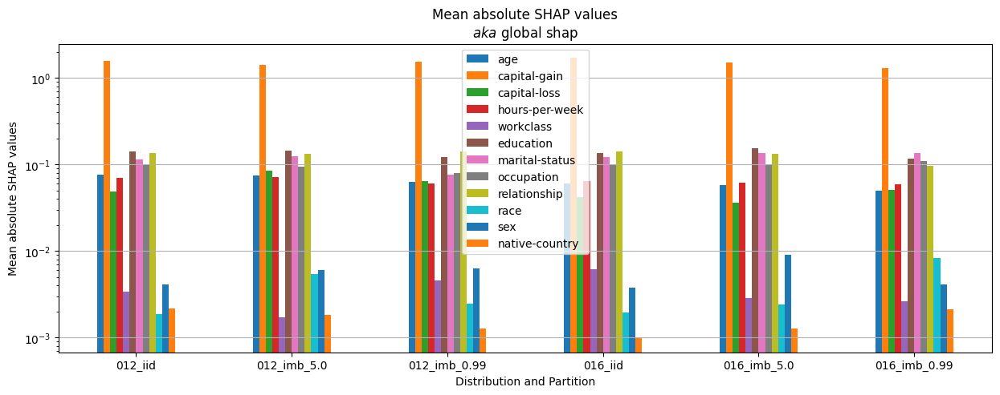

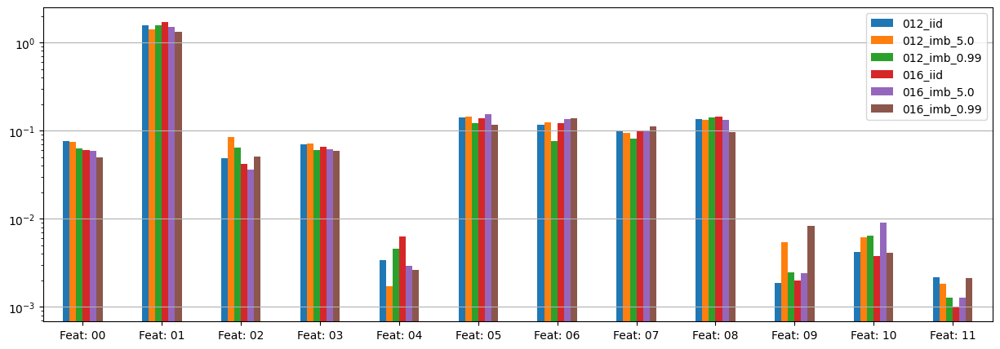

In [56]:


df["combination"] = df.index
#df = df.drop(["level_0","level_1"],axis=1)
print(df.columns)
# plot the global explanations
plt.figure(figsize=(15,5))
plt.title("Mean absolute SHAP values\n$aka$ global shap")
#ax = df.plot(x='combination',kind='bar',rot=0,y=np.arange(df.shape[1]-1),
#        ax=plt.gca(),
#        legend=True)

ax = df.plot(x='combination',
             y=range(df.shape[1]-1),
             kind='bar',rot=0,
        ax=plt.gca(),
        legend=True)
# in the ax there are 6 barplots and 
ax.set_ylabel("Mean absolute SHAP values")
ax.set_xlabel("Distribution and Partition")
ax.set_yscale("log")
#plt.xticks(np.arange(df.shape[1]),[str(i) for i in range(df.shape[1])])

#ax.set_yscale("log")
plt.grid(axis="y")
plt.show()
df2 = pd.DataFrame(all_global_exp)
ax = df2.plot(kind="bar",figsize=(15,5))
# set the xticks
f_num = df.shape[1]-1
plt.xticks(np.arange(f_num),["Feat: "+str(i).zfill(2) for i in range(f_num)],rotation=0)
plt.grid(axis="y")
ax.set_yscale("log")
plt.show()

In [57]:
dt_name

'adult_TargEncoded'

In [58]:
#E_fait_weighted_in50_percentile
import matplotlib.ticker as ticker

In [59]:
def plot_faith_dry(exp,faits,all_shap_values_dict,te_set,top_k,activations = None,show_samples=10,chosen_idxs=None,show=True,vmax=None,vmax_diff = 1.5 ,dt_name = "dt_name",feat_names=None):
    ''' find the index of the experiment in the dictionaries'''
    #faits = all_faith_dict[exp]
    # create the figure
    # create the matrix of faithfulness
    # the first col is the server, the others are the clients
    # the first row is the faithfulness of the first sample, the others are the other samples
    # so the matrix is 4x5
    fontsize = 20
    #print (faits,"faits[\"server\"] shape")
    ff = np.zeros((len(faits["Server"][0]),len(faits["Clients"])+1))
    
    # fill the matrix
    ff[:,0] = faits["Server"][0]
    for c in range(len(faits["Clients"])):
        
        ff[:,c+1] = faits["Clients"][c]
    # plot the matrix
    print(ff.shape)
    # choose 32 random samples
    #random_idxs = np.random.choice(np.arange(len(ff)),32)
    plt.clf()
    # create 2 subplots
    fig, axes = plt.subplots(1,3,figsize=(20,10))
    ax_density = axes[0]
    ax_cdf = axes[1]
    ax_boxplot = axes[2]
    # create a color map with as many colors as the number of classes
    # the color map is used to color the samples based on the class
    cmap = sns.color_palette("tab10", len(chosen_idxs))
    
    if not chosen_idxs is None:

        samples_per_class = show_samples // len(chosen_idxs)
        # saples per class should be the same for all the classes, and at most all the samples of the class
        samples_per_class = min(samples_per_class,ff.shape[0]//len(chosen_idxs))
        print(samples_per_class,"samples per class")
        # if this is true, chosen_idxs ia a list of lists of indexes
        # divided by class
        # so for each one of the classes, we want to plot show_samples samples // num_classes
        # so we take the first show_samples // num_classes samples of each class
        # but not randomly, we take the equally spaced samples from the most faithful to the least faithful of that class
        random_idxs = []
        all_tp = []
        all_fp = []
        yticks = []
        predicted_ticks = []

        for i in range(len(chosen_idxs)):
            idxs = chosen_idxs[i]
            idxs = np.array(idxs)
            # now select the faithfulness values of the samples of that class
            faiths = ff[idxs]
            
            # print the min and max of the faithfulness values and the client idx or the server
            #print("class",i,"min",np.min(faiths,axis=0),"max",np.max(faiths,axis=0))

            ### SORTED BY FAITHFULNESS VALUES of the SERVER
            # sort the indexes of the samples of that class by the faithfulness values
            sorted_idxs = np.argsort(faiths[:,0])[::-1]
            # take the equally spaced indexes of the sorted indexes
            
            idx_of_idxs = np.arange(len(sorted_idxs),step=max(1,len(sorted_idxs)//samples_per_class))
            idx_of_idxs = np.array(idx_of_idxs)[:samples_per_class] # take only the first samples_per_class

            ### SORTED BY FAITHFULNESS std of all the clients and the server
            # sort the indexes of the samples of that class by the standard deviation of the faithfulness values
            maximum_std_sorted_idxs = np.argsort(np.std(faiths,axis=1))[::-1]
            # within those samples, place the true positives at the beginning and the false positives at the end
            sorted_idxs = maximum_std_sorted_idxs

            
            # visualize the std of the faithfulness values of the samples at maximum_std_sorted_idxs
            values = np.std(faiths[maximum_std_sorted_idxs]
            ,axis=1)
            # remove the nans
            values = values[~np.isnan(values)]
            ax_density.plot(values,label="std(faits)\n for class "+str(i))

            # now use the same data to plot the boxplot
            # the x axis is the class
            # the y axis is for the boxes the std of the faithfulness values
            # in the label place the percentiles of the std of the faithfulness values, 25, 50, 75
            label = "std(faits)\n for class "+str(i)
            label+="\n25th percentile:"+str(np.percentile(values,25).round(2))
            label+="\n50th percentile:"+str(np.percentile(values,50).round(2))
            label+="\n75th percentile:"+str(np.percentile(values,75).round(2))

            return_dict = ax_boxplot.boxplot(values,positions=[i],patch_artist=True,showfliers=True)
            patches = return_dict["boxes"]
            # set the color of the boxes
            # check if there are NaNs
            if np.isnan(values).sum()>0:
                print("class",i)
                print("Nans in the std of the faithfulness values")
            for patch in patches:
                patch.set_facecolor(cmap[i])
            # add the label at the position of the x tick
            
            sorted_idxs = np.array(sorted_idxs)
            # take the most discordant samples based on the std of the faithfulness values
            idx_of_idxs = np.arange(min(samples_per_class,len(sorted_idxs)))
            # chosen samples are the ones with the highest std of the faithfulness values
            # we place the true positives at the beginning and the false positives at the end
            high_std_idxs = list(idxs[sorted_idxs[idx_of_idxs]])
            tp_first = []
            fp_last = []
            for e in high_std_idxs:
                if activations[e].argmax() == i:
                    tp_first.append(e)
                else:
                    fp_last.append(e)
            # order both the tp and the fb by the magnitude of the prediction probability
            tp_first = sorted(tp_first,key=lambda x:activations[x].max(),reverse=True)
            fp_last = sorted(fp_last,key=lambda x:activations[x].max(),reverse=True)

            assert len(tp_first)+len(fp_last) == len(high_std_idxs)
            # re-add the indexes to the list of "random indexes"
            random_idxs = random_idxs + tp_first+fp_last
            all_tp+=tp_first
            all_fp+=fp_last
            
            if len(yticks)>0:
                off = yticks[-1]
            else:
                off = 0
            predicted_ticks.append(off+len(tp_first))
            predicted_ticks.append(off+len(tp_first)+len(fp_last))
            print(off)
            print(predicted_ticks)

            yticks.append(len(random_idxs))
        if not vmax is None:
            # get the current y limits

            ymin,ymaxold = ax_density.get_ylim()
            ax_density.set_ylim(0,vmax)
            ax_boxplot.set_ylim(0,vmax)
        
        # place the xticks
        ax_boxplot.set_xticks(np.arange(len(chosen_idxs)),["class "+str(i) for i in range(len(chosen_idxs))])
        for axx in [ax_density,ax_boxplot,ax_cdf]:
            # set the grid
            axx.grid(True)
            axx.legend(fontsize=18)
            # set the font of the ticks
            axx.tick_params(axis='both', which='major', labelsize=18)
        
        # using the sns.kdeplot, we can plot the cumulative distribution function of the faithfulness values of the samples of the clients and the server 
        # the x axis is the faithfulness values, the y axis is the cumulative distribution function
        for i in range(len(chosen_idxs)):
            idxs = chosen_idxs[i]
            # find any samples that have NaNs in the faithfulness values of any of the clients or the server and remove them
            idxs = np.array(idxs)
            faiths = ff[idxs,:]
            #faiths = np.abs(ff[idxs,:])
            
            print(type(faiths),"type of faiths",faiths.shape,"shape of faiths")
            # plot the cumulative distribution function of the faithfulness values of the samples of the clients and the server
            sns.kdeplot(faiths[:,0],ax=ax_cdf,label="Server",cumulative=True,lw=3)
            for c in range(len(faits["Clients"])):
                if c==0:
                    label="Clients, class "+str(i)
                else:
                    label=None
                sns.kdeplot(faiths[:,c+1],ax=ax_cdf,label=label,cumulative=True,ls='--',color=cmap[i])
        ax_cdf.set_xlim(-1.5,1.5)
        ax_cdf.set_ylim(-0.05,1.05)
        ax_boxplot.set_title("std of the faithfulness values per class")
        ax_density.set_title("std of the faithfulness values")


        # set the title
        ax_cdf.set_title("Cumulative distribution function of the faithfulness values per class, ")
        # set the x label
        ax_cdf.set_xlabel("faithfulness values")
        # set the y label
        ax_cdf.set_ylabel("cumulative distribution function")
        # set the legend
        ax_cdf.legend()
        if not vmax is None:
            for axe_ in [ax_density,ax_boxplot]:
                curr_ylim = axe_.get_ylim()

                axe_.set_ylim(curr_ylim[0],vmax)
        

        plt.suptitle(exp+"\nstd of the client's faithfulness\n values of the explanations of the samples",fontsize=20)
        plt.tight_layout()
        if show:
            plt.show()
        else:
            # save the plot
            plt.savefig(dt_name+"_"+exp+"_std_of_faithfulness_values.pdf")
        plt.close()

    # plot the examples AND the coefficients of the Server and the E_hat
    fig, axes = plt.subplots(1,1+len(top_k),figsize=(20,10))

    # Rename axes for clarity
    faithfulness_ax =       axes[0]
    top_3_agg_ax =          axes[1:]
    activations_ax =        axes[-1]
            
    activations_ax.imshow(activations[random_idxs],interpolation='none',cmap='gray', rasterized=True)
    activations_ax.set_aspect('auto')
    for ax in axes:
        for y in yticks[:-1]:
            print(y,"axes is",ax)
            ax.axhline(y-0.5, color='black', lw=3)
    for j,top_agg in enumerate(top_k):
        
        select_axis = top_3_agg_ax[j]
        print("EXPLAINED SHAPE",all_shap_values_dict[exp][top_agg][random_idxs].shape)

        print(random_idxs[:10])
        print((all_shap_values_dict[exp]["Server"][random_idxs]-
                           all_shap_values_dict[exp][top_agg][random_idxs]).std(0))
        select_axis.imshow(all_shap_values_dict[exp]["Server"][random_idxs]-
                           all_shap_values_dict[exp][top_agg][random_idxs],
                           interpolation='none',cmap='bwr', rasterized=True,
                           vmin=-abs(vmax_diff),vmax=abs(vmax_diff))
        select_axis.set_aspect('auto')
        
        select_axis.set_title("difference from the audit of\n"+res_d[top_agg],fontsize=fontsize)
        select_axis.set_xticks(np.arange(len(feat_names)),feat_names,rotation=90,ha='center',fontsize=fontsize-3)


    # Plot the coefficients
    im2 = faithfulness_ax.imshow(ff[random_idxs,:],interpolation='none',vmin=-1,vmax=1,cmap='coolwarm', rasterized=True)
    #print(ff[random_idxs[0],:],"worst")
    #print(ff[random_idxs[-1],:])
    #print()
    
    abs_recomputed_yticks = [0]+yticks
    
    recomputed_yticks = [(abs_recomputed_yticks[i]+abs_recomputed_yticks[i+1])//2 for i in range(len(abs_recomputed_yticks)-1)]
    #sec.set_yticks(recomputed_yticks,["class "+str(i)+"\n\n" for i in range(len(chosen_idxs))],rotation=90,ha='right')
    #sec3 = faithfulness_ax.secondary_yaxis(location=0)
    predicted_ticks = [0]+predicted_ticks

    recomputed_predicted = [max(1,(predicted_ticks[i]+predicted_ticks[i+1])//2) for i in range(len(predicted_ticks)-1)]
    
    #sec3.set_yticks(recomputed_predicted,["TP","FP"]*len(chosen_idxs),rotation=90)#,ha='right')
    
    
    # now we do the same but using the twinx to get second Y-axis
    ax2 = faithfulness_ax.twinx()
    ax2.spines["left"].set_position(("axes", -0.2))
    ax2.tick_params('both', length=0, width=0, which='minor')
    ax2.tick_params('both', direction='in', which='major')
    ax2.yaxis.set_ticks_position("left")
    ax2.yaxis.set_label_position("left")

    # the yticks are in percentage of the whole figure, while we have the absolute values 
    perc_recomputed_yticks = np.array(abs_recomputed_yticks)/len(random_idxs)
    
    ax2.set_yticks(1-perc_recomputed_yticks)
    mid_recomputed_pred = [perc_recomputed_yticks[i]+(perc_recomputed_yticks[i+1]-perc_recomputed_yticks[i])/2 for i in range(len(perc_recomputed_yticks)-1)]
    ax2.yaxis.set_major_formatter(ticker.NullFormatter())
    ax2.yaxis.set_minor_locator(ticker.FixedLocator(1-np.array(mid_recomputed_pred)))
    ax2.yaxis.set_minor_formatter(ticker.FixedFormatter(["prdicted\nclass "+str(i) for i in range(len(chosen_idxs))]))
    # make them bigger
    ax2.tick_params(axis='y', which='minor', labelsize=fontsize-2)
    # now we do the same for the TP/FP
    
    ax3 = faithfulness_ax.twinx()
    ax3.spines["left"].set_position(("axes", -0.1))
    ax3.tick_params('both', length=0, width=0, which='minor')
    ax3.tick_params('both', direction='in', which='major')
    ax3.yaxis.set_ticks_position("left")
    ax3.yaxis.set_label_position("left")

    # the yticks are in percentage of the whole figure, while we have the absolute values 
    perc_recomputed_yticks = np.array(predicted_ticks)/len(random_idxs)
    print(recomputed_predicted,"recomputed predicted")
    recomputed_predicted = np.array(recomputed_predicted)/len(random_idxs)
    
    print(["FP","TP"]*len(chosen_idxs))
    ax3.set_yticks(1-perc_recomputed_yticks[::-1])
    ax3.yaxis.set_major_formatter(ticker.NullFormatter())
    ax3.yaxis.set_minor_locator(ticker.FixedLocator(1-recomputed_predicted))
    ax3.yaxis.set_minor_formatter(ticker.FixedFormatter((
                                  ["TP","FP"]*len(chosen_idxs) if dt_name!="dry_bean" else
                                  (["TP","FP","TP"]+(["TP","FP"]*5)))))
                                  # ))))# this is for dry bean, where we have 6 classes
        #[str(el) for el in zip(np.arange(len(chosen_idxs)).repeat(2),predicted_ticks)]))
    #
    ax3.tick_params(axis='y', which='minor', labelsize=fontsize-2)

    ax4 = faithfulness_ax.twiny()
    ax4.spines["bottom"].set_position(("axes", -0.05))
    ax4.tick_params('both', length=0, width=0, which='minor')
    ax4.tick_params('both', direction='in', which='major')
    ax4.xaxis.set_ticks_position("bottom")
    ax4.xaxis.set_label_position("bottom")
    # the yticks are in percentage of the whole figure, while we have the absolute values
    # 1 is for the server the others are the clients

    
    ticks_pos = np.arange(ff.shape[1])/(ff.shape[1]-1)
    # we take the first, the second and the last
    print(ticks_pos,"ticks pos")
    print(np.concatenate([ticks_pos[:2],ticks_pos[-1:]]))
    ticks_perc = np.concatenate([ticks_pos[:2],ticks_pos[-1:]])
    ax4.set_xticks(ticks_perc)
    ax4.xaxis.set_major_formatter(ticker.NullFormatter())
    ax4.xaxis.set_minor_locator(ticker.FixedLocator(ticks_perc))
    #ax4.xaxis.set_minor_formatter(ticker.FixedFormatter(["Server","Clients"]))
    faithfulness_ax.set_xticks([0]+[ff.shape[1]/2],["Audit","Clients"],rotation=0,ha='center',fontsize=fontsize-3)
    faithfulness_ax.tick_params('both', length=0, width=0, which='minor')
    # SINCE there are many samples and few clients, in order to better vsualize the plot, we plot only the first show_samples samples
    # plot the mean of the abs values as ticks
    '''x_ticks = ["Audit "+          str(np.round(np.mean((ff[:,0])),2))+"+-"+str(np.round(np.std(np.abs(ff[:,0])),2))]+
                ["C"+str(i+1)+" "+str(np.round(np.mean((ff[:,i+1])),2))+"+-"+str(np.round(np.std(np.abs(ff[:,i+1])),2))
                                                          for i in range(len(faits["Clients"]))
                ]
    faithfulness_ax.set_xticks(np.arange(len(faits["Clients"])+1)+0.5,x_ticks,rotation=90,ha='right')'''
    # set the title
    faithfulness_ax.set_aspect('auto')
    faithfulness_ax.set_title("faithfulness\nof samples",fontsize=fontsize)

    # silence all the y ticks
    for ax in axes:
        #if ax != faithfulness_ax:
            ax.set_yticks([])
    
     # plot a horizontal line to separate the samples of each class, the number of samples is show_samples
    
    plt.suptitle(dt_name+" "+exp,y=1.02,fontsize=20)
    if show:
        plt.show()
        plt.close()
    else:
        plt.savefig(dt_name+"_"+exp+"_faithfulness_strides.pdf")
        plt.close()
        # plot a single instance explanations
    return








In [60]:
for exp in focus:
    print(exp,all_faith_dict[exp].keys())
    for k in all_faith_dict[exp].keys():
        
        print("\t",np.array(all_faith_dict[exp][k]["Server"]).shape,all_faith_dict[exp][k]["Clients"].shape)


016_imb_0.99 dict_keys([-0.5, -0.2, 0.001, 0.2, 0.5, 100, 1000])
	 (2000,) (16, 2000)
	 (2000,) (16, 2000)
	 (2000,) (16, 2000)
	 (2000,) (16, 2000)
	 (2000,) (16, 2000)
	 (1, 2000) (16, 2000)
	 (1, 2000) (16, 2000)
016_imb_5.0 dict_keys([-0.5, -0.2, 0.001, 0.2, 0.5, 100, 1000])
	 (2000,) (16, 2000)
	 (2000,) (16, 2000)
	 (2000,) (16, 2000)
	 (2000,) (16, 2000)
	 (2000,) (16, 2000)
	 (1, 2000) (16, 2000)
	 (1, 2000) (16, 2000)
016_iid dict_keys([-0.5, -0.2, 0.001, 0.2, 0.5, 100, 1000])
	 (2000,) (16, 2000)
	 (2000,) (16, 2000)
	 (2000,) (16, 2000)
	 (2000,) (16, 2000)
	 (2000,) (16, 2000)
	 (1, 2000) (16, 2000)
	 (1, 2000) (16, 2000)
012_imb_0.99 dict_keys([-0.5, -0.2, 0.001, 0.2, 0.5, 100, 1000])
	 (2000,) (12, 2000)
	 (2000,) (12, 2000)
	 (2000,) (12, 2000)
	 (2000,) (12, 2000)
	 (2000,) (12, 2000)
	 (1, 2000) (12, 2000)
	 (1, 2000) (12, 2000)
012_imb_5.0 dict_keys([-0.5, -0.2, 0.001, 0.2, 0.5, 100, 1000])
	 (2000,) (12, 2000)
	 (2000,) (12, 2000)
	 (2000,) (12, 2000)
	 (2000,) (12, 

In [61]:
dt_name

'adult_TargEncoded'

In [62]:
focus

['016_imb_0.99',
 '016_imb_5.0',
 '016_iid',
 '012_imb_0.99',
 '012_imb_5.0',
 '012_iid']

## Plot again the f1 scores

In [63]:
'''fig,axes = plt.subplots(2,3,figsize=(5,3))
axes = axes.flatten()

low_bound = 0.57

for j,k in enumerate(focus):
    # use as color the jth color of the tab10 palette
    axes[j].bar(np.arange(all_weights_dict[k].shape[0]),all_weights_dict[k],color=sns.color_palette("tab10")[j%3])
    title = " ".join(k.split("_")[1:])
    title = title.replace("imb","$\\alpha$")

    axes[j].set_title(title)
    if j%3==0:
        
        axes[j].set_ylabel("Local F1\n"+("12 clients" if "12" in k else "16 clients"))
    if j>2:
        axes[j].set_xlabel("Clients")
    # only y grid
    axes[j].grid(axis='y')
    # set y limit
    axes[j].set_ylim(.45,1)
    axes[j].set_xticks([],[])
    axes[j].set_yticks([0.5,0.75,1])
    # set font size
    axes[j].tick_params(axis='y', which='major', labelsize=10)
plt.suptitle("Local F1 weighted\n"+" "+dt_name.split("_")[0],fontsize=15)
plt.tight_layout()
plt.savefig(dt_name+"_local_f1_weighted_bars.pdf")
plt.show()
plt.close()


fig,axes = plt.subplots(1,2,figsize=(5,3))
axes = axes.flatten()
ticks = [[],[]]
# create barplots for the f1 weighted of the clients
# color them based on the setting as the j color of the tab10 palette
for posit,k in enumerate(focus):
    if "16" in k:
        j=0
        title = "$f1_w$ clients (16)"
    else:
        j=1
        title = "$f1_w$ clients (12)"
    patches = axes[j].boxplot(all_weights_dict[k].T,positions=[posit%3],patch_artist=True,showfliers=False)
    for patch in patches["boxes"]:
        patch.set_facecolor(sns.color_palette("tab10")[posit%3])
    # set the mean in black
    for m_line in patches["medians"]:
        m_line.set_color("black")

    ticks[j].append(k)
    axes[j].set_title(title)
for j,ax in enumerate(axes):
    ax.set_xticks(np.arange(3),ticks[j])
    ax.grid(axis='y')
    ax.set_ylim(low_bound,1)
    ax.set_ylabel("Local F1\nweighted",fontsize=10)
    #for j,ax in enumerate(axes):
    tck = focus[j*3:j*3+3]
    tck = [" ".join(tck_.split("_")[1:]) for tck_ in tck]
    tck = [tck_.replace("imb","$\\alpha$") for tck_ in tck]
    ax.set_xticks(np.arange(3),tck,rotation=20)
    axes[j].set_xlabel("setting")
    axes[j].set_yticks([0.5,0.75,1])
    #ax.set_xlabel("Clients")

plt.tight_layout()
plt.savefig(dt_name+"_local_f1_weighted_boxplot.pdf")
plt.show()
plt.close()
fig,axes = plt.subplots(2,2,figsize=(7,4))
axes = axes.flatten()
ticks = [[],[]]
# create barplots for the f1 weighted of the clients
for posit,k in enumerate(focus):
    if "16" in k:
        j=0
        title = "F1 wighted (16)"
    else:
        j=1
        title = "F1 wighted (12)"
    lab = " ".join(k.split("_")[1:])
    # replace imb with $\alpha$
    lab = lab.replace("imb","$\\alpha$")
    sns.kdeplot(all_weights_dict[k].flatten(),ax=axes[j],label=lab,
                cumulative=True)
    axes[j+2].hist(all_weights_dict[k].flatten(),bins=(5 if "12" in k else 5)
                   ,density=True,alpha=0.5)
    axes[j].set_xlabel("CDF f1 scores")

    sns.kdeplot(all_weights_dict[k].flatten(),ax=axes[j+2],label=lab,fill=True,
                cumulative=False)
    #ticks[j].append(k)
    axes[j+2].set_xlabel("KDE functions f1 scores")
    axes[j+2].set_yticks([])
    axes[j].set_title(title)
for j,ax in enumerate(axes):
    #ax.set_xticks(np.arange(3),ticks[j])
    #ax.grid(axis='y')
    #ax.set_ylim(0.5,1)
    ax.set_ylabel("Local F1 weighted")
    axes[j].set_xlim(low_bound,1.05)
    # place legend in the upper right corner if j is > 1
    if j>1:
        ax.legend(loc='upper right')
    else:
        axes[j].legend(loc='lower right')
plt.suptitle("Local F1 weighted of the clients for the datasets"+" "+dt_name.split("_")[0],fontsize=15)
plt.tight_layout()
plt.savefig(dt_name+"_local_f1_weighted.pdf")
plt.show()
plt.close()'''

'fig,axes = plt.subplots(2,3,figsize=(5,3))\naxes = axes.flatten()\n\nlow_bound = 0.57\n\nfor j,k in enumerate(focus):\n    # use as color the jth color of the tab10 palette\n    axes[j].bar(np.arange(all_weights_dict[k].shape[0]),all_weights_dict[k],color=sns.color_palette("tab10")[j%3])\n    title = " ".join(k.split("_")[1:])\n    title = title.replace("imb","$\\alpha$")\n\n    axes[j].set_title(title)\n    if j%3==0:\n        \n        axes[j].set_ylabel("Local F1\n"+("12 clients" if "12" in k else "16 clients"))\n    if j>2:\n        axes[j].set_xlabel("Clients")\n    # only y grid\n    axes[j].grid(axis=\'y\')\n    # set y limit\n    axes[j].set_ylim(.45,1)\n    axes[j].set_xticks([],[])\n    axes[j].set_yticks([0.5,0.75,1])\n    # set font size\n    axes[j].tick_params(axis=\'y\', which=\'major\', labelsize=10)\nplt.suptitle("Local F1 weighted\n"+" "+dt_name.split("_")[0],fontsize=15)\nplt.tight_layout()\nplt.savefig(dt_name+"_local_f1_weighted_bars.pdf")\nplt.show()\nplt.close()

In [64]:
all_shap_values_dict[exp].keys()


dict_keys(['Server', 'Clients', 'E_hat', 'E_weighted', 'E_f1_macro', 'Delta', 'Delta_weighted', 'Delta_macro_weighted'])

In [65]:

props = [
        "E_hat",
        "E_weighted", # the explanation is the average of the explanations weighted by the f1 score
        "E_f1_macro", # the explanation is the average of the explanations weighted by the f1 score MACRO


        "E_fait_weighted", # the explanation is the average of the explanations weighted by the faithfulness
        "E_avg_t_0",       # the explanation is the average of the explanations filtered on the faithfulness > 0
                           # if there are not explanations that have 
        "E_mixed",         # 
        "E_mix_f1",
        "E_Q1",
        #"E_avg_t_06",
        #"E_france_W",
        #"E_harm",
        ]

In [66]:
# this function is used to compute the difference between the Explanation of the server and the different aggregations:
# it takes the name of the experiment and return the list of the name of the best aggregation
def sort_aggrg(exp):
    audit = "Server"
    proposals = props
    diffs = []
    # compute the difference between the server and the aggregations
    for p in proposals:
        print(p)

        diff = compare_heatmaps_Frobenius(all_shap_values_dict[exp][audit],
                                all_shap_values_dict[exp][p]).mean()
        diffs.append(diff)
    # sort the aggregations by the difference
    return sorted(list(zip(proposals,diffs)),key=lambda x:x[1])


In [67]:
'''# colors are blue for the faithfulness
# green for the plain mean
# red for the weighted mean
#colors = {"E_hat":"blue","E_fait_weighted_1":"green","E_weighted":"red","E_fait_weighted_2":"darkgreen","E_fait_weighted_3":"purple","E_fait_weighted":"black","E_fait_weighted_25_percentile":"yellow","E_fait_weighted_50_percentile":"brown",
          "E_fait_weighted_in50_percentile":"pink",
          "E_france_0_6":"cyan","E_france_W":"magenta",
          "E_max_fait":"grey",
          "E_mixed":"orange"}'''

'# colors are blue for the faithfulness\n# green for the plain mean\n# red for the weighted mean\n#colors = {"E_hat":"blue","E_fait_weighted_1":"green","E_weighted":"red","E_fait_weighted_2":"darkgreen","E_fait_weighted_3":"purple","E_fait_weighted":"black","E_fait_weighted_25_percentile":"yellow","E_fait_weighted_50_percentile":"brown",\n          "E_fait_weighted_in50_percentile":"pink",\n          "E_france_0_6":"cyan","E_france_W":"magenta",\n          "E_max_fait":"grey",\n          "E_mixed":"orange"}'

In [68]:
#focus = [f for f in focus if not "12" in f ]
focus

['016_imb_0.99',
 '016_imb_5.0',
 '016_iid',
 '012_imb_0.99',
 '012_imb_5.0',
 '012_iid']

In [69]:
b_v

1000

## Compute the aggregation finally! 

In [70]:
import importlib
import iflash as flx
from iflash import *
#
importlib.reload(flx)

In [71]:
all_weights_dict.keys()

dict_keys(['012_iid', '012_iid_macro', '012_imb_5.0', '012_imb_5.0_macro', '012_imb_0.99', '012_imb_0.99_macro', '016_iid', '016_iid_macro', '016_imb_5.0', '016_imb_5.0_macro', '016_imb_0.99', '016_imb_0.99_macro'])

In [72]:
start = time.time()

ranks = {c:np.zeros(len(list(colors.keys()))) for c in colors.keys()}
#create a dataframe to store the ranks
tuples = []

for exp in focus:
    
    all_shap_values_dict = policy_selection(exp=exp,
                 faithfulnesses=all_faith_dict[exp][b_v],
               all_shap_values_dict=all_shap_values_dict,
               class_idxs=indexes_per_calss[exp],
               show=(True if exp == focus[0] else False),
               f1_scores=all_weights_dict[exp+"_macro"],
               dt_name=dt_name)
    results = sort_aggrg(exp)
    print(exp,"base value:",b_v,"\t",results[0],"\t",results[1],"\t",results[2])
    for i,(r,delta) in enumerate(results):
            ranks[r][i] = ranks[r][i]+1
            tuples.append((exp,v,r,delta))
    print()
df_ranks = pd.DataFrame(tuples,columns=["experimental setting","base value","aggregation","delta"])
end = time.time()
print("elapsed time",end-start)
        


The explanations E_fait_weighted equal to the average are 0 over 2000 (0.0%)
The explanations E_avg_t_0 equal to the average are 1719 over 2000 (85.95%)
The explanations E_mixed equal to the average are 0 over 2000 (0.0%)
The explanations E_mix_f1 equal to the average are 0 over 2000 (0.0%)
The explanations E_Q1 equal to the average are 0 over 2000 (0.0%)
filter applied [1761] times
most excluded clients indexes: [[ 4 14 15  1  9 12  7 10  5  0  6  8  2  3 13 11]]
[array([1913., 1073., 2068., 2068.,  243., 1895., 1913., 1836., 2037.,
       1524., 1870., 2109., 1819., 2073.,  292.,  389.])]
E_hat
E_weighted
E_f1_macro
E_fait_weighted
E_avg_t_0
E_mixed
E_mix_f1
E_Q1
016_imb_0.99 base value: 1000 	 ('E_f1_macro', 0.13875629619498442) 	 ('E_mix_f1', 0.1400688285537978) 	 ('E_fait_weighted', 0.14054194329441574)

The explanations E_fait_weighted equal to the average are 0 over 2000 (0.0%)
The explanations E_avg_t_0 equal to the average are 1853 over 2000 (92.65%)
The explanations E_mixed e

In [73]:
focus

['016_imb_0.99',
 '016_imb_5.0',
 '016_iid',
 '012_imb_0.99',
 '012_imb_5.0',
 '012_iid']

In [74]:
print("\n".join(all_shap_values_dict["016_imb_0.99"].keys()))

Server
Clients
E_hat
E_weighted
E_f1_macro
Delta
Delta_weighted
Delta_macro_weighted
E_fait_weighted
E_avg_t_0
E_mixed
E_mix_f1
E_Q1


In [75]:
# now save all the all_shap_values_dict converting the numpy arrays to lists
json.dump({k: {k2: np.array(v2).tolist() for k2, v2 in vv.items()} for k, vv in all_shap_values_dict.items()}
    ,open(dt_name+"_"+explainer_folder_name+"_all_shap_values_dict_new.json","w+"))

with open(dt_name+"_"+explainer_folder_name+"_all_shap_values_dict_new.json", "r") as f:
    loaded_dict = json.load(f)

all_shap_values_dict_loaded = {k: {k2: np.array(v2) for k2, v2 in v.items()} for k, v in loaded_dict.items()}

In [76]:
# now we load also the COMP shap values
for exp in focus:
    print("Experiments/"+dt_name+"/"+exp+"/shap/")
    comp_shap = np.load(os.path.join("Experiments",dt_name,exp,"shap","COMP_shap.npz"))
    # load the COMP shap values
    print("COMP shap values loaded for",exp,comp_shap["shap_values"].shape)
    all_shap_values_dict_loaded[exp]["COMP"] = comp_shap["shap_values"]

print()
# now we load the second comparison method (the shap-fl)
# this lies in the same folder where are the client shap values but has a different namme
for exp in focus:
    print("Experiments/"+dt_name+"/"+exp+"/shap/")
    shap_fl_shap = np.load(os.path.join("Experiments",dt_name,exp,"shap","competitor_shapfl.npz"))
    # load the COMP shap values
    print("SHAP-FL shap values loaded for",exp,shap_fl_shap["shap_values"].shape)
    all_shap_values_dict_loaded[exp]["SHAP_FL"] = shap_fl_shap["shap_values"]



Experiments/adult_TargEncoded/016_imb_0.99/shap/
COMP shap values loaded for 016_imb_0.99 (2000, 12)
Experiments/adult_TargEncoded/016_imb_5.0/shap/
COMP shap values loaded for 016_imb_5.0 (2000, 12)
Experiments/adult_TargEncoded/016_iid/shap/
COMP shap values loaded for 016_iid (2000, 12)
Experiments/adult_TargEncoded/012_imb_0.99/shap/
COMP shap values loaded for 012_imb_0.99 (2000, 12)
Experiments/adult_TargEncoded/012_imb_5.0/shap/
COMP shap values loaded for 012_imb_5.0 (2000, 12)
Experiments/adult_TargEncoded/012_iid/shap/
COMP shap values loaded for 012_iid (2000, 12)

Experiments/adult_TargEncoded/016_imb_0.99/shap/
SHAP-FL shap values loaded for 016_imb_0.99 (2000, 12)
Experiments/adult_TargEncoded/016_imb_5.0/shap/
SHAP-FL shap values loaded for 016_imb_5.0 (2000, 12)
Experiments/adult_TargEncoded/016_iid/shap/
SHAP-FL shap values loaded for 016_iid (2000, 12)
Experiments/adult_TargEncoded/012_imb_0.99/shap/
SHAP-FL shap values loaded for 012_imb_0.99 (2000, 12)
Experiments/a

### a check on the faithfulness of the clients/server
and the delta between them

In [77]:
'''# test the function
for exp in focus:
    #exp = "008_iid"#list(all_faith_dict.keys())[2]
    # load the test set of the exp
    dt,nc,distr = get_dt_name_nc_d(exp)
    partitions_te_set = load_test_partitions(dt_name, nc, distr)
    loader_explain, _ = create_dataloader(ordinal_encoding(
                                                cap_dataset((partitions_te_set.tensors[0],
                                                            partitions_te_set.tensors[1]),
                                                            2000)
                                                ),batch_size=32, shuffle=False)
    explanation_set = np.load(os.path.join("Experiments",dt_name,"explanation_set.npz"))
    # create the dataloader transforming the dataset in a tensor dataset
    explan_dataset = torch.utils.data.TensorDataset(torch.Tensor(explanation_set['features']),
                                                    torch.Tensor(explanation_set['labels']))
    loader_explain, _ = create_dataloader(ordinal_encoding(explan_dataset),batch_size=32, shuffle=False)
    # now re-get the test set as tensor
    test_set = loader_explain.dataset

    test_set.tensors[0].shape
    # load the faithfulness values
    for basev in all_faith_dict[exp].keys():
        basev=1000
        faits = all_faith_dict[exp][basev]
        activas = activations_of_models[exp][0.001]
        # plot the faithfulness
        plot_faith_dry(exp=exp,
                    faits = faits,
                    all_shap_values_dict=all_shap_values_dict_loaded,
                    te_set=test_set,
                    activations=activas,
                    show_samples=1900,
                    chosen_idxs=indexes_per_calss[exp],
                    dt_name=dt_name,
                    feat_names=feat_names,
                    top_k=["COMP","SHAP_FL","E_Q1"],
                    show=True,
                    vmax=.4,
                    vmax_diff = .9
        )
        break
    break'''

'# test the function\nfor exp in focus:\n    #exp = "008_iid"#list(all_faith_dict.keys())[2]\n    # load the test set of the exp\n    dt,nc,distr = get_dt_name_nc_d(exp)\n    partitions_te_set = load_test_partitions(dt_name, nc, distr)\n    loader_explain, _ = create_dataloader(ordinal_encoding(\n                                                cap_dataset((partitions_te_set.tensors[0],\n                                                            partitions_te_set.tensors[1]),\n                                                            2000)\n                                                ),batch_size=32, shuffle=False)\n    explanation_set = np.load(os.path.join("Experiments",dt_name,"explanation_set.npz"))\n    # create the dataloader transforming the dataset in a tensor dataset\n    explan_dataset = torch.utils.data.TensorDataset(torch.Tensor(explanation_set[\'features\']),\n                                                    torch.Tensor(explanation_set[\'labels\']))\n    loader_e

In [78]:
all_shap_values_dict_loaded["016_imb_0.99"].keys()

dict_keys(['Server', 'Clients', 'E_hat', 'E_weighted', 'E_f1_macro', 'Delta', 'Delta_weighted', 'Delta_macro_weighted', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1', 'COMP', 'SHAP_FL'])

In [79]:
colors.keys()   

dict_keys(['E_hat', 'E_weighted', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_avg_t_06', 'E_f1_macro', 'E_france_W', 'E_Q1', 'Server', 'COMP', 'SHAP_FL'])

In [80]:
colors

{'E_hat': '#0077BB',
 'E_weighted': '#EE7733',
 'E_fait_weighted': '#009988',
 'E_avg_t_0': '#CC3311',
 'E_mixed': '#33BBEE',
 'E_mix_f1': '#885500',
 'E_avg_t_06': '#DDAA33',
 'E_f1_macro': '#444444',
 'E_france_W': '#004488',
 'E_Q1': '#BB5566',
 'Server': '#000000',
 'COMP': '#FF5733',
 'SHAP_FL': '#197D2CFF'}

In [81]:
import importlib
import iflash as flx
from iflash import *
#
importlib.reload(flx)


In [82]:
focus

['016_imb_0.99',
 '016_imb_5.0',
 '016_iid',
 '012_imb_0.99',
 '012_imb_5.0',
 '012_iid']

In [83]:
all_shap_values_dict_loaded[exp].keys()

dict_keys(['Server', 'Clients', 'E_hat', 'E_weighted', 'E_f1_macro', 'Delta', 'Delta_weighted', 'Delta_macro_weighted', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1', 'COMP', 'SHAP_FL'])

In [84]:

print(f'b_v is {b_v}')
for exp in focus:

    for p in all_shap_values_dict_loaded[exp].keys():
        if p == "Clients":
            continue
        arenans = np.isnan(all_shap_values_dict_loaded[exp][p])
        #print(arenans.shape)
        arenansFaith = np.isnan(all_faith_dict[exp][b_v]["Clients"]).sum(axis=1)
        if arenans.sum()>0:# or arenansFaith>0:
            print(exp,p,all_shap_values_dict_loaded[exp][p].shape)
            # check for nans
            print("nans:",*arenans.sum(axis=0))
            #QUIQUOQUA
            print("nans faith:",arenansFaith)
            # check if the explanations of the samples with nans
            # are all zeros
        
            print()


b_v is 1000


In [85]:
props,all_shap_values_dict_loaded[exp].keys()

(['E_hat',
  'E_weighted',
  'E_f1_macro',
  'E_fait_weighted',
  'E_avg_t_0',
  'E_mixed',
  'E_mix_f1',
  'E_Q1'],
 dict_keys(['Server', 'Clients', 'E_hat', 'E_weighted', 'E_f1_macro', 'Delta', 'Delta_weighted', 'Delta_macro_weighted', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1', 'COMP', 'SHAP_FL']))

In [86]:
import importlib
import iflash as flx
from iflash import *
#
importlib.reload(flx)


## Adding the competitors

In [87]:
props += ["COMP"]
props+=["SHAP_FL"]
props

['E_hat',
 'E_weighted',
 'E_f1_macro',
 'E_fait_weighted',
 'E_avg_t_0',
 'E_mixed',
 'E_mix_f1',
 'E_Q1',
 'COMP',
 'SHAP_FL']

In [88]:
metriche = ["$ShapGap_{Kendall}$","$ShapGap_{L2}$","$ShapGap_{CosSim}$","$ShapGap_{Spearman}$"]
metric_functions = [compare_heatmaps_kendalltau,
                    compare_heatmaps_Frobenius,
                    compare_heatmaps_cosinesim,
                    compare_heatmaps_spearmanr]

In [89]:
props

['E_hat',
 'E_weighted',
 'E_f1_macro',
 'E_fait_weighted',
 'E_avg_t_0',
 'E_mixed',
 'E_mix_f1',
 'E_Q1',
 'COMP',
 'SHAP_FL']

In [90]:
'''experims = ["imb_0.99","imb_5.0","iid"]
all_values  = {m:[] for m in experims}
for e in experims:
    all_values = []
    for exp in focus[:]:
        if not e in exp:
            continue
        
        print(exp)
        values = np.array(all_kendals_frobs[exp][4:7])[[0,1,2],:]
        
        #print(np.round(values,4))
        # invert the sign for the frobenius
        values[1,:] = -values[1,:]
        values*=-1
        values = np.round(values,2)
        #create_df_and_check(props,values,title=dt_name+" "+exp+"\n")

        for k,metr in enumerate(["Kendalltau","Frobenius","CosSim"]):
            values = np.array(all_kendals_frobs[exp][k]).T
            print(values.shape)
            
            if metr != "Frobenius":
                values*=-1
            #
            else:
                98
            all_values = np.vstack([all_values,values]) if len(all_values)>0 else values
            #print(values)
            #values = np.random.rand(values.shape[0]*values.shape[1]).reshape(values.shape)
            create_df_and_check(props,values,title=dt_name+" "+exp+"\n"+metr+"\n")
    create_df_and_check(all_kendals_frobs[exp][-1],
                            all_values,
                            title=dt_name+" "+e+"\nby class\n",
                            title_size = 25)'''

'experims = ["imb_0.99","imb_5.0","iid"]\nall_values  = {m:[] for m in experims}\nfor e in experims:\n    all_values = []\n    for exp in focus[:]:\n        if not e in exp:\n            continue\n        \n        print(exp)\n        values = np.array(all_kendals_frobs[exp][4:7])[[0,1,2],:]\n        \n        #print(np.round(values,4))\n        # invert the sign for the frobenius\n        values[1,:] = -values[1,:]\n        values*=-1\n        values = np.round(values,2)\n        #create_df_and_check(props,values,title=dt_name+" "+exp+"\n")\n\n        for k,metr in enumerate(["Kendalltau","Frobenius","CosSim"]):\n            values = np.array(all_kendals_frobs[exp][k]).T\n            print(values.shape)\n            \n            if metr != "Frobenius":\n                values*=-1\n            #\n            else:\n                98\n            all_values = np.vstack([all_values,values]) if len(all_values)>0 else values\n            #print(values)\n            #values = np.random.ra

In [91]:
all_faith_dict["016_iid"][1000]["Clients"].shape
all_faith_dict["016_iid"][1000]["Server"].shape


(1, 2000)

In [92]:
model,neural_model

(ModularNet(
   (layers): ModuleList(
     (0): Linear(in_features=12, out_features=81, bias=True)
     (1-2): 2 x Linear(in_features=81, out_features=81, bias=True)
   )
   (final): Linear(in_features=81, out_features=2, bias=True)
 ),
 ModularNet(
   (layers): ModuleList(
     (0): Linear(in_features=12, out_features=81, bias=True)
     (1-2): 2 x Linear(in_features=81, out_features=81, bias=True)
   )
   (final): Linear(in_features=81, out_features=2, bias=True)
 ))

In [93]:
all_base_values

{'016_imb_0.99': {100.0: array([0.10263236, 0.10263236, 0.10263236, 0.10263236, 0.10263236,
         0.10263236, 0.10263236, 0.10263236, 0.10263236, 0.10263236,
         0.10263236, 0.10263236]),
  1000.0: array([-0.16141249, -0.1232815 , -0.08090246, -0.13064186,  0.23176223,
          0.20592032,  0.18824235,  0.21229033,  0.18682069,  0.23639211,
          0.22783606,  0.23856246])},
 '016_imb_5.0': {100.0: array([0.17028499, 0.17028499, 0.17028499, 0.17028499, 0.17028499,
         0.17028499, 0.17028499, 0.17028499, 0.17028499, 0.17028499,
         0.17028499, 0.17028499]),
  1000.0: array([ 0.03915679, -0.04388021,  0.047642  ,  0.03013911,  0.24006595,
          0.24601918,  0.25404376,  0.24345072,  0.25565201,  0.24279553,
          0.24671935,  0.24161577])},
 '016_iid': {100.0: array([0.15782651, 0.15782651, 0.15782651, 0.15782651, 0.15782651,
         0.15782651, 0.15782651, 0.15782651, 0.15782651, 0.15782651,
         0.15782651, 0.15782651]),
  1000.0: array([ 0.00672887, 

## Finnally recompute the faithfulness for the baselines-explanations AND the servers

In [94]:
start = time.time()
# for every experiment, recompute the faithfulness of the aggregation methods.
# to see if there is an increase in faithfulness 
all_faith_dict_recomputed = {}
for exp in focus:
    all_faith_dict_recomputed[exp] = {b_v:{}}
    print(exp,end='\t')

    shap_path = os.path.join(exp_path,exp,explainer_folder_name)
    model_path = os.path.join(exp_path,exp,"models")
    
    dt,nc,distr = get_dt_name_nc_d(exp)
    neural_model = load_model(model_path)
    model = aix_model(neural_model)
    _, num_clients, distribution = get_dt_name_nc_d(exp)
    
    partitions_te_set = load_test_partitions(dt_name, num_clients, distribution)
    
    # now re-get the test set as tensor
    
    explanation_set = np.load(os.path.join("Experiments",dt_name,"explanation_set.npz"))
    # create the dataloader transforming the dataset in a tensor dataset
    explan_dataset = torch.utils.data.TensorDataset(torch.Tensor(explanation_set['features']),
                                                    torch.Tensor(explanation_set['labels']))
    loader_explain, _ = create_dataloader(explan_dataset,batch_size=32, shuffle=False)
    
    te_set = loader_explain.dataset
    x = te_set.tensors[0].numpy()
    updated_fait_dict = {}
    
    for p in props+["Server"]:
        faits = []
        for sample,fi in zip(x[:2000],
                             all_shap_values_dict_loaded[exp][p][:2000]):
            faith_m = faithfulness_metric(model=model,
                                          x=sample,
                                          coefs=fi,
                                          #base=0.5 * np.ones(shape=fi.shape[0])#
                                          base = all_base_values[exp][b_v],
                                          )
            faits.append(faith_m)
        updated_fait_dict[p] = faits
    
    
    # _,updated_fait_dict,_ = recalculate_faiths(neural_model=neural_model,
    #                                            exp=exp,
    #                                            all_shap_values_dict = all_shap_values_dict_loaded,
    #                                            base_value = all_base_values[exp][1000],
    #                                            te_set = te_set,
    #                                            proposals=props+["Server"],)
    print(updated_fait_dict.keys())
    for p in props+["Server"]:
        # check for nans
        pnans = np.isnan(updated_fait_dict[p])
        if pnans.sum()>0:
            print("Nans in the faithfulness values of the aggregation",p,pnans.sum())
    all_faith_dict_recomputed[exp][b_v] = {p:np.array(updated_fait_dict[p][-2000:]) for p in updated_fait_dict.keys()}
print("elapsed",time.time()-start)

016_imb_0.99	models found: ['misty-dust-378_model.pth']
choosing: misty-dust-378_model.pth
dict_keys(['E_hat', 'E_weighted', 'E_f1_macro', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1', 'COMP', 'SHAP_FL', 'Server'])
016_imb_5.0	models found: ['earnest-snow-377_model.pth']
choosing: earnest-snow-377_model.pth
dict_keys(['E_hat', 'E_weighted', 'E_f1_macro', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1', 'COMP', 'SHAP_FL', 'Server'])
016_iid	models found: ['dry-dawn-376_model.pth']
choosing: dry-dawn-376_model.pth
dict_keys(['E_hat', 'E_weighted', 'E_f1_macro', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1', 'COMP', 'SHAP_FL', 'Server'])
012_imb_0.99	models found: ['fallen-durian-374_model.pth']
choosing: fallen-durian-374_model.pth
dict_keys(['E_hat', 'E_weighted', 'E_f1_macro', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1', 'COMP', 'SHAP_FL', 'Server'])
012_imb_5.0	models found: ['twilight-night-375_model.pth']
choosing: twi

### The following cell show the faithfulness for the first 2 samples of the Server,
computed before and after the aggregation (they should be the same)

In [95]:
#old_all_faith_dict_recomputed = dict(all_faith_dict_recomputed)
all_faith_dict[exp][1000]["Server"][0,:2],all_faith_dict_recomputed[exp][1000]["Server"][:2]

(array([0.44754713, 0.57474153]), array([0.42011374, 0.53405163]))

In [96]:
b_v

1000

In [97]:
import importlib
import iflash as flx
from iflash import *
#
importlib.reload(flx)

In [98]:
all_faith_dict_recomputed[exp][b_v].keys()#,all_faith_dict[exp][b_v].keys()

dict_keys(['E_hat', 'E_weighted', 'E_f1_macro', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1', 'COMP', 'SHAP_FL', 'Server'])

## add the plot for the rough comparison of the faithfulness across clients/aggregation/baselines

1000
E_hat (2000,)
E_weighted (2000,)
E_f1_macro (2000,)
E_fait_weighted (2000,)
E_avg_t_0 (2000,)
E_mixed (2000,)
E_mix_f1 (2000,)
E_Q1 (2000,)
COMP (2000,)
SHAP_FL (2000,)
Server (2000,)
Clients (16, 2000)
12 recalculated faiths (2 are for the Server, and the Clients)
(2000, 11)
Server	plotted; (1, 2000)		black
E_hat	plotted; (1, 2000)		#0077BB
E_weighted	plotted; (1, 2000)		#EE7733
E_f1_macro	plotted; (1, 2000)		#444444
E_fait_weighted	plotted; (1, 2000)		#009988
E_avg_t_0	plotted; (1, 2000)		#CC3311
E_mixed	plotted; (1, 2000)		#33BBEE
E_mix_f1	plotted; (1, 2000)		#885500
E_Q1	plotted; (1, 2000)		#BB5566
COMP	plotted; (1, 2000)		#FF5733
SHAP_FL	plotted; (1, 2000)		#197D2CFF


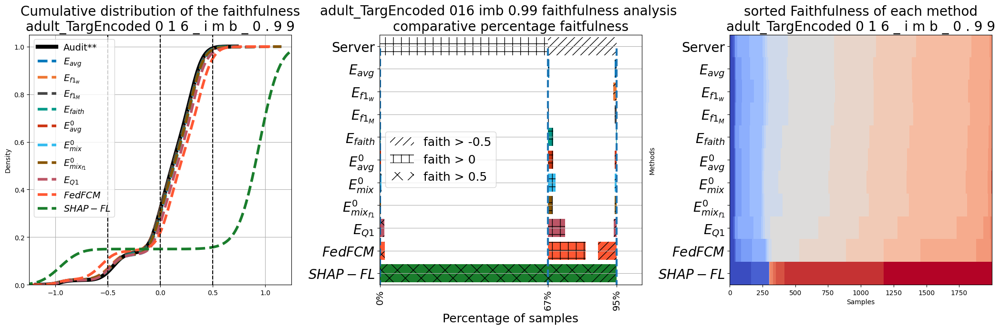

1000
E_hat (2000,)
E_weighted (2000,)
E_f1_macro (2000,)
E_fait_weighted (2000,)
E_avg_t_0 (2000,)
E_mixed (2000,)
E_mix_f1 (2000,)
E_Q1 (2000,)
COMP (2000,)
SHAP_FL (2000,)
Server (2000,)
Clients (16, 2000)
12 recalculated faiths (2 are for the Server, and the Clients)
(2000, 11)
Server	plotted; (1, 2000)		black
E_hat	plotted; (1, 2000)		#0077BB
E_weighted	plotted; (1, 2000)		#EE7733
E_f1_macro	plotted; (1, 2000)		#444444
E_fait_weighted	plotted; (1, 2000)		#009988
E_avg_t_0	plotted; (1, 2000)		#CC3311
E_mixed	plotted; (1, 2000)		#33BBEE
E_mix_f1	plotted; (1, 2000)		#885500
E_Q1	plotted; (1, 2000)		#BB5566
COMP	plotted; (1, 2000)		#FF5733
SHAP_FL	plotted; (1, 2000)		#197D2CFF


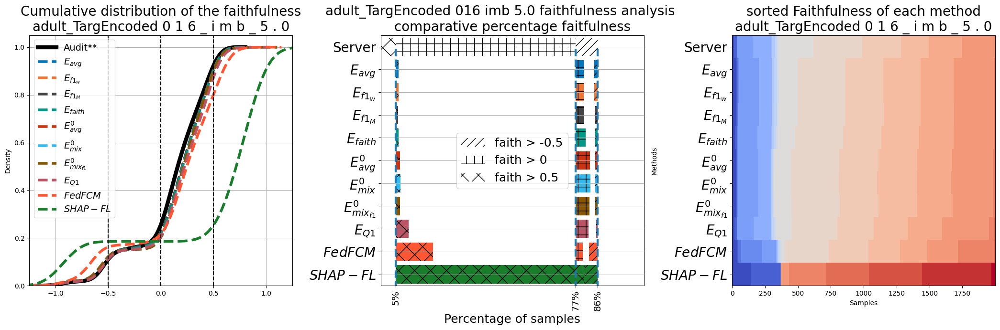

1000
E_hat (2000,)
E_weighted (2000,)
E_f1_macro (2000,)
E_fait_weighted (2000,)
E_avg_t_0 (2000,)
E_mixed (2000,)
E_mix_f1 (2000,)
E_Q1 (2000,)
COMP (2000,)
SHAP_FL (2000,)
Server (2000,)
Clients (16, 2000)
12 recalculated faiths (2 are for the Server, and the Clients)
(2000, 11)
Server	plotted; (1, 2000)		black
E_hat	plotted; (1, 2000)		#0077BB
E_weighted	plotted; (1, 2000)		#EE7733
E_f1_macro	plotted; (1, 2000)		#444444
E_fait_weighted	plotted; (1, 2000)		#009988
E_avg_t_0	plotted; (1, 2000)		#CC3311
E_mixed	plotted; (1, 2000)		#33BBEE
E_mix_f1	plotted; (1, 2000)		#885500
E_Q1	plotted; (1, 2000)		#BB5566
COMP	plotted; (1, 2000)		#FF5733
SHAP_FL	plotted; (1, 2000)		#197D2CFF


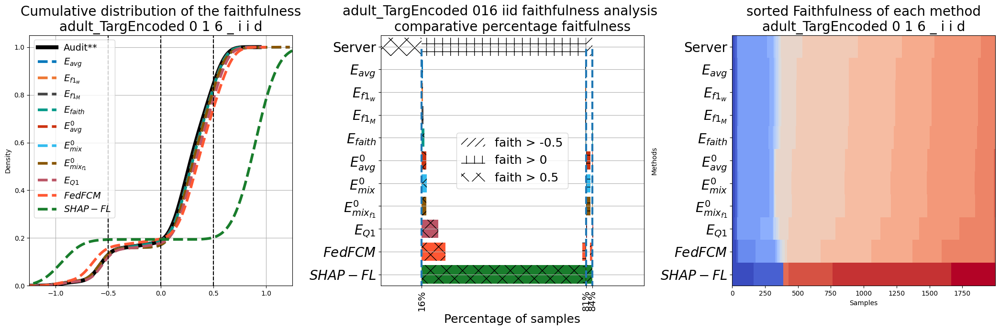

1000
E_hat (2000,)
E_weighted (2000,)
E_f1_macro (2000,)
E_fait_weighted (2000,)
E_avg_t_0 (2000,)
E_mixed (2000,)
E_mix_f1 (2000,)
E_Q1 (2000,)
COMP (2000,)
SHAP_FL (2000,)
Server (2000,)
Clients (12, 2000)
12 recalculated faiths (2 are for the Server, and the Clients)
(2000, 11)
Server	plotted; (1, 2000)		black
E_hat	plotted; (1, 2000)		#0077BB
E_weighted	plotted; (1, 2000)		#EE7733
E_f1_macro	plotted; (1, 2000)		#444444
E_fait_weighted	plotted; (1, 2000)		#009988
E_avg_t_0	plotted; (1, 2000)		#CC3311
E_mixed	plotted; (1, 2000)		#33BBEE
E_mix_f1	plotted; (1, 2000)		#885500
E_Q1	plotted; (1, 2000)		#BB5566
COMP	plotted; (1, 2000)		#FF5733
SHAP_FL	plotted; (1, 2000)		#197D2CFF


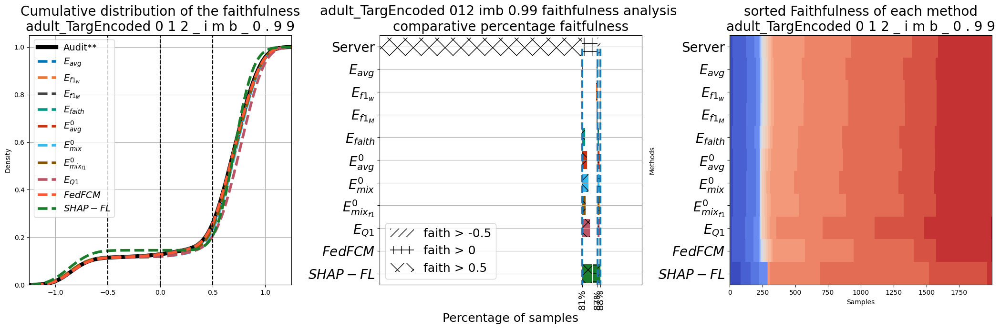

1000
E_hat (2000,)
E_weighted (2000,)
E_f1_macro (2000,)
E_fait_weighted (2000,)
E_avg_t_0 (2000,)
E_mixed (2000,)
E_mix_f1 (2000,)
E_Q1 (2000,)
COMP (2000,)
SHAP_FL (2000,)
Server (2000,)
Clients (12, 2000)
12 recalculated faiths (2 are for the Server, and the Clients)
(2000, 11)
Server	plotted; (1, 2000)		black
E_hat	plotted; (1, 2000)		#0077BB
E_weighted	plotted; (1, 2000)		#EE7733
E_f1_macro	plotted; (1, 2000)		#444444
E_fait_weighted	plotted; (1, 2000)		#009988
E_avg_t_0	plotted; (1, 2000)		#CC3311
E_mixed	plotted; (1, 2000)		#33BBEE
E_mix_f1	plotted; (1, 2000)		#885500
E_Q1	plotted; (1, 2000)		#BB5566
COMP	plotted; (1, 2000)		#FF5733
SHAP_FL	plotted; (1, 2000)		#197D2CFF


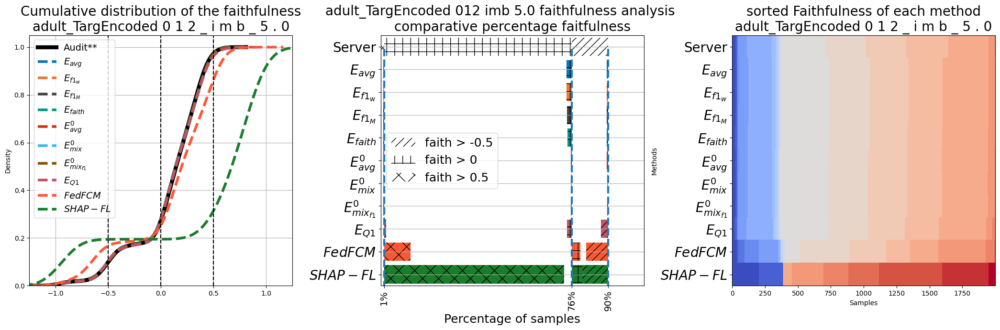

1000
E_hat (2000,)
E_weighted (2000,)
E_f1_macro (2000,)
E_fait_weighted (2000,)
E_avg_t_0 (2000,)
E_mixed (2000,)
E_mix_f1 (2000,)
E_Q1 (2000,)
COMP (2000,)
SHAP_FL (2000,)
Server (2000,)
Clients (12, 2000)
12 recalculated faiths (2 are for the Server, and the Clients)
(2000, 11)
Server	plotted; (1, 2000)		black
E_hat	plotted; (1, 2000)		#0077BB
E_weighted	plotted; (1, 2000)		#EE7733
E_f1_macro	plotted; (1, 2000)		#444444
E_fait_weighted	plotted; (1, 2000)		#009988
E_avg_t_0	plotted; (1, 2000)		#CC3311
E_mixed	plotted; (1, 2000)		#33BBEE
E_mix_f1	plotted; (1, 2000)		#885500
E_Q1	plotted; (1, 2000)		#BB5566
COMP	plotted; (1, 2000)		#FF5733
SHAP_FL	plotted; (1, 2000)		#197D2CFF


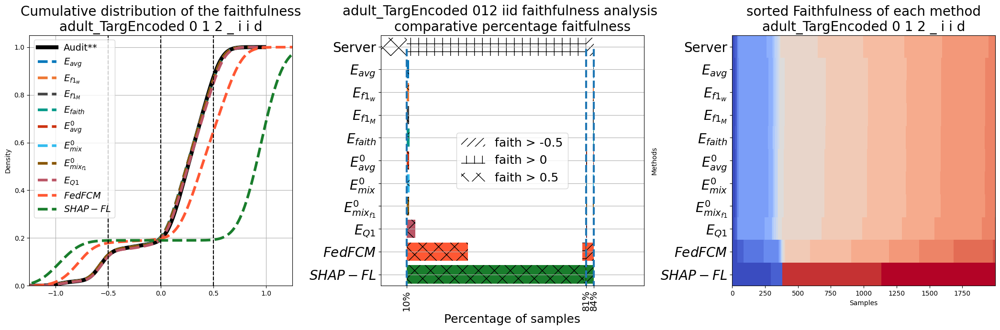

In [99]:

for exp in focus:
    print(b_v)
    all_faith_dict_recomputed[exp][b_v]["Clients"] = all_faith_dict[exp][b_v]["Clients"]
    for k in all_faith_dict_recomputed[exp][b_v].keys():
        print(k,all_faith_dict_recomputed[exp][b_v][k].shape)
        if k!="Clients":
            if all_faith_dict_recomputed[exp][b_v][k].shape[0]==2:# there is the error
                all_faith_dict_recomputed[exp][b_v][k] = all_faith_dict_recomputed[exp][b_v][k][1,:].reshape(1,-1)
            if all_faith_dict_recomputed[exp][b_v][k].shape[0] != 1:
                all_faith_dict_recomputed[exp][b_v][k] = all_faith_dict_recomputed[exp][b_v][k].reshape(1,-1)
    plot_recalulated_faiths(exp =exp,
                        faiths = all_faith_dict_recomputed,
                        base_value = b_v,
                        proposals = props,
                        dt_name=dt_name,
                        show=True)

    plt.show()

In [125]:
#!code {dt_name}_all_faithfulness_analysis_post.pdf

In [100]:
all_faith_dict_recomputed.keys()

dict_keys(['016_imb_0.99', '016_imb_5.0', '016_iid', '012_imb_0.99', '012_imb_5.0', '012_iid'])

### Faithfunes comparison
CD diagrams


In [101]:
import importlib
importlib.reload(flx)
import iflash as flx
from iflash import *
all_faith_dict["016_iid"]

{-0.5: {'Server': array([ 0.01864401, -0.04228187, -0.23897488, ..., -0.20387311,
         -0.17548901, -0.07536641]),
  'Clients': array([[-0.00071506, -0.07764259, -0.27402004, ..., -0.22750553,
          -0.20128509, -0.04339201],
         [-0.00368426, -0.07709217, -0.26621284, ..., -0.22133839,
          -0.19589738, -0.03902082],
         [ 0.01017347, -0.08270679, -0.26636417, ..., -0.2258959 ,
          -0.20280635, -0.04899689],
         ...,
         [ 0.02091147, -0.04203471, -0.25181896, ..., -0.20858971,
          -0.17856482, -0.08240214],
         [ 0.02358325, -0.04869129, -0.24573363, ..., -0.21575001,
          -0.18919036, -0.08703819],
         [ 0.02020987, -0.03607691, -0.23230746, ..., -0.20591634,
          -0.17637704, -0.09254465]])},
 -0.2: {'Server': array([ 2.53686444e-01,  2.30680045e-01, -2.91684139e-05, ...,
         -1.24404082e-02,  4.29501500e-02, -2.95609967e-01]),
  'Clients': array([[ 0.23898996,  0.19419452, -0.03408516, ..., -0.02851142,
        

dict_keys(['E_hat', 'E_weighted', 'E_f1_macro', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1', 'COMP', 'SHAP_FL', 'Server', 'Clients'])
(11, 2000)
{'$E_{avg}$': '#0077BB', '$E_{f1_w}$': '#EE7733', '$E_{faith}$': '#009988', '$E_{avg}^{0}$': '#CC3311', '$E_{mix}^{0}$': '#33BBEE', '$E_{mix_{f1}}^0$': '#885500', '$E_{avg}^{-0.6}$': '#DDAA33', '$E_{f1_{M}}$': '#444444', '$E_{faith}^{-0.6}$': '#004488', '$E_{Q1}$': '#BB5566', 'Audit**': '#000000', '$FedFCM$': '#FF5733', '$SHAP-FL$': '#197D2CFF'} res_colors
Index(['$E_{avg}$', '$E_{f1_w}$', '$E_{f1_{M}}$', '$E_{faith}$',
       '$E_{avg}^{0}$', '$E_{mix}^{0}$', '$E_{mix_{f1}}^0$', '$E_{Q1}$',
       '$FedFCM$', '$SHAP-FL$', 'Audit**'],
      dtype='object') columns of the ranking_df
plotting CD diagram


                  $E_{avg}$  $E_{f1_w}$  $E_{f1_{M}}$  $E_{faith}$  \
$E_{avg}$               1.0         0.0           0.0          0.0   
$E_{f1_w}$              0.0         1.0           0.0          0.0   
$E_{f1_{M}}$            0.0         0.0           1.0          0.0   
$E_{faith}$             0.0         0.0           0.0          1.0   
$E_{avg}^{0}$           0.9         0.0           0.0          0.0   
$E_{mix}^{0}$           0.0         0.0           0.0          0.0   
$E_{mix_{f1}}^0$        0.0         0.0           0.9          0.0   
$E_{Q1}$                0.0         0.0           0.0          0.0   
$FedFCM$                0.0         0.0           0.0          0.0   
$SHAP-FL$               0.0         0.0           0.0          0.0   
Audit**                 0.0         0.0           0.0          0.0   

                  $E_{avg}^{0}$  $E_{mix}^{0}$  $E_{mix_{f1}}^0$  $E_{Q1}$  \
$E_{avg}$                   0.9            0.0               0.0       0.0   
$E_

<Figure size 640x480 with 0 Axes>

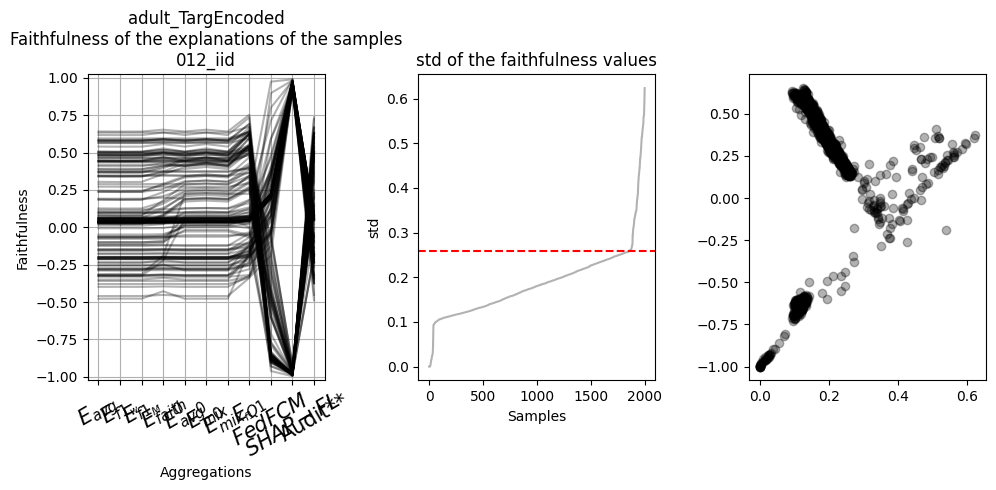

dict_keys(['E_hat', 'E_weighted', 'E_f1_macro', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1', 'COMP', 'SHAP_FL', 'Server', 'Clients'])
(11, 2000)
{'$E_{avg}$': '#0077BB', '$E_{f1_w}$': '#EE7733', '$E_{faith}$': '#009988', '$E_{avg}^{0}$': '#CC3311', '$E_{mix}^{0}$': '#33BBEE', '$E_{mix_{f1}}^0$': '#885500', '$E_{avg}^{-0.6}$': '#DDAA33', '$E_{f1_{M}}$': '#444444', '$E_{faith}^{-0.6}$': '#004488', '$E_{Q1}$': '#BB5566', 'Audit**': '#000000', '$FedFCM$': '#FF5733', '$SHAP-FL$': '#197D2CFF'} res_colors
Index(['$E_{avg}$', '$E_{f1_w}$', '$E_{f1_{M}}$', '$E_{faith}$',
       '$E_{avg}^{0}$', '$E_{mix}^{0}$', '$E_{mix_{f1}}^0$', '$E_{Q1}$',
       '$FedFCM$', '$SHAP-FL$', 'Audit**'],
      dtype='object') columns of the ranking_df
plotting CD diagram
                  $E_{avg}$  $E_{f1_w}$  $E_{f1_{M}}$  $E_{faith}$  \
$E_{avg}$               1.0        0.00          0.00          0.0   
$E_{f1_w}$              0.0        1.00          0.23          0.0   
$E_{f1_{M}}$      

<Figure size 640x480 with 0 Axes>

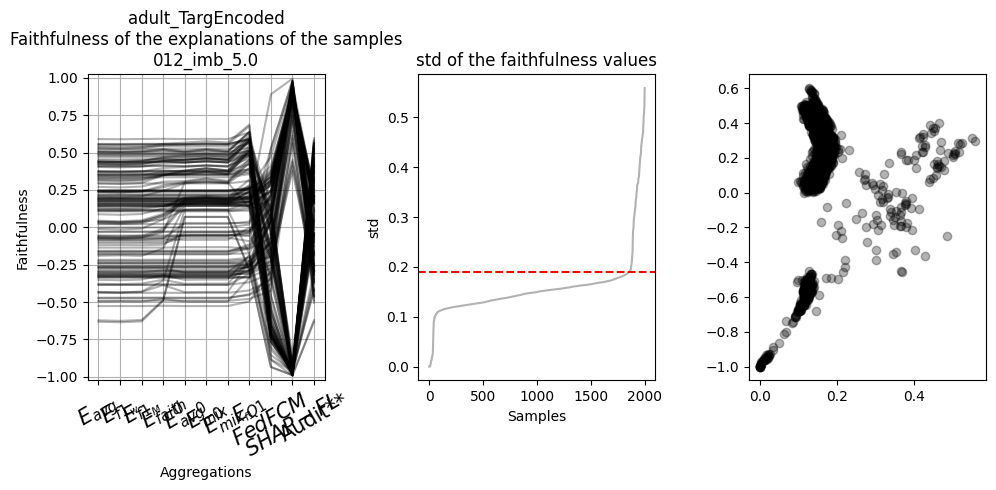

dict_keys(['E_hat', 'E_weighted', 'E_f1_macro', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1', 'COMP', 'SHAP_FL', 'Server', 'Clients'])
(11, 2000)
{'$E_{avg}$': '#0077BB', '$E_{f1_w}$': '#EE7733', '$E_{faith}$': '#009988', '$E_{avg}^{0}$': '#CC3311', '$E_{mix}^{0}$': '#33BBEE', '$E_{mix_{f1}}^0$': '#885500', '$E_{avg}^{-0.6}$': '#DDAA33', '$E_{f1_{M}}$': '#444444', '$E_{faith}^{-0.6}$': '#004488', '$E_{Q1}$': '#BB5566', 'Audit**': '#000000', '$FedFCM$': '#FF5733', '$SHAP-FL$': '#197D2CFF'} res_colors
Index(['$E_{avg}$', '$E_{f1_w}$', '$E_{f1_{M}}$', '$E_{faith}$',
       '$E_{avg}^{0}$', '$E_{mix}^{0}$', '$E_{mix_{f1}}^0$', '$E_{Q1}$',
       '$FedFCM$', '$SHAP-FL$', 'Audit**'],
      dtype='object') columns of the ranking_df
plotting CD diagram
                  $E_{avg}$  $E_{f1_w}$  $E_{f1_{M}}$  $E_{faith}$  \
$E_{avg}$               1.0         0.0           0.0          0.0   
$E_{f1_w}$              0.0         1.0           0.9          0.0   
$E_{f1_{M}}$      

<Figure size 640x480 with 0 Axes>

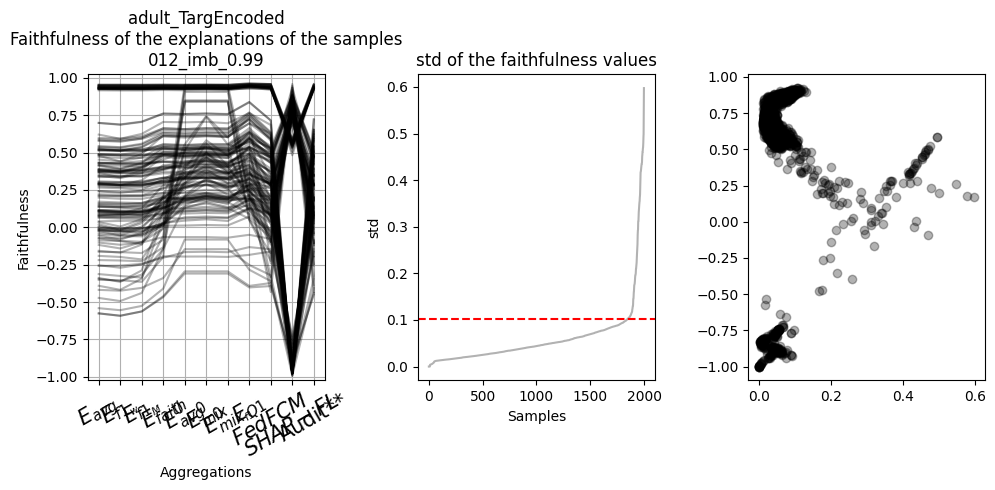

dict_keys(['E_hat', 'E_weighted', 'E_f1_macro', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1', 'COMP', 'SHAP_FL', 'Server', 'Clients'])
(11, 2000)
{'$E_{avg}$': '#0077BB', '$E_{f1_w}$': '#EE7733', '$E_{faith}$': '#009988', '$E_{avg}^{0}$': '#CC3311', '$E_{mix}^{0}$': '#33BBEE', '$E_{mix_{f1}}^0$': '#885500', '$E_{avg}^{-0.6}$': '#DDAA33', '$E_{f1_{M}}$': '#444444', '$E_{faith}^{-0.6}$': '#004488', '$E_{Q1}$': '#BB5566', 'Audit**': '#000000', '$FedFCM$': '#FF5733', '$SHAP-FL$': '#197D2CFF'} res_colors
Index(['$E_{avg}$', '$E_{f1_w}$', '$E_{f1_{M}}$', '$E_{faith}$',
       '$E_{avg}^{0}$', '$E_{mix}^{0}$', '$E_{mix_{f1}}^0$', '$E_{Q1}$',
       '$FedFCM$', '$SHAP-FL$', 'Audit**'],
      dtype='object') columns of the ranking_df
plotting CD diagram
                  $E_{avg}$  $E_{f1_w}$  $E_{f1_{M}}$  $E_{faith}$  \
$E_{avg}$              1.00         0.0          0.00          0.0   
$E_{f1_w}$             0.00         1.0          0.00          0.0   
$E_{f1_{M}}$      

<Figure size 640x480 with 0 Axes>

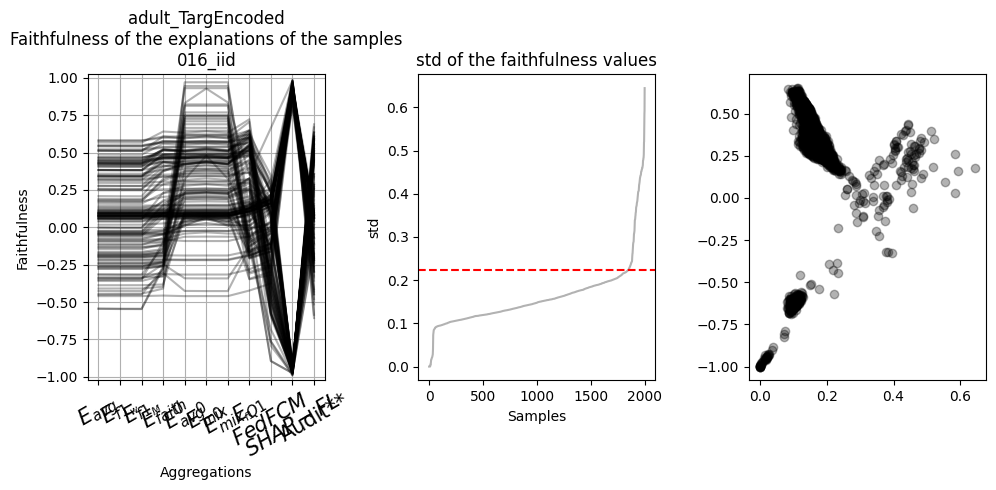

dict_keys(['E_hat', 'E_weighted', 'E_f1_macro', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1', 'COMP', 'SHAP_FL', 'Server', 'Clients'])
(11, 2000)
{'$E_{avg}$': '#0077BB', '$E_{f1_w}$': '#EE7733', '$E_{faith}$': '#009988', '$E_{avg}^{0}$': '#CC3311', '$E_{mix}^{0}$': '#33BBEE', '$E_{mix_{f1}}^0$': '#885500', '$E_{avg}^{-0.6}$': '#DDAA33', '$E_{f1_{M}}$': '#444444', '$E_{faith}^{-0.6}$': '#004488', '$E_{Q1}$': '#BB5566', 'Audit**': '#000000', '$FedFCM$': '#FF5733', '$SHAP-FL$': '#197D2CFF'} res_colors
Index(['$E_{avg}$', '$E_{f1_w}$', '$E_{f1_{M}}$', '$E_{faith}$',
       '$E_{avg}^{0}$', '$E_{mix}^{0}$', '$E_{mix_{f1}}^0$', '$E_{Q1}$',
       '$FedFCM$', '$SHAP-FL$', 'Audit**'],
      dtype='object') columns of the ranking_df
plotting CD diagram
                  $E_{avg}$  $E_{f1_w}$  $E_{f1_{M}}$  $E_{faith}$  \
$E_{avg}$              1.00        0.90          0.00          0.0   
$E_{f1_w}$             0.90        1.00          0.00          0.0   
$E_{f1_{M}}$      

<Figure size 640x480 with 0 Axes>

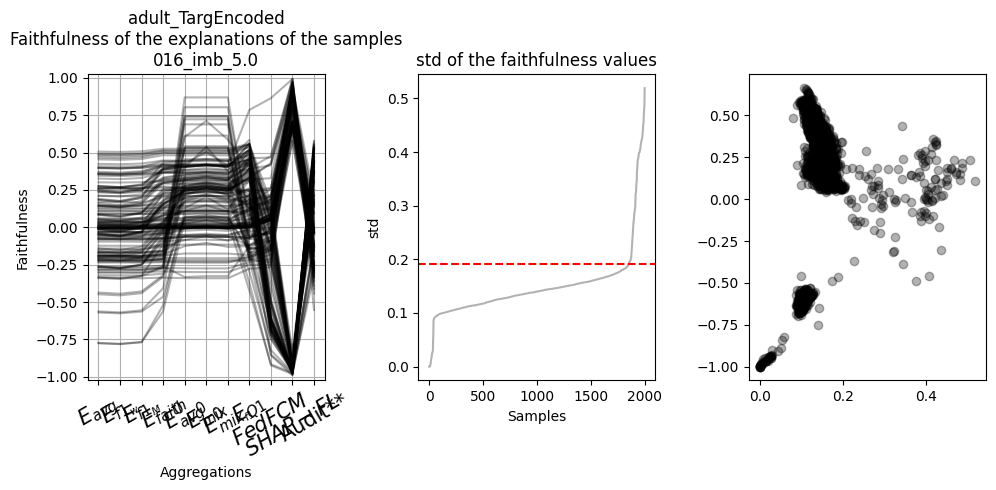

dict_keys(['E_hat', 'E_weighted', 'E_f1_macro', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1', 'COMP', 'SHAP_FL', 'Server', 'Clients'])
(11, 2000)
{'$E_{avg}$': '#0077BB', '$E_{f1_w}$': '#EE7733', '$E_{faith}$': '#009988', '$E_{avg}^{0}$': '#CC3311', '$E_{mix}^{0}$': '#33BBEE', '$E_{mix_{f1}}^0$': '#885500', '$E_{avg}^{-0.6}$': '#DDAA33', '$E_{f1_{M}}$': '#444444', '$E_{faith}^{-0.6}$': '#004488', '$E_{Q1}$': '#BB5566', 'Audit**': '#000000', '$FedFCM$': '#FF5733', '$SHAP-FL$': '#197D2CFF'} res_colors
Index(['$E_{avg}$', '$E_{f1_w}$', '$E_{f1_{M}}$', '$E_{faith}$',
       '$E_{avg}^{0}$', '$E_{mix}^{0}$', '$E_{mix_{f1}}^0$', '$E_{Q1}$',
       '$FedFCM$', '$SHAP-FL$', 'Audit**'],
      dtype='object') columns of the ranking_df
plotting CD diagram
                  $E_{avg}$  $E_{f1_w}$  $E_{f1_{M}}$  $E_{faith}$  \
$E_{avg}$              1.00         0.0          0.00          0.0   
$E_{f1_w}$             0.00         1.0          0.00          0.0   
$E_{f1_{M}}$      

<Figure size 640x480 with 0 Axes>

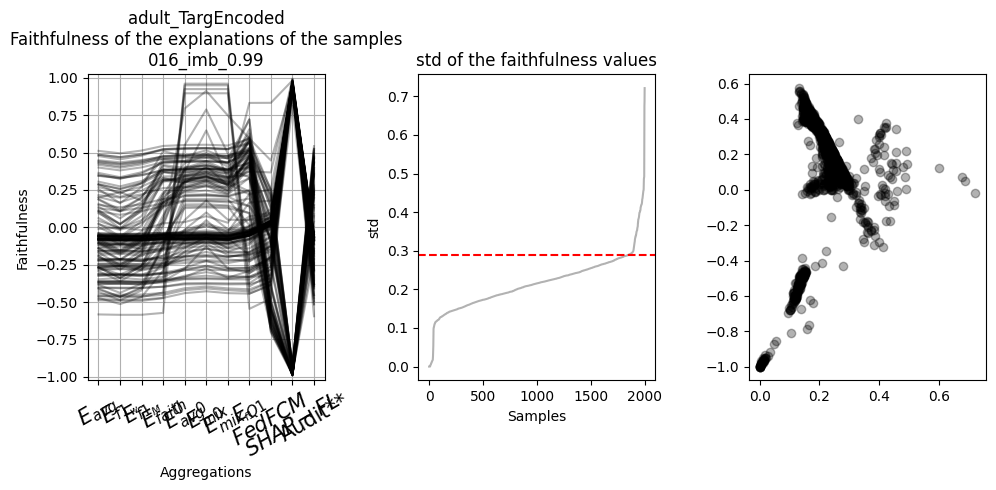

In [102]:
SHOWW = False
for p in partitions:
    for d in distribs:
        # now we plot the faithfulnesses:
        exp = p+"_"+d

        # now we want to produce the cd diagrams for the faithfulness values as well, for the same aggregations and the server
        # as "metric" we use the faithfulness values
        # as for the metric functions, the higher the value the better
        # so we do not need to flip the values
        all_faith_dict_list = all_faith_dict_recomputed[exp][b_v]
        print(all_faith_dict_recomputed[exp][b_v].keys())
        dict_vals = np.array([np.array(all_faith_dict_list[p]).reshape(-1) for p in props+["Server"]])
        print(dict_vals.shape)
        
        
        
        dict_vals = dict_vals.T
        metr = "Faithfulness"
        name_dataset = "Adult" if "adult" in dt_name.lower() else "Diamonds" if "diamond" in dt_name.lower() else "Dry Bean" if "bean" in dt_name.lower() else "income" if "income" in dt_name.lower() else "Dutch" if "dutch" in dt_name.lower() else "dataset name"
        current_title = name_dataset+" "+(" ".join([str(elemento) for elemento in exp])if not isinstance(exp,str) else " ".join((exp.replace("imb","$\\alpha$")).split("_")))+": "+metr+" "
        create_df_and_check(methods_names=props+["Server"],
                                values=-dict_vals,
                                title=current_title,
                                show = SHOWW,
                                exp = exp,
                                metrica=metr,
                                dt_name=dt_name,
                                vmin=-1.025,vmax=1.025,
                                hmargin = 0.01,
                                vertica_image_size=6)
        plt.clf()
        fig, ax = plt.subplots(1,3,figsize=(10,5))
        
        # select the samples with std of the faithfulness values higher than 0.2
        # and plot the faithfulness values of the samples
        stds = np.std(dict_vals,axis=1)
        print(stds.shape)
        # find the knee of the stds
        std_sorted = np.sort(stds)
        tresh = std_sorted[-150]
        #tresh = 0.05
        idx_stds = stds>tresh
        print(idx_stds.shape,dict_vals[idx_stds,:].shape)
        print(idx_stds.sum()/len(idx_stds),dict_vals.shape)

        ax[0].plot(dict_vals[idx_stds,:].T,alpha=0.3,c='black')
        #set the xticks
        ax[0].set_xticks(np.arange(len(props)+1),
                [res_d[pn] for pn in props+["Server"]]
                ,rotation=30,fontsize=15)
        ax[0].set_ylabel("Faithfulness")
        ax[0].set_title(dt_name+"\n"+"Faithfulness of the explanations of the samples"+"\n"+exp)
        ax[0].grid(True)
        ax[0].set_ylim(-1.025,1.025)
        ax[0].set_xlabel("Aggregations")
        # in the other ax plot the other with std < 0.2
        ax[1].plot(sorted(stds),alpha=0.3,c='black')
        ax[1].set_title("std of the faithfulness values")
        ax[1].set_ylabel("std")
        ax[1].set_xlabel("Samples")
        # add a horizontal line to separate the samples with std > 0.2
        ax[1].axhline(tresh,ls='--',c='red')

        # now plot the scatter of the std and the mean value of the faithfulness values
        ax[2].scatter(stds,dict_vals.mean(1),alpha=0.3,c='black')
        plt.tight_layout()
        #plt.savefig("cddiagrams/"+dt_name+"_"+exp+"_faithfulness.pdf")
        plt.show()

## The plots with the joined faithfulness scores and the L2 distances

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


check file plots/adult_TargEncoded_1000_shap_016_imb_0.99_faithfulness_vs_L2.pdf


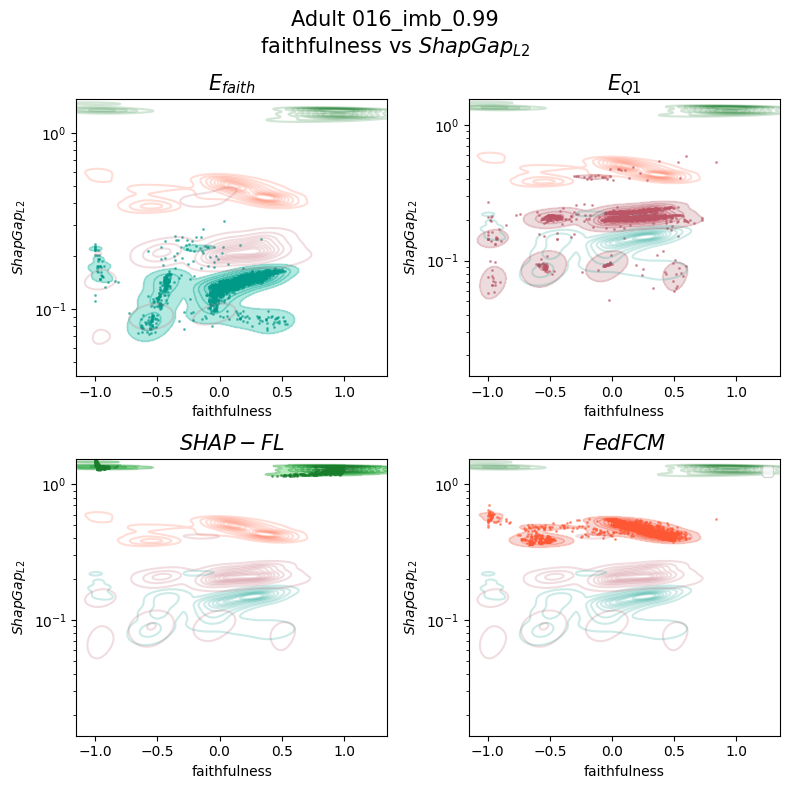

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


check file plots/adult_TargEncoded_1000_shap_016_imb_5.0_faithfulness_vs_L2.pdf


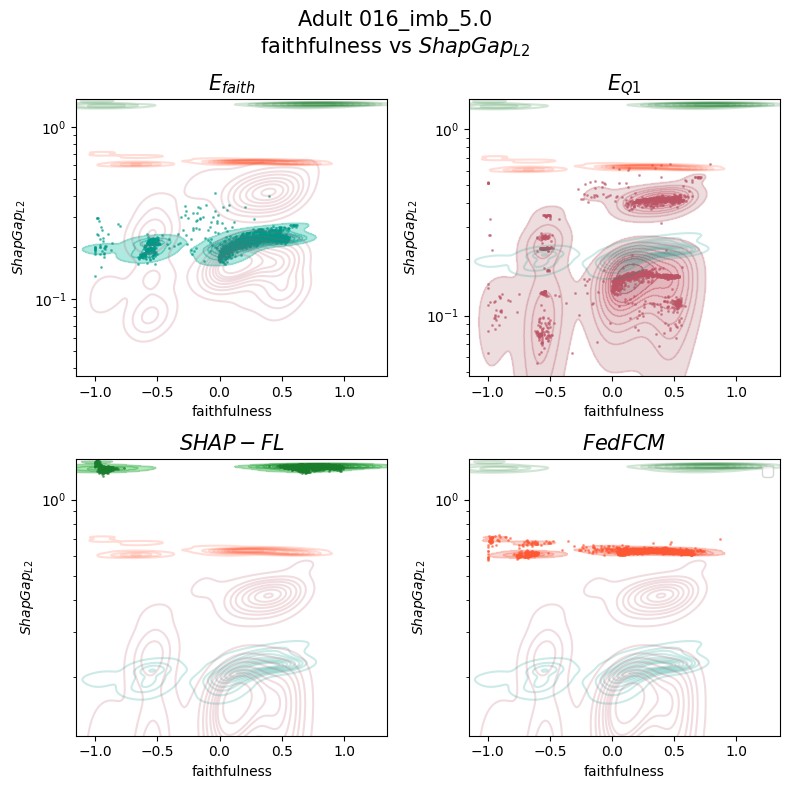

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


check file plots/adult_TargEncoded_1000_shap_016_iid_faithfulness_vs_L2.pdf


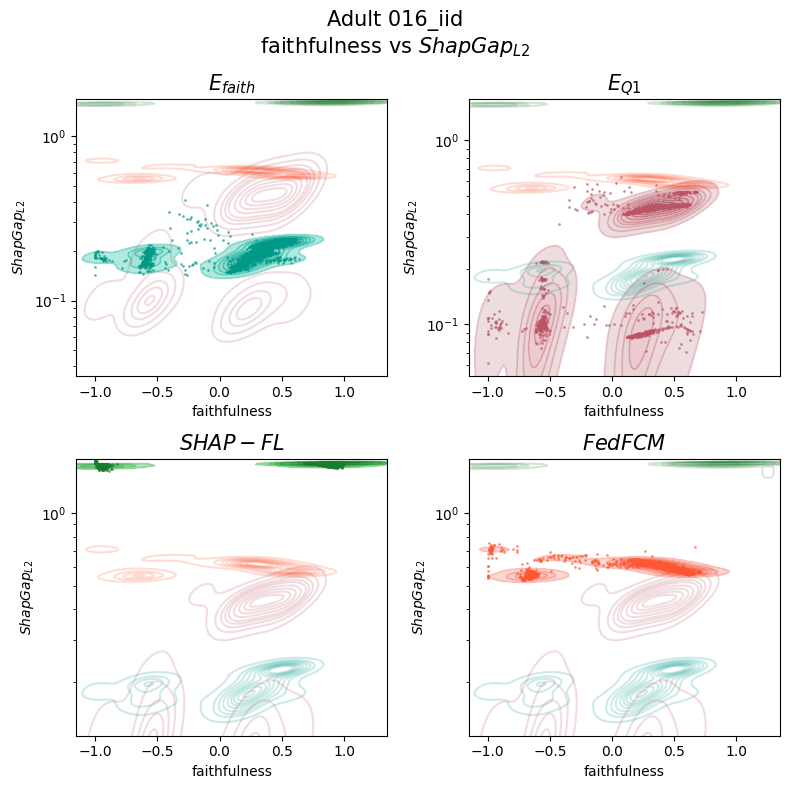

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


check file plots/adult_TargEncoded_1000_shap_012_imb_0.99_faithfulness_vs_L2.pdf


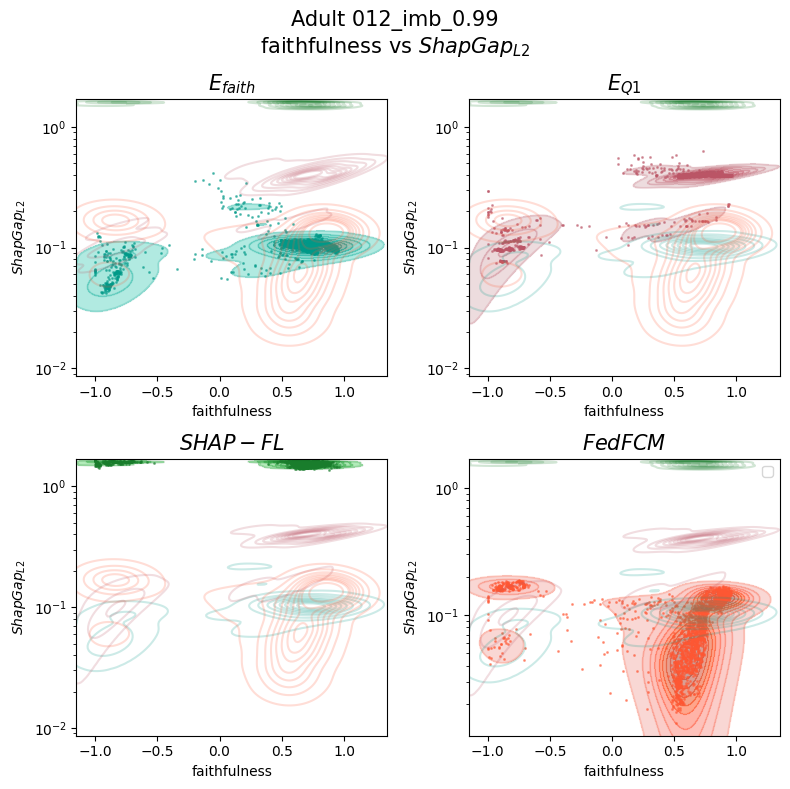

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


check file plots/adult_TargEncoded_1000_shap_012_imb_5.0_faithfulness_vs_L2.pdf


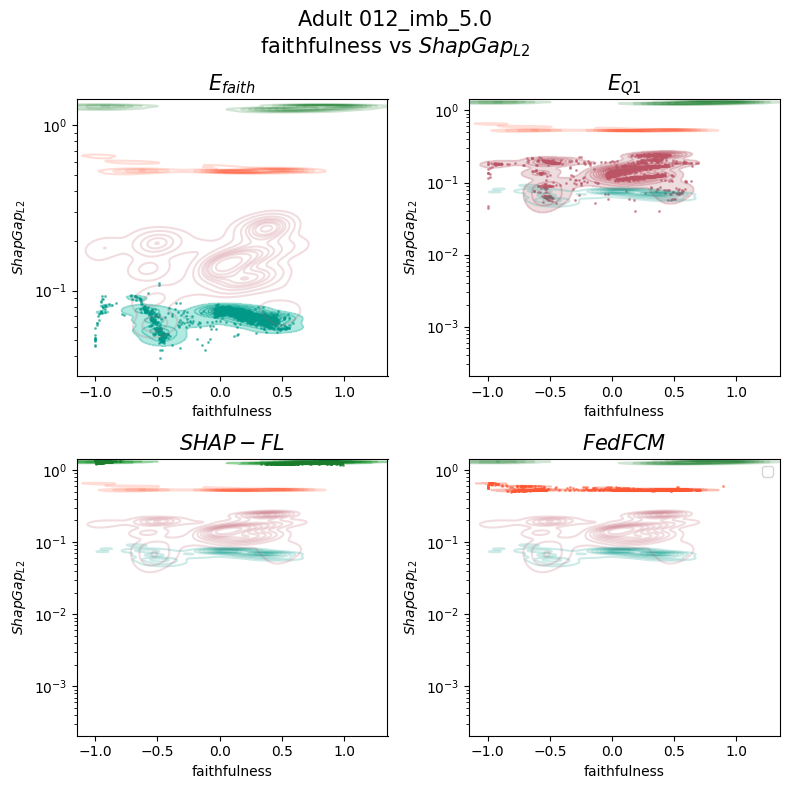

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


check file plots/adult_TargEncoded_1000_shap_012_iid_faithfulness_vs_L2.pdf


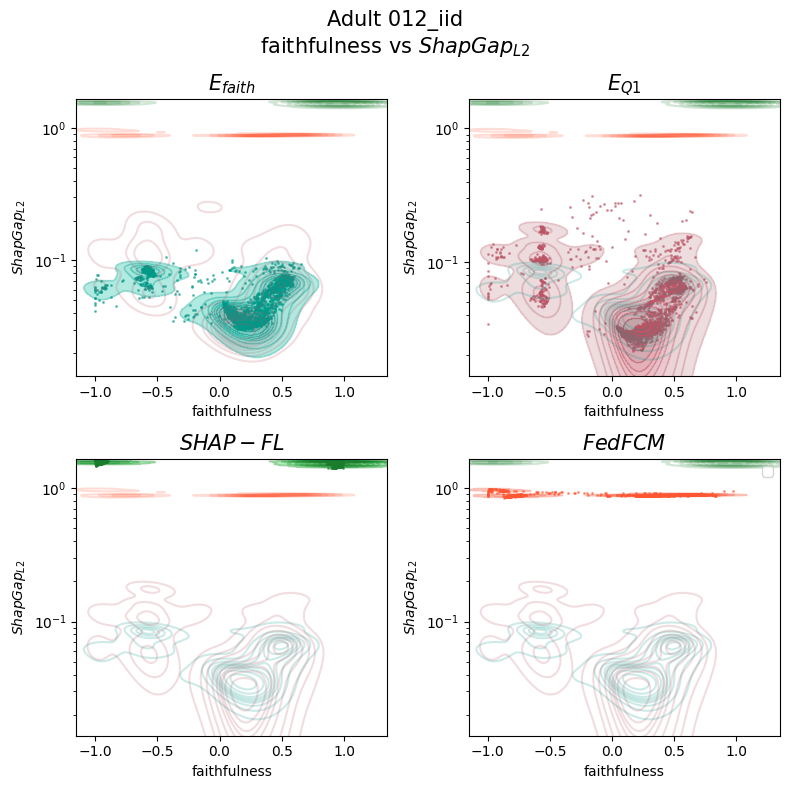

In [103]:
focus_props = ["E_fait_weighted","E_Q1","SHAP_FL","COMP"]
# i want to plot now a thing. let's start by producing a scattering plot of the faithfulness values of the samples and the L2 norm of the explanations
for exp in focus:
    # QUIQUOQUA
    fix,ax = plt.subplots(2,2,figsize=(8,8))
    ax=ax.flatten()
    # add all the faithfulness values of the samples and the L2 norms of the explanations per aggregation
    data_d = {}
    for j,p in enumerate(focus_props):
        data_d[p] = {"faithfulness":np.array(all_faith_dict_recomputed[exp][b_v][p]).flatten(),
                     "L2":compare_heatmaps_Frobenius(all_shap_values_dict_loaded[exp]["Server"],all_shap_values_dict_loaded[exp][p])}
    for j,p in enumerate(focus_props):
        data = pd.DataFrame(data_d[p])
        
        sns.kdeplot(data=data,x="faithfulness",y="L2",label=res_d[p],ax=ax[j],fill=True,color=colors[p],alpha=0.5)
        ax[j].scatter(data["faithfulness"],data["L2"],c=colors[p],alpha=0.5,s=5,marker=".")
        for jj,axe in enumerate(ax):
            if jj>=len(focus_props):
                axe.set_visible(False)
            else:
                sns.kdeplot(data=data,x="faithfulness",y="L2",ax=axe,fill=False,color=colors[p],label='',alpha=0.2)

        ax[j].set_title(res_d[p],fontsize=15)
        ax[j].set_xlabel("faithfulness")
        ax[j].set_ylabel("$ShapGap_{L2}$")
        ax[j].set_xlim(-1.15,1.35)
        #ax[j].set_ylim(0.05)
        # set the logscale on y
        ax[j].set_yscale('log')
        

    # in the last plot we plot the faithfulness values of the samples and the L2 norm of the explanations of the server
    # the L2 is trivially 0, so we plot only the faithfulness kde values, without a 1d kde plot
    #sns.kdeplot(all_faith_dict_recomputed[exp][b_v]["Server"][0],fill=True,label="",ax=ax[-1],color=colors["Server"])
    #ax[-1].set_title("Server")
    # remove the y ticks from the last plot
    #ax[-1].set_yticks([])
    plt.suptitle(name_dataset+" "+exp+"\nfaithfulness vs $ShapGap_{L2}$",fontsize=15)
    plt.tight_layout()
    plt.legend()
    fname = "plots/"+dt_name+"_"+f'{b_v}'+"_"+explainer_folder_name+"_"+exp+"_faithfulness_vs_L2.pdf"
    plt.savefig(fname)
    print("check file",fname)

    plt.show()
    # create the dataframe
    # create the scatter plot

In [107]:
_all_faith_dict_recomputed['016_imb_0.99'].keys()

dict_keys([1000])

In [108]:
explainer_folder_name

'shap'

In [106]:
# Now save the all_faith_dict_recomputed as a json file, but first convert the numpy arrays to lists

#all_faith_dict_recomputed = {k: {k2: {k3: np.nan_to_num(v3).tolist() for k3, v3 in v2.items()} for k2, v2 in vv.items()} for k, vv in all_faith_dict_recomputed.items()}
with open(dt_name+"_all_faith_dict_"+explainer_folder_name+"_recomputed.json", "w") as f:
    _all_faith_dict_recomputed = {k: {k2: {k3: np.nan_to_num(v3).tolist() for k3, v3 in v2.items()} for k2, v2 in vv.items()} for k, vv in all_faith_dict_recomputed.items()}
    json.dump(_all_faith_dict_recomputed, f)

print("wrote on file", dt_name+"_all_faith_dict_"+explainer_folder_name+"_recomputed.json")


wrote on file adult_TargEncoded_all_faith_dict_shap_recomputed.json


### For the other metric use the plot_inter.ipynb notebook file


In [134]:
with open(dt_name+"_all_faith_dict_"+explainer_folder_name+"_recomputed.json", "r") as f:
    recomputed_loaded_faith_dict = json.load(f)
all_faith_dict_recomputed_loaded = {
    k: {
        float(k2): {k3: np.array(v3) for k3, v3 in v2.items()}
        for k2, v2 in vv.items()
    }
    for k, vv in recomputed_loaded_faith_dict.items()
}
print("read from file", dt_name+"_all_faith_dict_"+explainer_folder_name+"_recomputed.json")

read from file dry_bean_all_faith_dict_shap_recomputed.json


In [135]:
k = "016_iid"
print(all_faith_dict_recomputed_loaded[k][b_v])

{'E_hat': array([[-0.84440498,  0.09812002, -0.72346074, ..., -0.72296356,
        -0.3796185 ,  0.54272075]]), 'E_weighted': array([[-0.84424877,  0.09825981, -0.72341234, ..., -0.72274745,
        -0.37945187,  0.54267208]]), 'E_f1_macro': array([[-0.84423733,  0.09820616, -0.72341719, ..., -0.72275075,
        -0.37939698,  0.54270222]]), 'E_fait_weighted': array([[-0.83616592,  0.1012517 , -0.72120789, ..., -0.69411064,
        -0.37105301,  0.5450703 ]]), 'E_avg_t_0': array([[-0.84440498,  0.10510721, -0.72346074, ..., -0.72296356,
        -0.3796185 ,  0.54272075]]), 'E_mixed': array([[-0.84423733,  0.10766727, -0.72341719, ..., -0.72275075,
        -0.37939698,  0.5450703 ]]), 'E_mix_f1': array([[-0.84423733,  0.105184  , -0.72341719, ..., -0.72275075,
        -0.37939698,  0.54270222]]), 'E_Q1': array([[-0.78167326,  0.17229658, -0.70651692, ..., -0.59855623,
        -0.30233733,  0.63139877]]), 'COMP': array([[-0.84577763, -0.0051925 , -0.69269555, ..., -0.68223096,
        -0

In [124]:

valueminmax_diamond = [(-0.5,1.025)]+\
    [(-0.025,2.35)]+\
        [(0.74,1.025)]
valueminmax_adult = [(-0.5,1.025)]+\
    [(-0.025,0.5)]+\
        [(0.8,1.025)]
valueminmax = [(0.5,1.025)]+\
    [(-0.025,1.7)]+\
        [(0.8,1.025)]+\
            [(0.5,1.025)]

for metr,metr_f,(vm,vM) in zip(metriche,
                               metric_functions,
                               valueminmax):
    for exp in focus:
            dict_vals = []
            print(metr)
            
            for p in props:
                print(p)
                vals = metr_f(all_shap_values_dict_loaded[exp]["Server"],all_shap_values_dict_loaded[exp][p])
                if metr != "$ShapGap_{L2}$":
                    # we multiply the values for -1 because the Frobenius distance is a distance, so the higher the value the worse
                    print("flipped",metr)
                    vals *=-1
                dict_vals.append(vals)
            dict_vals = np.array(dict_vals)
            print(dict_vals.shape)
            current_title = dt_name+" "+(" ".join([str(elemento) for elemento in exp])if not isinstance(exp,str) else " ".join((exp.replace("imb","$\\alpha$")).split("_")))+"\n"+metr+" "
            create_df_and_check(methods_names=props,
                                values=dict_vals.T,
                                title=current_title,
                                show=SHOWW,
                                exp=exp,
                                metrica=metr,
                                dt_name = dt_name,
                                vmin=vm,vmax=vM,
                                vertica_image_size=5.5,)
            plt.clf()
                # do the kde plot of the values of the metric and the faithfulness values using the kde plot

$ShapGap_{Kendall}$
E_hat
flipped $ShapGap_{Kendall}$
E_weighted
flipped $ShapGap_{Kendall}$
E_f1_macro
flipped $ShapGap_{Kendall}$
E_fait_weighted
flipped $ShapGap_{Kendall}$
E_avg_t_0
flipped $ShapGap_{Kendall}$
E_mixed
flipped $ShapGap_{Kendall}$
E_mix_f1
flipped $ShapGap_{Kendall}$
E_Q1
flipped $ShapGap_{Kendall}$
COMP
flipped $ShapGap_{Kendall}$
SHAP_FL
flipped $ShapGap_{Kendall}$
(10, 2000)
{'$E_{avg}$': '#0077BB', '$E_{f1_w}$': '#EE7733', '$E_{faith}$': '#009988', '$E_{avg}^{0}$': '#CC3311', '$E_{mix}^{0}$': '#33BBEE', '$E_{mix_{f1}}^0$': '#885500', '$E_{avg}^{-0.6}$': '#DDAA33', '$E_{f1_{M}}$': '#444444', '$E_{faith}^{-0.6}$': '#004488', '$E_{Q1}$': '#BB5566', 'Audit**': '#000000', '$FedFCM$': '#FF5733', '$SHAP-FL$': '#197D2CFF'} res_colors
Index(['$E_{avg}$', '$E_{f1_w}$', '$E_{f1_{M}}$', '$E_{faith}$',
       '$E_{avg}^{0}$', '$E_{mix}^{0}$', '$E_{mix_{f1}}^0$', '$E_{Q1}$',
       '$FedFCM$', '$SHAP-FL$'],
      dtype='object') columns of the ranking_df
plotting CD diagram
  

<Figure size 640x480 with 0 Axes>

352.8

In [139]:
# check the content of the _all_faith_dict_recomputed
for exp in focus:
    for b_v in all_faith_dict_recomputed_loaded[exp].keys():
        print(exp,b_v)
        for k in all_faith_dict_recomputed_loaded[exp][b_v].keys():
            print("\t",k,all_faith_dict_recomputed_loaded[exp][b_v][k].shape)

NameError: name 'all_faith_dict_recomputed_loaded' is not defined

016_imb_0.99


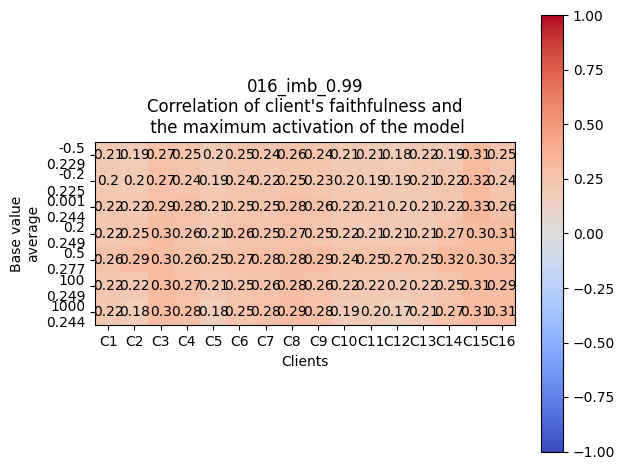

016_imb_5.0


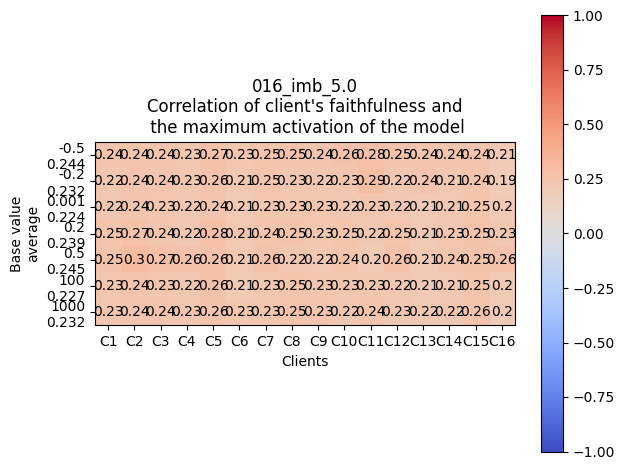

016_iid


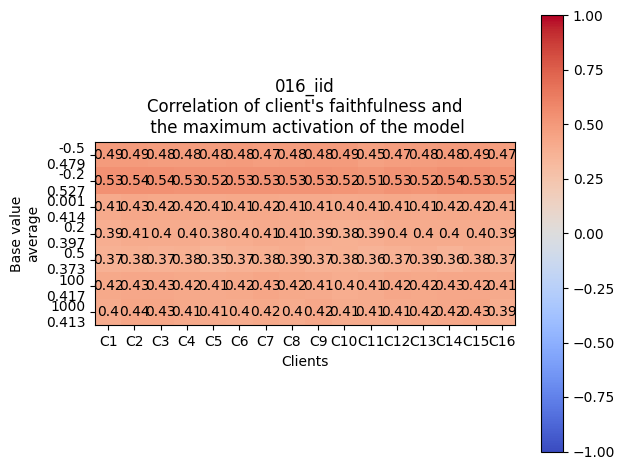

012_imb_0.99


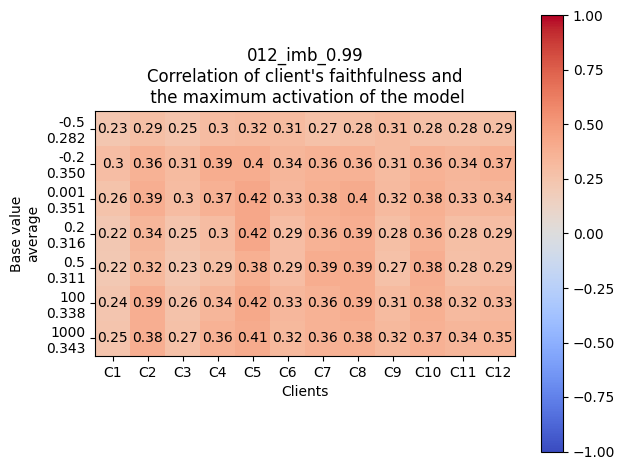

012_imb_5.0


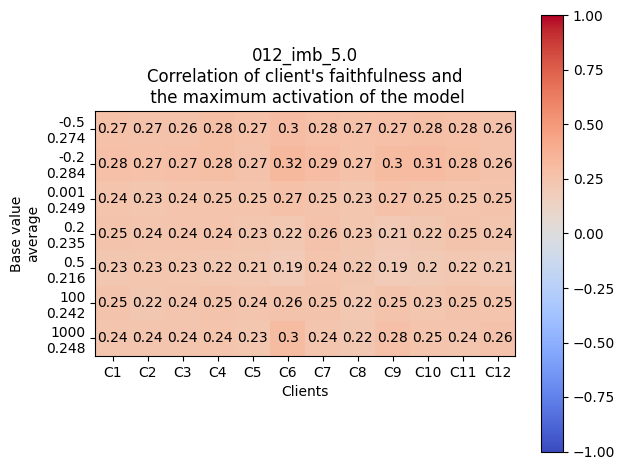

012_iid


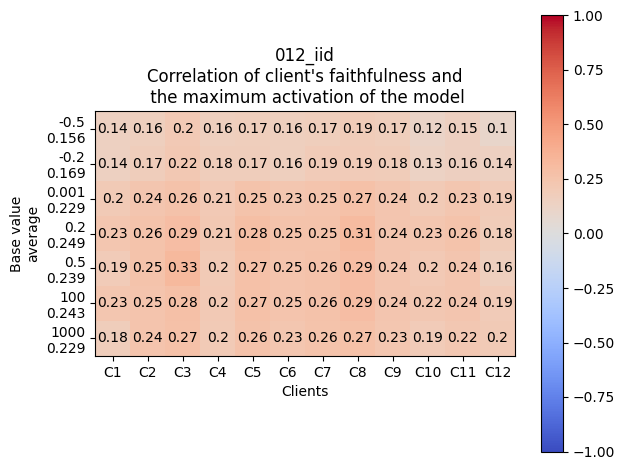

016_imb_0.99
	 -0.5 (0.3072199762240345, 0.2294712992805582, 0.03335289186721182)
	 -0.2 (0.32236238068814543, 0.22586274127227102, 0.03362520080616128)
	 0.001 (0.3311427237025595, 0.24418906575639804, 0.03473713840945581)
	 0.2 (0.3052772310293911, 0.24982907911868368, 0.03430904057090596)
	 0.5 (0.319966113959787, 0.27779064213264504, 0.02345135740936398)
	 100 (0.3057487632410464, 0.24994426289842803, 0.03267893972434587)
	 1000 (0.30682927502094515, 0.24427928937831328, 0.048825015593641025)

016_imb_5.0
	 -0.5 (0.27843398491353144, 0.24437809920392403, 0.01636253478097546)
	 -0.2 (0.2854127265328773, 0.23239943809612462, 0.02075295051850338)
	 0.001 (0.24835188300713665, 0.22481575506302737, 0.01221874228727396)
	 0.2 (0.27796380437429313, 0.23962316334737416, 0.018578960517534153)
	 0.5 (0.301574953189958, 0.24572167870112113, 0.026133839864265488)
	 100 (0.259948686172594, 0.2279030929054982, 0.015121827624666177)
	 1000 (0.2567875450545142, 0.23261465735719222, 0.0144986316422

In [120]:
# this function is used to find a correlation between the faithfulness of the clients and the activations of the model
def plot_correlation(exp,faithfulnesses,activations,show=True,):
    '''this function is used to find a correlation between the faithfulness of the clients and the activations of the model.
    We iterate over all the clients. We compute the correlation of the faithfulness of the clients and the maximum activation of the model.'''
    dt,nc,distr = get_dt_name_nc_d(exp)
    #test_set = load_test_partitions(dt_name,nc,distr)
    partitions_te_set = load_test_partitions(dt_name, nc, distr)
    loader_explain, _ = create_dataloader((
                                            cap_dataset((partitions_te_set.tensors[0],
                                                        partitions_te_set.tensors[1]),
                                                        2000)
                                            ),batch_size=32, shuffle=False)
    explanation_set = np.load(os.path.join("Experiments",dt_name,"explanation_set.npz"))
    # create the dataloader transforming the dataset in a tensor dataset
    explan_dataset = torch.utils.data.TensorDataset(torch.Tensor(explanation_set['features']),
                                                    torch.Tensor(explanation_set['labels']))
    loader_explain, _ = create_dataloader(explan_dataset,batch_size=32, shuffle=False)
    test_set = loader_explain.dataset
    #print(test_set.tensors[0].shape)
    #print(test_set.tensors[1].shape)
    # get the faithfulness of the clients
    faithfulnesses = faithfulnesses["Clients"].T
    # for each client, we compute the correlation of the faithfulness of the clients and the maximum activation of the model
    #print(faithfulnesses.shape)
    correlations = []
    for i in range(faithfulnesses.shape[1]):
        # explude the nan values
        idxs = np.isnan(faithfulnesses[:,i])
        faithfulne = np.abs(faithfulnesses[~idxs,i])
        # get the truth values
        labs_te_set = test_set.tensors[1].argmax(axis=1)[~idxs]
        #outs = activations[~idxs,:][:,labs_te_set]
        # get the activations of the model that have faithfulness not nan
        outs = activations[~idxs,:]
        # get the maximum activation of the model for the truth values
        outs = outs[:,labs_te_set]
        #print(labs_te_set.shape,outs.shape)
        
        # compute the correlation taking into account the truth values
        # so we compute the correlation of the faithfulness and the "error" of the model, so that we can see if the faithfulness is higher when the model is wrong or the other way around
        
        #iterating over the classes
        correlations_c = []
        for i in range(labs_te_set.max()+1):
            class_idx = labs_te_set == i
            #print(faithfulne[class_idx].shape,outs[class_idx,i].shape)
            cor = np.corrcoef(faithfulne[class_idx],outs[class_idx,i])[0,1]
            correlations_c.append(cor)



        #print(correlations_c)
        # take the absolute value of the correlations per class and aggregate them
        cor = np.mean(np.abs(correlations_c))

        # for the article, the formula of the correlation is the following
        '''
        $$
        \frac{1}{|C|}\Sigma_{c\inC}|\rho(faithfulness_{c},activation_{c})|
        $$
        where $C$ is the number of classes, $c$ is the class, $\rho$ is the correlation, $faithfulness_{c}$ is the faithfulness of the class $c$, and $activation_{c}$ is the activation of the class $c$
        '''
        
        #print(cor.shape)
        #cor = cor[0,1]

        correlations.append(cor)
    return correlations
    
plot_correlation(     "012_imb_0.99",
       all_faith_dict["012_imb_0.99"][b_v],
activations_of_models["012_imb_0.99"][0.2])

# now do it for all the experiments
correlations = {}
for exp in all_faith_dict.keys():
    print(exp)
    correlations[exp] = {}
    matrix_image = np.zeros((len(all_faith_dict[exp].keys()),len(all_faith_dict[exp][0.5]["Clients"])))
    for j,value in enumerate(sorted(all_faith_dict[exp].keys())):
        cor = plot_correlation(exp,
                           faithfulnesses=all_faith_dict[exp][value],
                           activations=activations_of_models[exp][0.2])
        matrix_image[j]=cor
        correlations[exp][value] = (np.max(np.abs(cor)),np.mean(cor),np.std(cor))
    # plot the correlation as a matrix 
    plt.imshow(matrix_image,interpolation='none',cmap='coolwarm',vmin=-1,vmax=1)
    # place the values of the correlation in the cells
    plt.colorbar()
    for i in range(matrix_image.shape[0]):
        for j in range(matrix_image.shape[1]):
            plt.text(j,i,round(matrix_image[i,j],2),ha='center',va='center')

    means = np.mean(matrix_image,axis=1)

    plt.xlabel("Clients")
    plt.ylabel("Base value\naverage")
    plt.title(exp+"\nCorrelation of client's faithfulness and\n the maximum activation of the model")
    plt.xticks(np.arange(len(all_faith_dict[exp][0.5]["Clients"])),["C"+str(i+1) for i in range(len(all_faith_dict[exp][0.5]["Clients"]))])
    plt.yticks(np.arange(len(all_faith_dict[exp].keys())),
               ["\n".join([str(e1) for e1 in e]) for e in list(zip(sorted(all_faith_dict[exp].keys()),
            [str(m)[:5] for m in means]))]
    )
    
    # place the mean of the correlation on the right
    # get the yaxes on the right and place the mean of the correlation there
    
    plt.tight_layout()
    plt.savefig(dt_name+"_"+exp+"_correlation_of_faithfulness_and_activation.pdf")
    plt.show()
    
for k in correlations.keys():
    print(k)
    for k1 in correlations[k].keys():
        print("\t",k1,correlations[k][k1])
    print()
    #break

: 

: 

In [ ]:
'''for exp in focus:
    print("Experiment:",exp)
    results_dict = all_faith_dict[exp]
    indices = indexes_per_calss[exp]
    activations = activations_of_models[exp]


    # plot the table of the faithfulness values
    vals, f_means = plot_table(results_dict,class_idxs=indices,threshold=0.7,exp=exp,show=True)

    # get the index of the best base value based on the mean of the faithfulness values that are above 0.7
    best_idx = np.argmax(f_means[:,1])
    best_val = vals[best_idx]

    # now best_val is always 0.2
    best_val = -0.2
    best_idx = np.argwhere(vals==best_val).flatten()

    print("best base value:",best_val,"percentage of faithfulness values above 0.7:",f_means[best_idx,1],"% (above 0:",f_means[best_idx,0],"%)")

    # plot the faithfulness of the explanations )(histogram and percentage bars)
    plot_faithfulness_histograms_and_thresholds(results_dict[best_val],best_val,show=True)
    
    # the stripes 
    plot_faith(exp,results_dict[best_val],test_set,activations[best_val]**2,show_samples=75,chosen_idxs=indices,show=True)

    # plot curves of the std of the faithfulness of the clients
    policy_selection(exp,faithfulnesses=results_dict[best_val],class_idxs=indices,show=True)
    # result from the sweep aka optimal configuration is stored in the report folder
    # under the name "Optimal_" + dt_name + exp + ".pdf"
    
    plt.close()
    plt.clf()
'''

'for exp in focus:\n    print("Experiment:",exp)\n    results_dict = all_faith_dict[exp]\n    indices = indexes_per_calss[exp]\n    activations = activations_of_models[exp]\n\n\n    # plot the table of the faithfulness values\n    vals, f_means = plot_table(results_dict,class_idxs=indices,threshold=0.7,exp=exp,show=True)\n\n    # get the index of the best base value based on the mean of the faithfulness values that are above 0.7\n    best_idx = np.argmax(f_means[:,1])\n    best_val = vals[best_idx]\n\n    # now best_val is always 0.2\n    best_val = -0.2\n    best_idx = np.argwhere(vals==best_val).flatten()\n\n    print("best base value:",best_val,"percentage of faithfulness values above 0.7:",f_means[best_idx,1],"% (above 0:",f_means[best_idx,0],"%)")\n\n    # plot the faithfulness of the explanations )(histogram and percentage bars)\n    plot_faithfulness_histograms_and_thresholds(results_dict[best_val],best_val,show=True)\n    \n    # the stripes \n    plot_faith(exp,results_dict[be

: 

In [ ]:
import importlib
import iflash as flx
from iflash import *
#
importlib.reload(flx)


: 

['C16', 'C12', 'C5', 'C7', 'C1', 'C4', 'C15', 'C10', 'C13', 'C2', 'C14', 'C6', 'C9', 'C8', 'C11', 'C3']
['E_hat', 'E_weighted', 'E_fait_weighted', 'E_fait_weighted_50_percentile', 'E_mixed', 'E_mixed06', 'E_france_0_6']
[(2000, 12), (2000, 12), (2000, 12), (2000, 12), (2000, 12), (2000, 12), (2000, 12)]


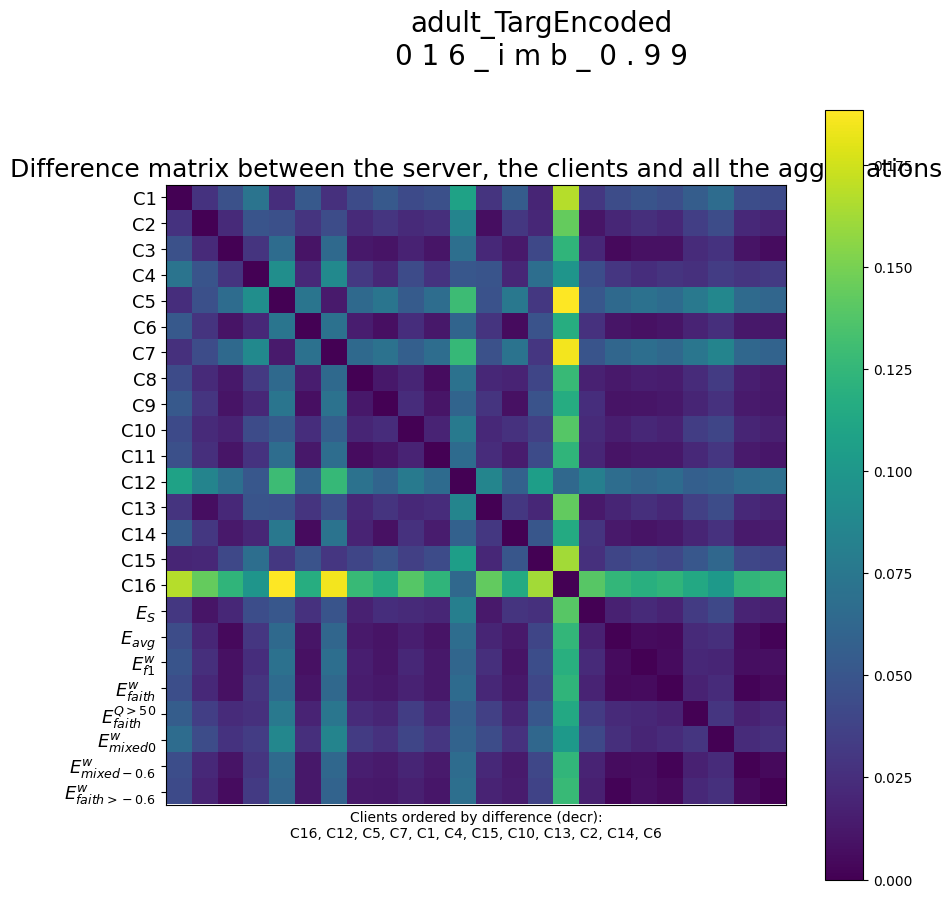

['C7', 'C14', 'C3', 'C16', 'C8', 'C10', 'C6', 'C11', 'C1', 'C13', 'C15', 'C9', 'C5', 'C4', 'C2', 'C12']
['E_hat', 'E_weighted', 'E_fait_weighted', 'E_fait_weighted_50_percentile', 'E_mixed', 'E_mixed06', 'E_france_0_6']
[(2000, 12), (2000, 12), (2000, 12), (2000, 12), (2000, 12), (2000, 12), (2000, 12)]


<Figure size 640x480 with 0 Axes>

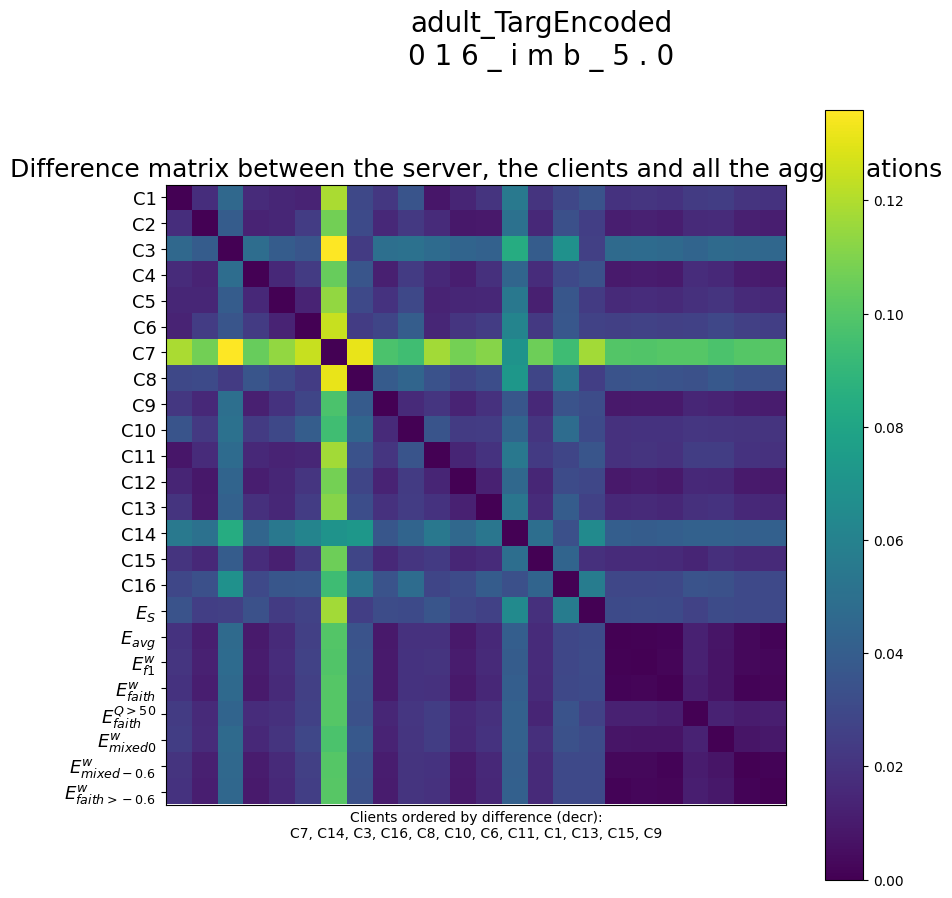

['C6', 'C4', 'C5', 'C15', 'C2', 'C3', 'C10', 'C9', 'C11', 'C16', 'C12', 'C1', 'C14', 'C13', 'C8', 'C7']
['E_hat', 'E_weighted', 'E_fait_weighted', 'E_fait_weighted_50_percentile', 'E_mixed', 'E_mixed06', 'E_france_0_6']
[(2000, 12), (2000, 12), (2000, 12), (2000, 12), (2000, 12), (2000, 12), (2000, 12)]


<Figure size 640x480 with 0 Axes>

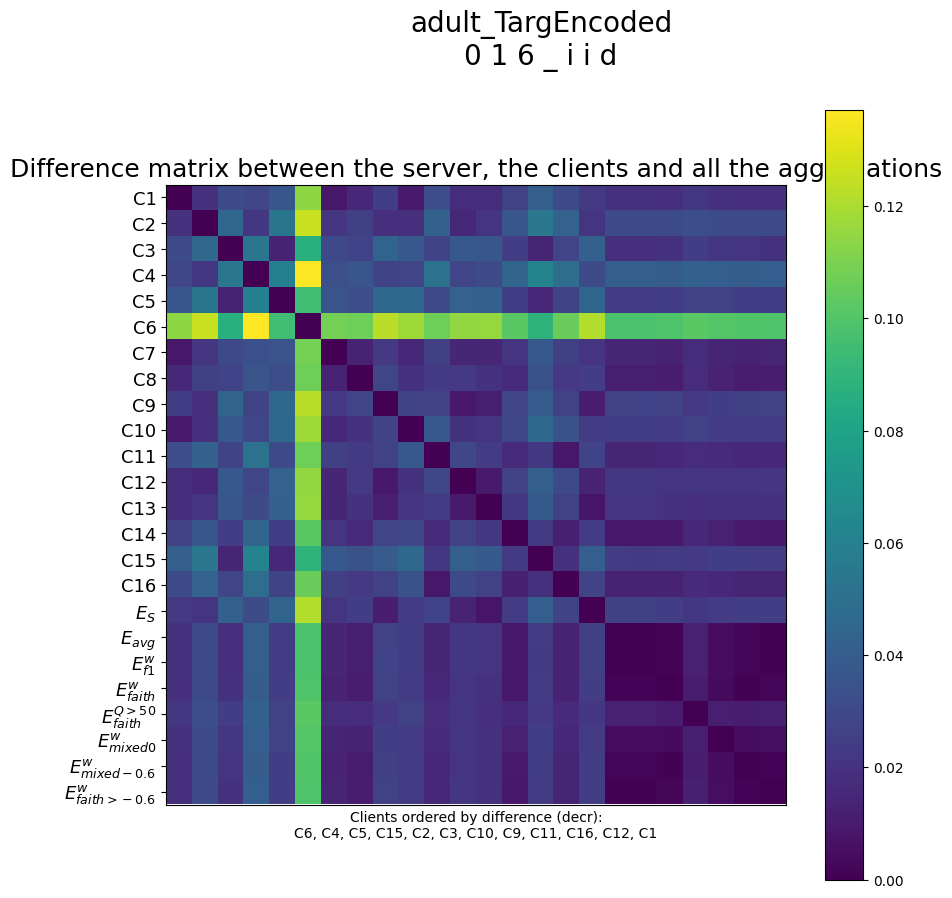

['C2', 'C5', 'C12', 'C8', 'C10', 'C11', 'C7', 'C6', 'C3', 'C9', 'C4', 'C1']
['E_hat', 'E_weighted', 'E_fait_weighted', 'E_fait_weighted_50_percentile', 'E_mixed', 'E_mixed06', 'E_france_0_6']
[(2000, 12), (2000, 12), (2000, 12), (2000, 12), (2000, 12), (2000, 12), (2000, 12)]


<Figure size 640x480 with 0 Axes>

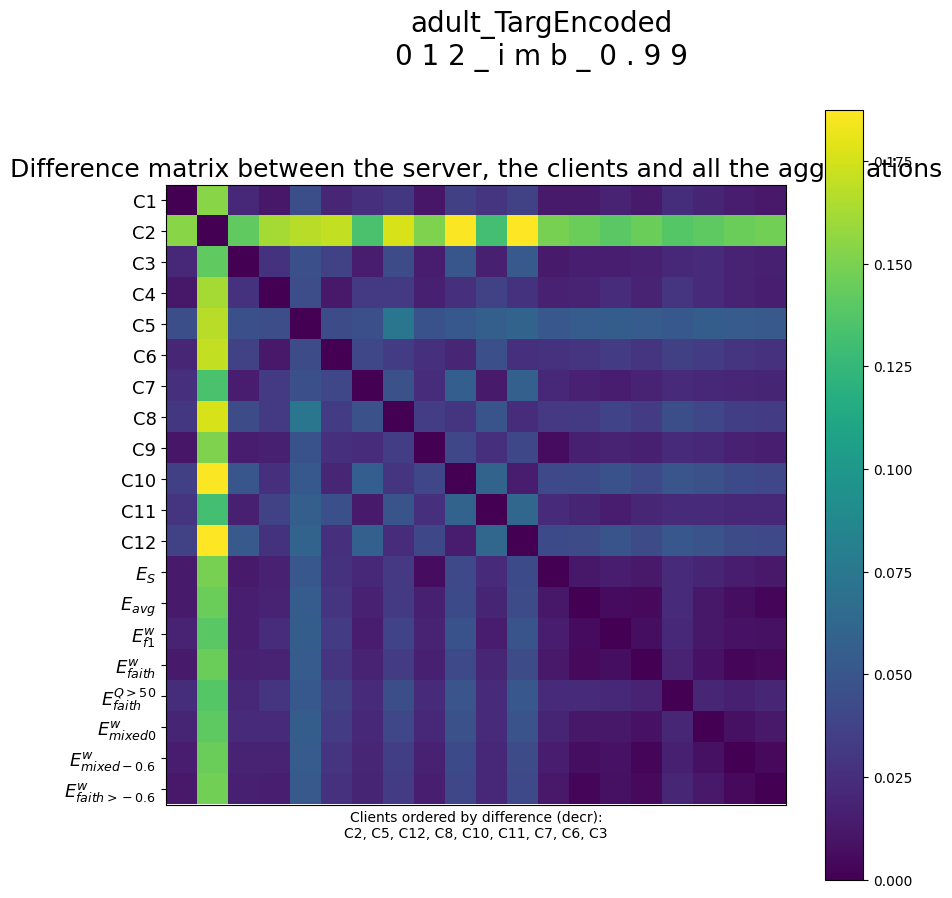

['C12', 'C3', 'C6', 'C9', 'C11', 'C2', 'C1', 'C7', 'C4', 'C8', 'C5', 'C10']
['E_hat', 'E_weighted', 'E_fait_weighted', 'E_fait_weighted_50_percentile', 'E_mixed', 'E_mixed06', 'E_france_0_6']
[(2000, 12), (2000, 12), (2000, 12), (2000, 12), (2000, 12), (2000, 12), (2000, 12)]


<Figure size 640x480 with 0 Axes>

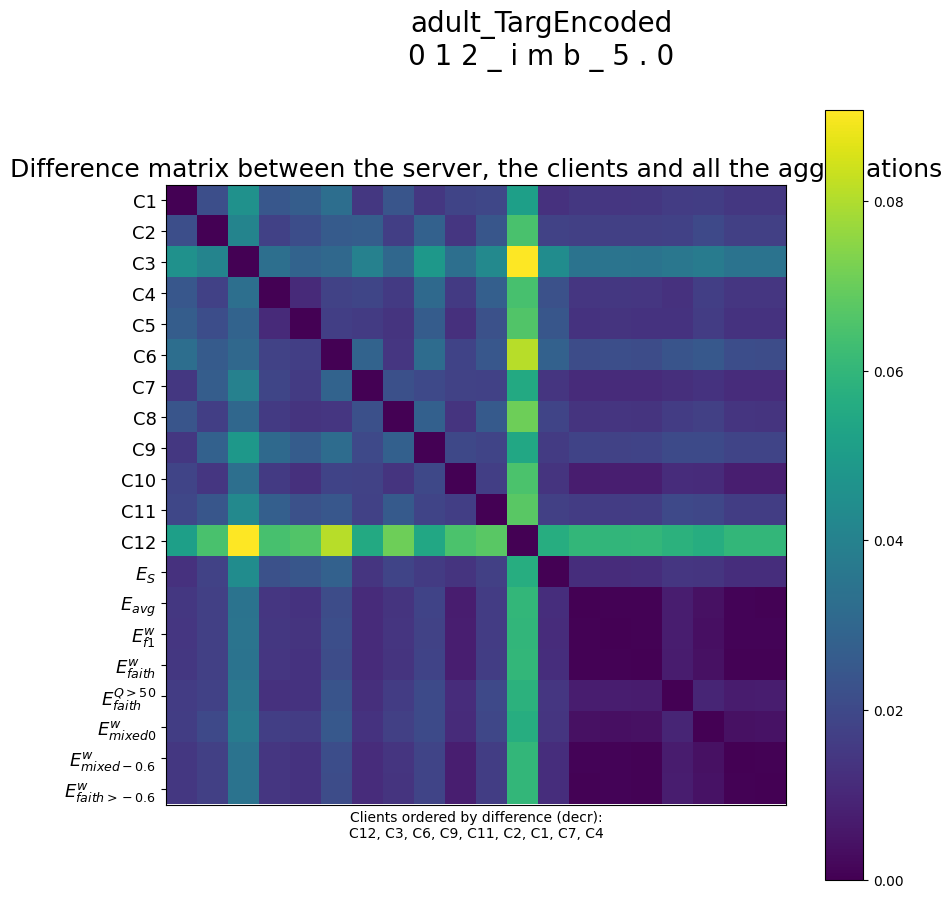

['C4', 'C8', 'C11', 'C2', 'C3', 'C9', 'C5', 'C12', 'C7', 'C1', 'C6', 'C10']
['E_hat', 'E_weighted', 'E_fait_weighted', 'E_fait_weighted_50_percentile', 'E_mixed', 'E_mixed06', 'E_france_0_6']
[(2000, 12), (2000, 12), (2000, 12), (2000, 12), (2000, 12), (2000, 12), (2000, 12)]


<Figure size 640x480 with 0 Axes>

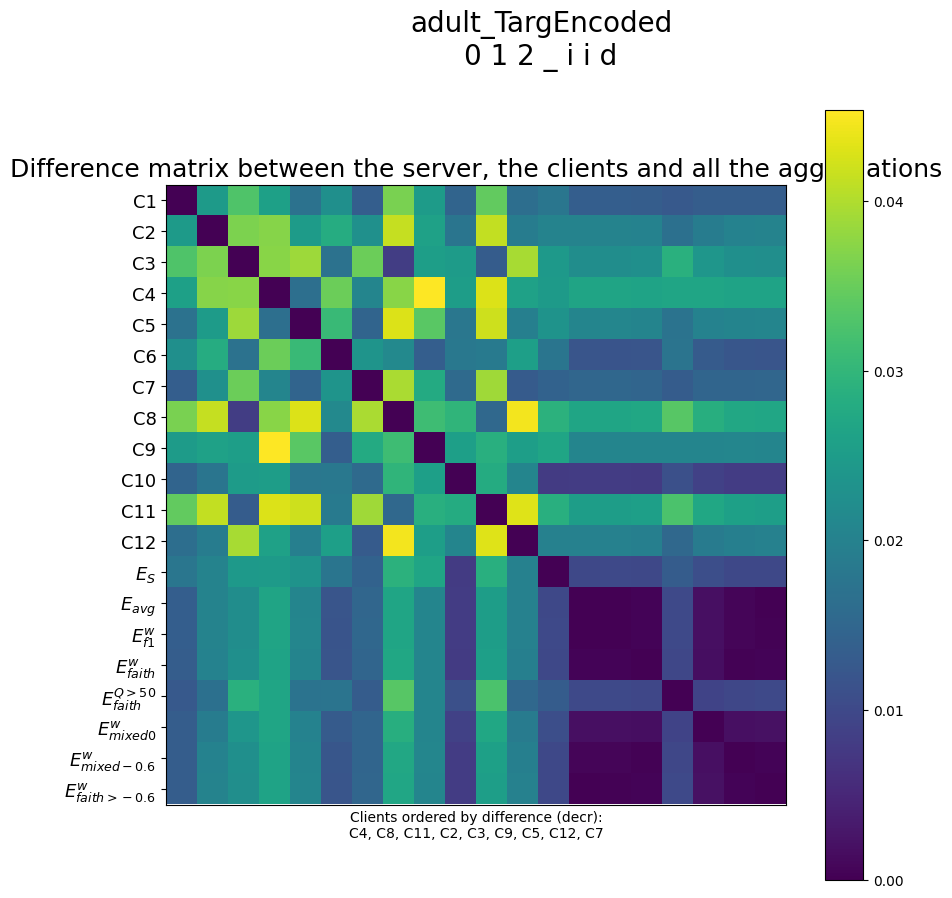

<Figure size 640x480 with 0 Axes>

: 

In [ ]:
for exp in focus:
    fig,ax = plt.subplots(1,1,figsize=(10,10))
    plot_differences(dictionary = all_shap_values_dict_loaded[exp],
                    proposals=props,
                    axes=ax,
                    colorbar = True)
    plt.suptitle(dt_name+"\n"+" ".join([str(elemento) for elemento in exp]),fontsize=20)
    ax = plt.gca()
    ax.set_title("Difference matrix between the server, the clients and all the aggregations",fontsize=18)
    plt.savefig("_".join([dt_name,exp])+"_difference_matrix.pdf")
    plt.show()
    plt.close()
    plt.clf()
    

016_imb_0.99


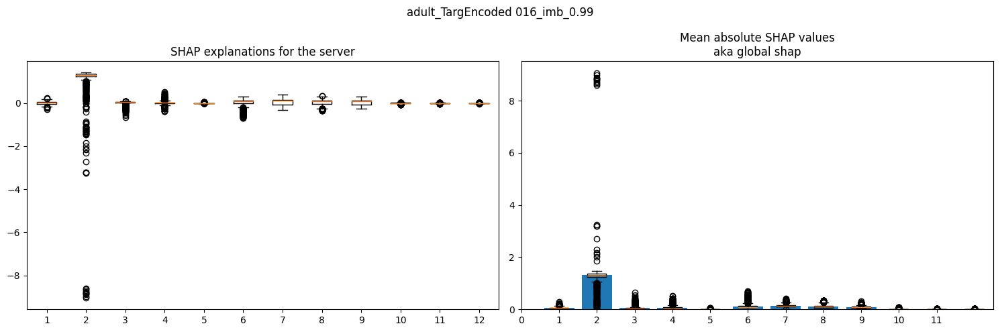

016_imb_5.0


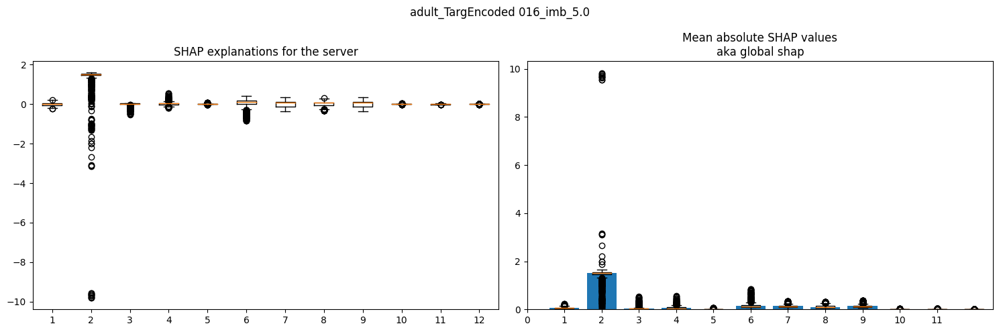

016_iid


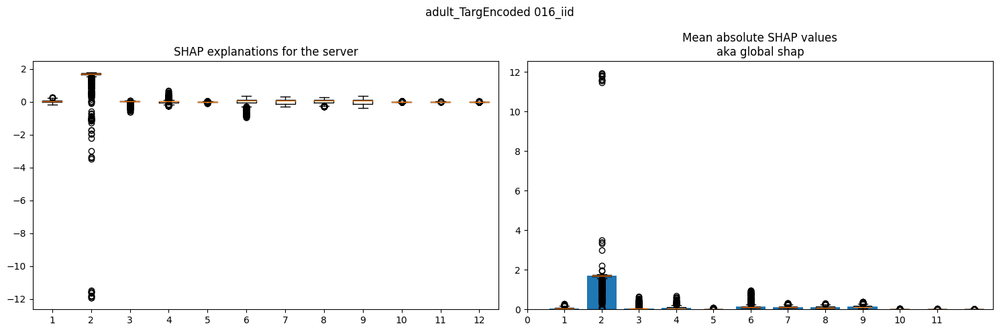

012_imb_0.99


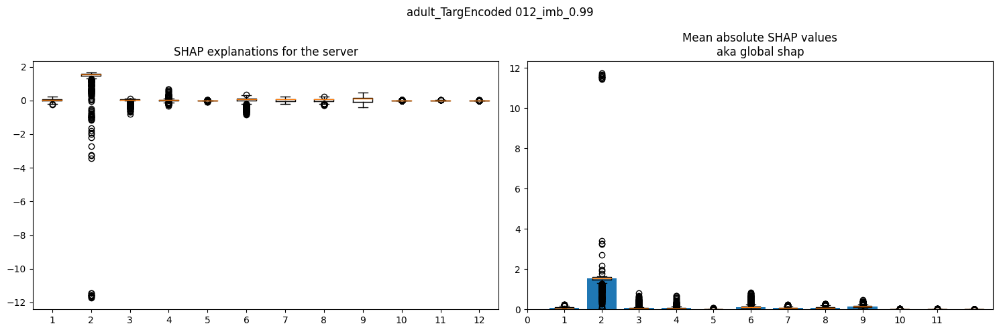

012_imb_5.0


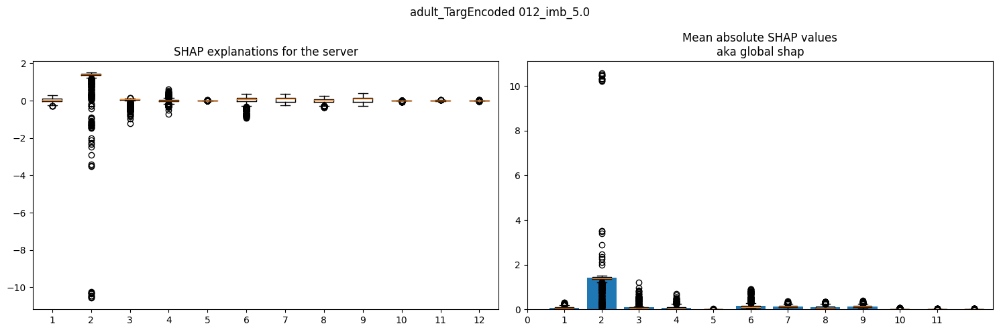

012_iid


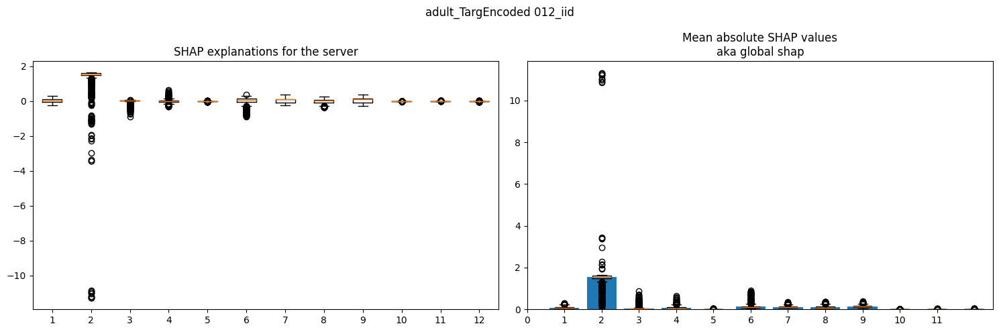

: 

In [ ]:
#from PyPDF2 import PdfMerger
# for a comparison 
# insert all the global explanation in a dataframe to plot them
import pandas as pd
import seaborn as sns

for exp in focus:
    if "004" in exp:
        continue
    else:
                print(exp)
                # load the model
                # plot it as barplots
                audit_expl = all_shap_values_dict_loaded[exp]["Server"]
                plt.figure(figsize=(15,5))
                plt.subplot(1,2,1)
                plt.title("SHAP explanations for the server")
                plt.boxplot(audit_expl)
                plt.subplot(1,2,2)
                plt.title("Mean absolute SHAP values\naka global shap")
                plt.boxplot(np.abs(audit_expl))
                plt.bar(np.arange(audit_expl.shape[1])+1,np.mean(np.abs(audit_expl),axis=0))
                plt.xticks(np.arange(audit_expl.shape[1]),[str(i) for i in range(audit_expl.shape[1])])
                #all_global_exp[(dist,p)] = np.mean(np.abs(audit_expl),axis=0)
                # the sup title should be the name of the dataset, epsilon (if in [1,2]) the name of the model, the number of nodes
                
                plt.suptitle(dt_name+" "+exp)
                plt.tight_layout()
                plt.show()



                


: 

saved in  adult_TargEncoded_0 1 6 _ i m b _ 0 . 9 9_faithfulness_distributions.pdf


<Figure size 640x480 with 0 Axes>

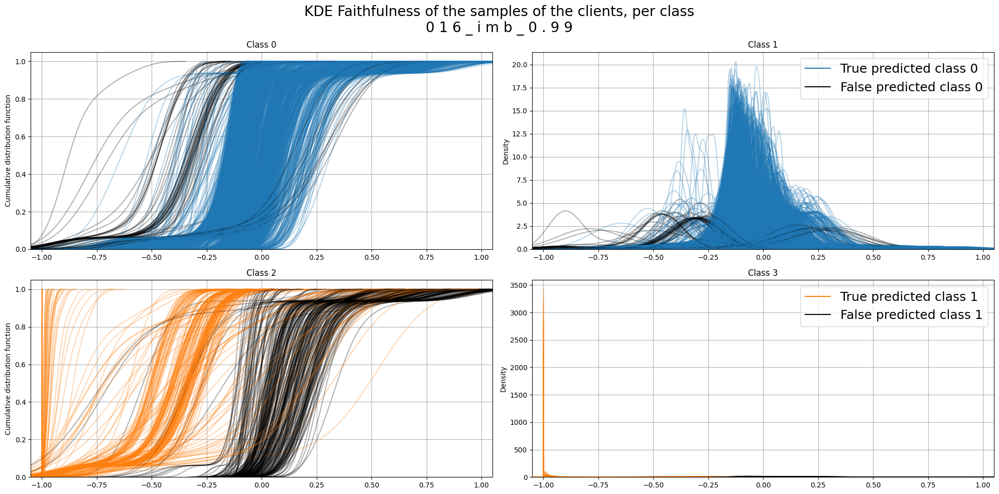

saved in  adult_TargEncoded_0 1 6 _ i m b _ 5 . 0_faithfulness_distributions.pdf


<Figure size 640x480 with 0 Axes>

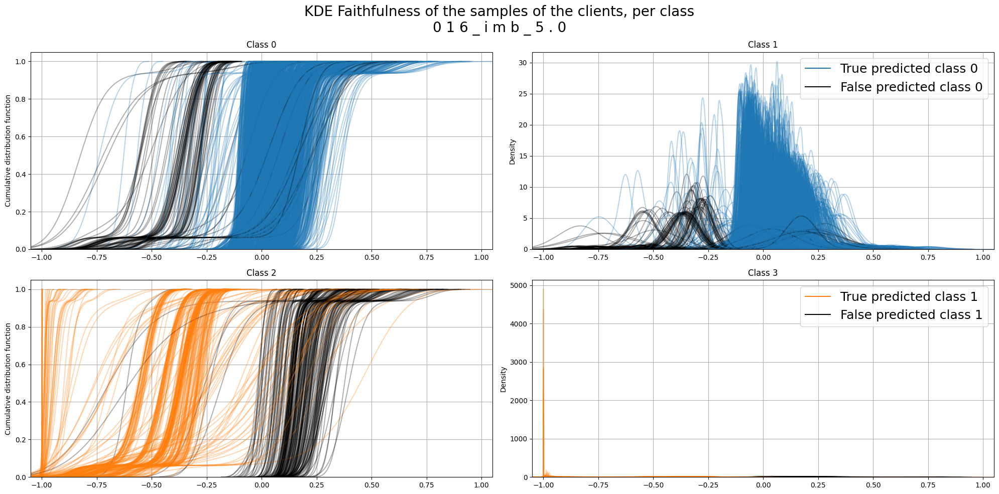

saved in  adult_TargEncoded_0 1 6 _ i i d_faithfulness_distributions.pdf


<Figure size 640x480 with 0 Axes>

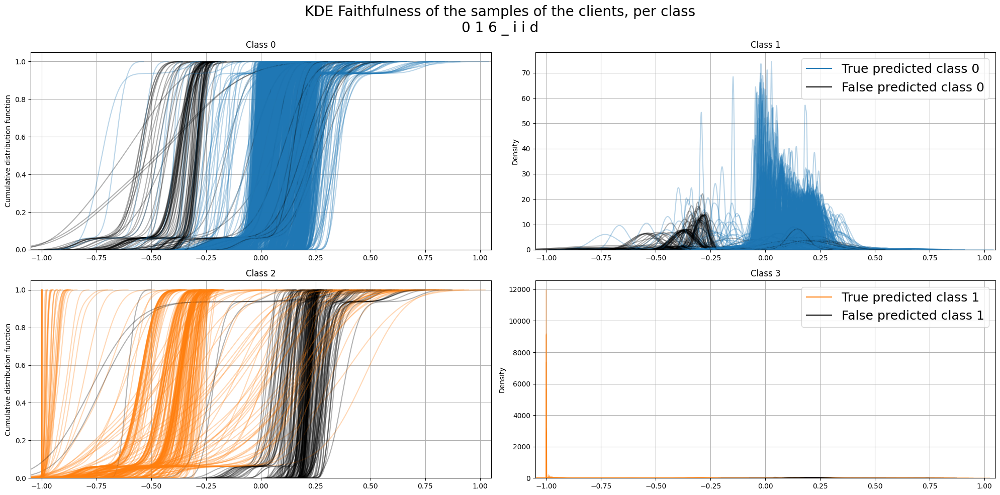

saved in  adult_TargEncoded_0 1 2 _ i m b _ 0 . 9 9_faithfulness_distributions.pdf


<Figure size 640x480 with 0 Axes>

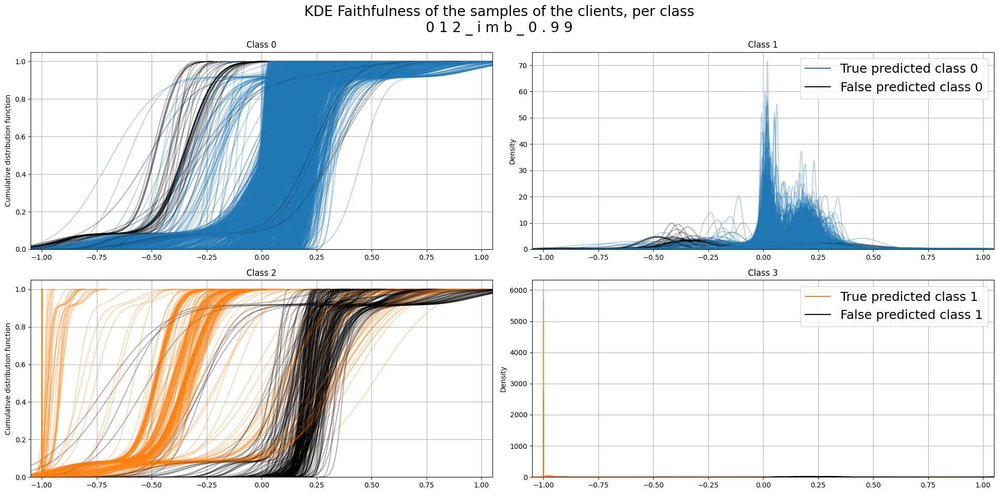

saved in  adult_TargEncoded_0 1 2 _ i m b _ 5 . 0_faithfulness_distributions.pdf


<Figure size 640x480 with 0 Axes>

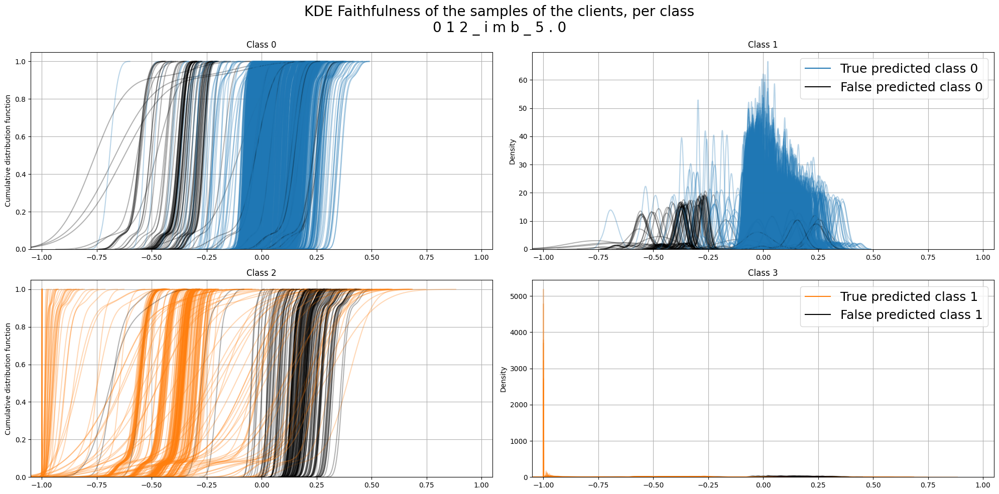

saved in  adult_TargEncoded_0 1 2 _ i i d_faithfulness_distributions.pdf


<Figure size 640x480 with 0 Axes>

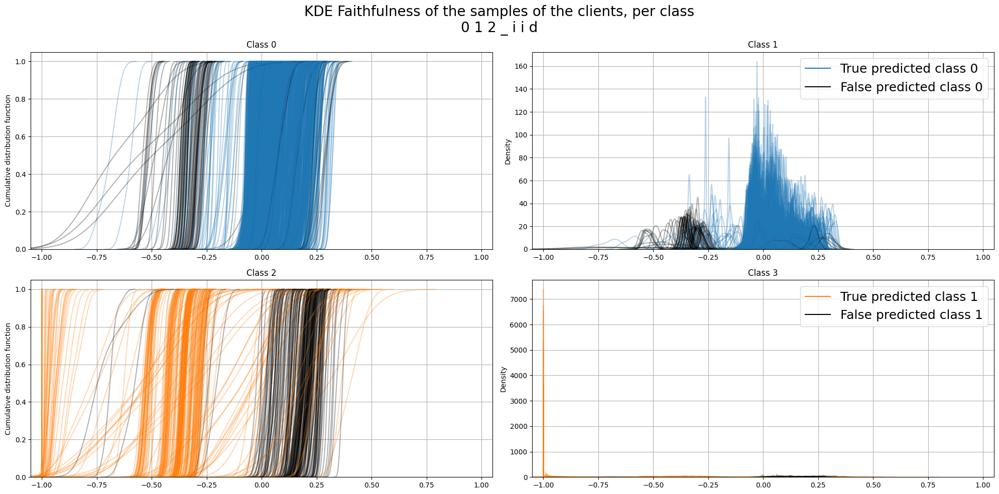

<Figure size 640x480 with 0 Axes>

: 

In [ ]:

for exp in focus:
    if "004" in exp:
        continue
    plt.clf()
    # plot the distributions of the faithfulness of every sample
    fig,ax = plt.subplots(len(indexes_per_calss_list[exp]),2,figsize=(20,5*len(indexes_per_calss_list[exp])))
    ax = ax.flatten()
    pred = activations_of_models[exp][b_v]
    for i,idxs in enumerate(indexes_per_calss_list[exp]):
        color = ['#1f77b4','#ff7f0e','#2ca02c','#d62728','#9467bd','#8c564b','#e377c2','#7f7f7f','#bcbd22','#17becf'][i]
        ax[2*i+1].plot([0,0],[0,0],color=color,label="True predicted class "+str(i))
        ax[2*i+1].plot([0,0],[0,0],color='k',label="False predicted class "+str(i))
        for idx in idxs:
            # check if it it a true positive or a false positive
            if pred[idx].argmax() != i:
                color = 'k'
            else:
                color = ['#1f77b4','#ff7f0e','#2ca02c','#d62728','#9467bd','#8c564b','#e377c2','#7f7f7f','#bcbd22','#17becf'][i]
            sns.kdeplot(all_faith_dict[exp][b_v]["Clients"].T[idx].flatten(),color = color,alpha=0.3,ax=ax[2*i],cumulative=True)
            sns.kdeplot(all_faith_dict[exp][b_v]["Clients"].T[idx].flatten(),color = color,alpha=0.3,ax=ax[2*i+1],cumulative=False)
        # add a fake line for the legend
        


    old_y_lim = plt.ylim()
    # add fake lines for the legend

    plt.suptitle("KDE Faithfulness of the samples of the clients, per class\n"+" ".join([str(elemento) for elemento in exp]),fontsize=20)
    for j,axe in enumerate(ax.flatten()):
        axe.set_xlim(-1.05,1.05)
        axe.grid(True)
        axe.set_title("Class "+str(j))
        if j%2==1:
            axe.legend(fontsize=18, loc='upper right')
            axe.set_ylabel("Density")
        else:
            axe.set_ylabel("Cumulative distribution function")


    plt.ylim(old_y_lim)
    plt.savefig(dt_name+"_"+" ".join([str(elemento) for elemento in exp])+"_faithfulness_distributions.pdf")
    print("saved in ",dt_name+"_"+" ".join([str(elemento) for elemento in exp])+"_faithfulness_distributions.pdf")
    plt.tight_layout()
    plt.show()
    plt.close()
    plt.clf()



: 

In [ ]:
for exp in focus:
    pdfs = [
            #dt_name+"_"+exp+"_faithfulness_tables.pdf",
            #exp+"_correlation_of_faithfulness_and_activation.pdf",
            #dt_name+"_"+exp+"_faithfulness_histograms.pdf",
            dt_name+"_"+exp+"_faithfulness_strides.pdf",
            dt_name+"_"+exp+"_std_of_faithfulness_values.pdf",
            dt_name+"_"+" ".join([str(el) for el in exp])+"_faithfulness_distributions.pdf",
            #dt_name+"_"+exp+"_faithfulness_vs_gap.pdf",
            dt_name+"_"+"_".join([str(el) for el in exp])+"_density_comparisons.pdf",# (?)
            #dt_name+"_"+exp+"_differences_global_explanation.pdf",
            dt_name+"_"+exp+"_global_explanation_by_class.pdf",
            #dt_name+"_"+exp+"_global_explanation.pdf",
            #dt_name+"_"+exp+"_result_table.pdf",
            #dt_name+"_"+exp+"_result_table_by_class.pdf",
            dt_name+"_"+" ".join([str(el) for el in exp])+"_CD_$ShapGap_{CosSim}$.pdf",
            dt_name+"_"+" ".join([str(el) for el in exp])+"_CD_$ShapGap_{Kendall}$.pdf",
            dt_name+"_"+" ".join([str(el) for el in exp])+"_CD_$ShapGap_{L2}$.pdf",
         
            dt_name+"_"+" ".join([str(el) for el in exp])+"_faithfulness_analysis_post.pdf"
            ]
    #if optimal exist append it
    print("looking for",os.path.join("reports",dt_name,"Optimal_" + dt_name +"_"+ exp + ".pdf"))
    if os.path.exists(os.path.join("reports",dt_name,"Optimal_" + dt_name +"_"+ exp + ".pdf")):
        pdfs.append(os.path.join("reports",dt_name,
                             "Optimal_" + dt_name +"_"+ exp + ".pdf"
                             )
        )
        print("perfomance report added")
    else: 
         # maybe the optimal is in the report folder
        if os.path.exists(os.path.join("reports","Optimal_" + dt_name +"_"+ exp + ".pdf")):
            pdfs.append(os.path.join("reports",
                             "Optimal_" + dt_name +"_"+ exp + ".pdf"
                             )
            )
            print("perfomance report added")
    #print("\n".join(pdfs))
    # check if the files exist
    for pdf in pdfs:
        if not os.path.exists(pdf):
                print(pdf)
                print("not found")
    # create the merger
    merger = PdfMerger()
    # append the pdfs
    for pdf in pdfs:
        merger.append(pdf)

    merger.write(dt_name+"_"+exp+"_zmerged.pdf")
    merger.close()
    print("correclty_merged in", dt_name+"_"+exp+"_zmerged.pdf")
    print()

    

looking for reports/adult_TargEncoded/Optimal_adult_TargEncoded_016_imb_0.99.pdf
correclty_merged in adult_TargEncoded_016_imb_0.99_zmerged.pdf

looking for reports/adult_TargEncoded/Optimal_adult_TargEncoded_016_imb_5.0.pdf
correclty_merged in adult_TargEncoded_016_imb_5.0_zmerged.pdf

looking for reports/adult_TargEncoded/Optimal_adult_TargEncoded_016_iid.pdf
correclty_merged in adult_TargEncoded_016_iid_zmerged.pdf

looking for reports/adult_TargEncoded/Optimal_adult_TargEncoded_012_imb_0.99.pdf
correclty_merged in adult_TargEncoded_012_imb_0.99_zmerged.pdf

looking for reports/adult_TargEncoded/Optimal_adult_TargEncoded_012_imb_5.0.pdf
correclty_merged in adult_TargEncoded_012_imb_5.0_zmerged.pdf

looking for reports/adult_TargEncoded/Optimal_adult_TargEncoded_012_iid.pdf
correclty_merged in adult_TargEncoded_012_iid_zmerged.pdf



: 

In [ ]:
# lasty we do a last thing. all_faith_dict_recomputed#
# we compute the global explanation, as the mean absolute value of the explanations of every class
# for every proposal we get a global explanation and compare those with the server
# at the end we will have 1 number per proposal. We do this using the frobenius norm and the kendalltau
def get_global_explanation(exp,all_shap_values_dict,original_indices,activations_of_models,proposals):
    '''this function is used to compute the global explanation of the model. In this context there is not a difference between the server and the clients. The global explanation is the average of the explanations by class of the samples.
    This will be used to further compare the explanations of the server and the aggregation strategies of the clients'''
    g_expl_by_class = []
    g_expl_by_class_proposals = {}
    # get the activations of the model for the samples of that predicted class
    get_g_expl = lambda x,selected_idx : np.mean([np.abs(all_shap_values_dict[exp][x][i]) for i in selected_idx],axis=0)
    get_g_expl = lambda x,selected_idx : np.mean([all_shap_values_dict[exp][x][i] for i in selected_idx],axis=0)

    for cl_id,class_idxs in enumerate(original_indices):
        #class_idxs = original_indices[activas.argmax(axis=1)[0]]
        predicted = cl_id
        # class_idx contains the indexes of the samples predicted as the class
        class_idxs = np.where(activas.argmax(axis=1)==predicted)[0]

        # compute the average of the explanations of the samples of that class
        expl =get_g_expl("Server",class_idxs)
        g_expl_by_class.append(expl)
        # repeat the same computation for every proposal
        for p in proposals:
            if p not in g_expl_by_class_proposals:
                g_expl_by_class_proposals[p] = []
            expl = get_g_expl(p,class_idxs)
            #print(expl.shape,"shape of the explanation, it should be the same as the features per sample")
            g_expl_by_class_proposals[p].append(expl)

    # compute the global explanation
    #g_expl = np.average(g_expl_by_class,axis=0)
    return np.array(g_expl_by_class),{k:np.array(v) for k,v in g_expl_by_class_proposals.items()}

: 

: 

In [ ]:
focus

['016_imb_0.99',
 '016_imb_5.0',
 '016_iid',
 '012_imb_0.99',
 '012_imb_5.0',
 '012_iid']

: 

: 

: 

: 

: 